# Trafo Bazlı Günlük Elektrik Tüketimi Tahmini

Public LB 1,00005 · Private 0,99687 · 12. sıra. Bireysel katılım.

Nisan-Temmuz 2026 arasında, dağıtım şebekesindeki her trafonun her
günkü aktif tüketimini (kWh) tahmin ediyorum. Elimdeki geçmiş Ocak
2025 ile Mart 2026 arası. Metrik RMSLE, yani `log1p` uzayında RMSE.

### Varsayımlar

Yarışma dış veri kullanımına izin veriyor ve kaynakların belirtilmesini
istiyor. Uyduğum kurallar şunlar:

* İleri yönlü sızıntı kullanmadım. Bir tahmin gününün hiçbir
  özelliğinde o günden sonraki gözlem yok. Bunu beyan olarak değil, kod
  içinde `assert` ile denetliyorum (bölüm 2.3).
* Hava durumu ve takvim verisini tahmin günüyle aynı tarihte
  kullandım, gecikmesiz. Gerekçem şu: kısa vadeli hava tahmini
  gerçek kullanımda da elde oluyor, bir dağıtım şirketi yarının
  sıcaklık tahminine bugünden sahip. Takvim zaten deterministik.
* EPİAŞ Şeffaflık verilerini bilerek kullanmadım. Gerçekleşen
  sistem tüketimi, üretim ve piyasa takas fiyatı serileri tahmin
  dönemine ait gerçekleşmeleri içeriyor; bir şirket Nisan 2026
  tahminini yaparken Temmuz 2026'nın gerçekleşenini bilemez. Bu kararın
  skora maliyetini ölçtüm, yaklaşık 0,00017 RMSLE, ve bilerek ödedim
  (bölüm 7.1).
* Notebook internet erişimi kapalıyken de baştan sona koşar, çünkü
  çalışma anında hiçbir dış kaynağa bağlanmıyor.

### Kullanılan Dış Veriler

İki dış kaynak kullandım. İkisi de tek bir günlük tabloda birleştirilmiş
hâlde repoda durur: `data/notebook_dis_veri/gun_tablo.csv`, 627 gün ve
56 sütun. Sütunların 27'si havadan, 28'i takvimden gelir ve tarih
dışındaki tamamı günlük endeksin Ridge girdisine verilir.

| Kaynak | Ne sağlıyor | Nerede kullanılıyor |
|---|---|---|
| [Open-Meteo](https://open-meteo.com/) arşiv ve tahmin | İki il için günlük sıcaklık (ortalama, en düşük, en yüksek, hissedilen), ısıtma ve soğutma derece günü, ışınım, nem, bulut, rüzgar ve yağış. | Günlük endeks, bölüm 4.1. |
| [holidays](https://pypi.org/project/holidays/) paketi | Türkiye resmi ve dini tatilleri, arife ve köprü günleri, bayram uzunluğu ve bayram içindeki gün sırası, okul dönemi, turizm ve sulama sezonu. | Günlük endeks (bölüm 4.1) ve tatil düzeltmesi (bölüm 4.2). |

Takvim sütunlarının bir kısmı ileriye bakar; bir sonraki tatile kaç gün
kaldığı bunlardan biridir. Bu bir leakage değildir, çünkü takvim
yıllar öncesinden bellidir ve tahmin gününde de bilinir.

[EPİAŞ Şeffaflık](https://seffaflik.epias.com.tr/) verilerini bilerek
kullanmadım; gerekçesi yukarıdaki varsayımlarda, denetimi bölüm
7.1'dedir.

## İçindekiler

| Bölüm | İçerik |
|---|---|
| 0 | Çözümün özeti, simgeler ve çalışma ortamı. |
| 1 | Veri keşfi ve hatanın nerede olduğu. |
| 2 | Validation şeması ve leakage kapıları. |
| 3 | Çözümün mimarisi: nihai denklem, bileşenler ve eğitilen modeller. |
| 4 | Günlük endeks ve trafo seviyesi. |
| 5 | Geçmişi olmayan trafolar için cross-sectional model. |
| 6 | Düzeltme yönleri ve katsayıların cross-validation ile çözülmesi. |
| 7 | Leakage ve dış veri denetimi. |
| 8 | Denenip kapatılan yollar. |
| 9 | Tahminin üretilmesi, nihai sonuç ve aşırı uyum denetimi. |
| 10 | Sonuç, geliştirme yönleri ve yeniden üretilebilirlik. |

## 0. Çözümün Özeti

### Tahmin Hedefi

Girdide beş sütun bulunur: trafo kimliği (`tanim`), kurulu güç (`guc`,
kVA), tarih (`tarih`), konum (`lokasyon`, il > bölge > ilçe biçiminde)
ve eğitim tarafında hedef (`tuketim`, kWh). Çıktı, test kümesindeki her
`id` için bir tüketim tahminidir.

### Yaklaşım

Tahmin tek bir modelin çıktısı değildir. Her trafo için mevsimden
arındırılmış bir seviye kestiririm, bunu takvim ve hava verisinden
öngördüğüm bir günlük endeksle toplarım, üstüne de her biri belirli bir
hata mekanizmasını hedefleyen düzeltmeler eklerim. Düzeltmelerin
ağırlıklarını elle seçmem; cross-validation artığından kapalı formla
çözerim. Bileşenlerin tamamı ve nerede kuruldukları bölüm 3'te tek
sayfada toplanmıştır.

### Kazancın Kaynağı

Hatanın nerede olduğunu ölçtüm. Test satırlarının beşte biri eğitim
verisinde hiç görünmeyen bir trafoya aittir ve hatanın yaklaşık üçte
ikisi oradan gelir. Kazancın neredeyse tamamı seviye ve endeks
formülünden çıkar; düzeltme yönleri onun üstüne küçük bir rafinaj
ekler.

### Kapsam

Notebook çözümün tamamını kurar. Veriyi okur, keşfi yapar, validation
şemasını kurar, endeksi ve seviyeyi kestirir, geçmişi olmayan trafolar
için cross-sectional modeli eğitir, düzeltme yönlerini kurar,
katsayılarını cross-validation ile çözer ve `submission.csv` üretir.

Ölçüm penceresinde elde edilen sayılar şunlardır:

| Adım | RMSLE |
|---|---|
| Naif taban | 1,0867 |
| Seviye ve endeks formülü. | 0,9240 |
| Cross-validation katsayılarıyla düzeltilmiş. | 0,9179 |

Son satır, gönderim dosyasını üreten tahmin edicinin skorudur. Bölüm
6.2 aynı düzeltmeleri tek bir pencerede çözer ve 0,8990 gösterir; o
sayı teşhis amaçlıdır ve iyimserdir, çünkü katsayılar ölçüldükleri
satırlardan çözülmüştür. Aradaki fark bölüm 9.3'te ölçülür.

### 0.1 Simgeler ve Terimler

Kullandığım gösterimi baştan tanımlıyorum, çünkü aynı formüller bölüm
3, 5 ve 8'de tekrar ediyor.

| Simge | Ne demek | Nerede kuruluyor |
|---|---|---|
| $y_{i,t}$ | $i$ trafosunun $t$ günündeki tüketimi, kWh. Tahmin etmem istenen büyüklük | Hedef |
| $L_{i,t}=\log(1+y_{i,t})$ | Hedefin `log1p` dönüşümü. Metrik RMSLE olduğu için bütün model bu uzayda çalışıyor. | Bölüm 1.1 |
| $m_t$ | **günlük endeks**: $t$ gününde bütün trafoları aynı yönde etkileyen mevsim ve takvim etkisi. Trafodan bağımsız, tek bir sayı dizisi | Bölüm 4.1 |
| $\mathrm{ham}_i$ | Trafonun endeksten arındırılmış gözlemlerinin yaşlanma ağırlıklı ortalaması. Büzülme uygulanmamış hâli. | Bölüm 4.2 |
| $W_i$ | **kanıt ağırlığı**: trafo hakkında elimdeki gözlemin yaşlanma sonrası toplam ağırlığı. Uzun geçmişte büyük, tek günlük geçmişte küçük | Bölüm 4.2 |
| $g_i$ | Trafonun ait olduğu grubun önceliği. Geçmişi olmayan trafoda bu terimi bölüm 5'ün kesitsel modeli üretiyor. | Bölüm 4.2, 4. |
| $h$ | **tahmin ufku**: tahmin edilen gün ile elimdeki son gözlem arasındaki gün sayısı | Bölüm 4.2 |
| $m(h)$ | Ufka bağlı büzülme ağırlığı. $h$ büyüdükçe trafonun kendi geçmişi bayatlıyor ve tahmin gruba kayıyor. | Bölüm 4.2 |
| $s_i$ | Trafonun nihai **seviyesi**: $\mathrm{ham}_i$ ile $g_i$'nin, $W_i$ ve $m(h)$ ağırlıklı ortalaması. | Bölüm 4.2 |
| $d_k(i,t)$ | $k$'ıncı **düzeltme yönü**: her satır için bir sayı üreten vektör. Tahmine bir katsayıyla ekleniyor | Bölüm 6.1 |
| $\alpha_k$ | O yönün katsayısı. Elle seçilmiyor, doğrulama artığından çözülüyor. | Bölüm 6.2 |
| $r$ | **taban artığı**: gerçek ile taban tahmin arasındaki fark, $L-\text{taban}$. Düzeltmeler bunu küçültmeye çalışıyor | Bölüm 6 |

Üç terimi de baştan tanımlayayım:

* Sınama tarihi: Geçmişi ikiye bölen gün. Öncesi model kurmak,
  sonrası ölçmek için kullanılıyor.
* Ölçüm penceresi: Sınama tarihinden sonraki 122 gün, yani gerçek
  tahmin ufkuyla aynı uzunlukta bir dilim.
* Geçmişsiz blok: Test satırlarının, trafosu eğitim verisinde hiç
  görünmeyen kısmı. Hatanın en pahalı parçası burası.

### 0.2 Çalışma Ortamı

* Yükü olmayan dört çekirdekli bir dizüstünde tam koşum yirmi beş
  dakika, zirve bellek 3,1 GB. Sürenin çoğunu iki bölüm alıyor: bölüm
  6.4 üç zaman katının zincirini baştan kuruyor, bölüm 9.2 aynı zinciri
  bütün eğitim verisiyle bir kez daha. Satır düzeyli ağaç yönleri
  ikisinde de yeniden eğitiliyor. Toplam süre ve zirve bellek bölüm
  9.3'te basılıyor.
* Ek kurulum gerekmiyor. Kullandığım beş kütüphanenin (pandas, numpy,
  matplotlib, LightGBM, CatBoost) hepsi Kaggle imajında hazır geliyor,
  notebook'ta tek bir `pip` satırı yok.
* Geliştirmeyi pandas 3.x ile yaptım, Kaggle çekirdeği 2.x kullanıyor.
  Kullandığım bütün API'lerin iki sürümde de çalıştığını ayrıca
  koşarak doğruladım.
* Sürümler aşağıdaki hücrede basılıyor.

In [1]:
import gc
import os
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

pd.set_option("display.width", 118)
plt.rcParams.update({"figure.figsize": (9.0, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 9})
BASLANGIC = time.time()


# Sürecin o andaki bellek kullanımı. psutil yoksa sessizce atlanıyor.

In [2]:
def bellek_gb():
    try:
        import psutil
        return psutil.Process().memory_info().rss / 1024 ** 3
    except Exception:
        return float("nan")


ZIRVE_BELLEK = bellek_gb()


# Kaggle, Colab ve yerel makine aynı notebook'la koşsun diye yol aranıyor.
# Yarışma klasörünün adına bağımlılık bırakmamak için train.csv aranıyor.
def veri_yolu():
    for kok in ("/kaggle/input", "data", "./data", "../data", "/content/data"):
        if not os.path.isdir(kok):
            continue
        if os.path.exists(os.path.join(kok, "train.csv")):
            return kok
        for alt in sorted(os.listdir(kok)):
            yol = os.path.join(kok, alt)
            if os.path.isdir(yol) and os.path.exists(os.path.join(yol, "train.csv")):
                return yol
    raise FileNotFoundError("train.csv bulunamadı")


BASE = veri_yolu()
train = pd.read_csv(os.path.join(BASE, "train.csv"), parse_dates=["tarih"])
test = pd.read_csv(os.path.join(BASE, "test.csv"), parse_dates=["tarih"])
train["L"] = np.log1p(train.tuketim.to_numpy())

In [3]:
# Lokasyon hiyerarşisi eşit derinlikte değil: İzmir üç seviyeli
# (İZMİR>METROPOL>KONAK), Manisa iki seviyeli. İlçe daima SON parça.
for _d in (train, test):
    _p = _d.lokasyon.str.split(">")
    _d["il"], _d["bolge"], _d["ilce"] = _p.str[0], _p.str[1], _p.str[-1]

Endeksin hava ve takvim girdisi tek bir günlük tabloda toplu. Tablo
bulunamazsa notebook durmuyor: takvimden türetilen bir yedek kuruluyor ve
koşum sonuna kadar gidiyor. Bu bilinçli, çünkü dış dosyaya bağımlı bir
notebook başkasının makinesinde ilk hücrede ölür.

In [4]:
# Günlük hava ve takvim tablosu, üç ortamda da aranıyor.
def gun_tablosu_yolu():
    adaylar = ["data/notebook_dis_veri/gun_tablo.csv",
               "./data/notebook_dis_veri/gun_tablo.csv",
               "../data/notebook_dis_veri/gun_tablo.csv",
               "/content/data/notebook_dis_veri/gun_tablo.csv"]
    if os.path.isdir("/kaggle/input"):
        for alt in sorted(os.listdir("/kaggle/input")):
            adaylar.append(os.path.join("/kaggle/input", alt, "gun_tablo.csv"))
    for a in adaylar:
        if os.path.exists(a):
            return a
    return None


_gt_yolu = gun_tablosu_yolu()
HAVA_VAR = _gt_yolu is not None
if HAVA_VAR:
    GUN_TABLO = pd.read_csv(_gt_yolu, parse_dates=["tarih"])
else:
    # Yedek tablo: yalnız takvimden türetilen sütunlar. Hava yok, ama endeks
    # yine kurulur ve notebook baştan sona koşar.
    _g = pd.DatetimeIndex(sorted(set(train.tarih) | set(test.tarih)))
    GUN_TABLO = pd.DataFrame({"tarih": _g})
    doy = GUN_TABLO.tarih.dt.dayofyear.to_numpy().astype(float)
    for k in (1, 2, 3):
        GUN_TABLO["sin%d" % k] = np.sin(2 * np.pi * k * doy / 365.25)
        GUN_TABLO["cos%d" % k] = np.cos(2 * np.pi * k * doy / 365.25)
    for c in ("dini_bayram", "resmi_tatil", "arife"):
        GUN_TABLO[c] = 0
    print("UYARI: günlük hava tablosu bulunamadı.")
    print("       Endeks yalnız takvimden kurulacak, sonuçlar bir miktar zayıf olur.")

_dg = GUN_TABLO.tarih.dt.dayofweek
for _g6 in range(6):
    GUN_TABLO["gun_%d" % _g6] = (_dg == _g6).astype(int)

In [5]:
# Endeksin girdi sütunları sabit; liste değişirse burada durur.
BEKLENEN_SUTUN = [
    "cdd_manisa", "cdd_izmir", "hdd_manisa", "hdd_izmir",
    "sicaklik_ort_manisa", "sicaklik_ort_izmir",
    "isinim_top_manisa", "isinim_top_izmir",
    "nem_ort_manisa", "nem_ort_izmir",
    "bulut_ort_manisa", "bulut_ort_izmir",
    "ruzgar_ort_manisa", "ruzgar_ort_izmir",
    "hafta_sonu", "resmi_tatil", "dini_bayram", "arife", "kopru_gunu",
    "okul_donemi", "turizm_sezonu",
    "gun_0", "gun_1", "gun_2", "gun_3", "gun_4", "gun_5",
    "cdd_izmir_kare", "cdd_manisa_kare",
]
if HAVA_VAR:
    _okunan = [c for c in GUN_TABLO.columns if c != "tarih"]
    _fazla = sorted(set(_okunan) - set(BEKLENEN_SUTUN))
    _eksik = sorted(set(BEKLENEN_SUTUN) - set(_okunan))
    assert not _fazla and not _eksik, (
        "günlük tablo beklenen sütun kümesinden farklı. "
        "fazla: %s | eksik: %s" % (_fazla, _eksik))
    ENDEKS_OZELLIK = list(BEKLENEN_SUTUN)
else:
    ENDEKS_OZELLIK = [c for c in GUN_TABLO.columns if c != "tarih"]
TAKVIM_GUN = GUN_TABLO.set_index("tarih")[["dini_bayram", "resmi_tatil", "arife"]]

print("veri yolu        %s" % BASE)
print("train %s   test %s" % (train.shape, test.shape))
print("geçmiş penceresi %s .. %s" % (train.tarih.min().date(), train.tarih.max().date()))
print("tahmin penceresi %s .. %s" % (test.tarih.min().date(), test.tarih.max().date()))
print("sütunlar         %s" % ", ".join(train.columns))
print("")
import lightgbm, catboost
for ad, m in (("pandas", pd), ("numpy", np), ("matplotlib", mpl),
              ("lightgbm", lightgbm), ("catboost", catboost)):
    print("%-13s %s" % (ad, m.__version__))
print("gün tablosu     %s (%d sütun)"
      % (_gt_yolu if HAVA_VAR else "YOK, takvim yedegi", len(ENDEKS_OZELLIK)))

veri yolu        ../data
train (1226237, 9)   test (714688, 8)
geçmiş penceresi 2025-01-01 .. 2026-03-31
tahmin penceresi 2026-04-01 .. 2026-07-31
sütunlar         tanim, guc, tarih, tuketim, lokasyon, L, il, bolge, ilce



pandas        3.0.5
numpy         2.5.2
matplotlib    3.11.1
lightgbm      4.7.0
catboost      1.2.10
gün tablosu     ../data/notebook_dis_veri/gun_tablo.csv (29 sütun)


## 1. Veri Keşfi ve Hata Bütçesi

Aşağıdaki bulguların her biri sonraki bir modelleme kararını
belirledi, o yüzden hepsini sırasıyla veriyorum.

İlk taramada ortak takvim etkisini, trafolar arasındaki seviye farkını
ve dış koşulları birbirinden ayırdım.

* Trafolar aynı davranmıyor. Trafo seviyelerinin standart sapması
  2,195 log birimi. Tamamı sıfır, aralıklı çalışan ve sürekli çalışan
  gruplar da birbirinden ayrılıyor (bölüm 1.5 ve 3.2).
* Mevsim etkisi baskın. Aylık genlik 0,930, haftanın günü genliği
  0,056 log birimi (bölüm 1.3).
* Hafta sonu etkisi herkeste aynı değil. Toplamda küçük, ama güç
  sınıfına göre yönü ve büyüklüğü değişiyor. Bu yüzden endekste tek bir
  hafta sonu katsayısı yerine haftanın günü kuklalarını kullandım
  (bölüm 1.3 ve 3.1).
* Güç tek başına yetmiyor, konum tamamlıyor. `log(güç)` trafo
  seviyesindeki farkın yüzde 18,2'sini açıklıyor. Geçmişsiz trafolar
  modelinde kod komşuluğu ailesi özellik öneminin yarısından fazlasını
  taşıyor (bölüm 1.4 ve 4.2).
* Hava ilişkisi doğrusal değil. Trafo seviyesine göre normalize
  edilmiş tüketim 18-22 °C bandında en düşük; hem soğukta hem sıcakta
  yükseliyor. Soğutma derece günü ile korelasyon +0,76, ısıtma derece
  günüyle neredeyse sıfır. Günlük endeksi bu yüzden ham sıcaklıktan
  değil derece günlerinden ve diğer hava değişkenlerinden kuruyorum
  (bölüm 1.3 ve 3.1).

### 1.1 Hedef Değişkenin Dağılımı

Hedef sağa çok çarpık ve içinde tam sıfırlar var. Metrik zaten RMSLE,
yani `log1p` uzayında RMSE. Bu ikisi birlikte hedef dönüşümünü de
objective seçimini de belirliyor.

In [6]:
y = train.tuketim.to_numpy()
print("hedef: en küçük %.1f  ortanca %.1f  ortalama %.1f  en büyük %.0f"
      % (y.min(), np.median(y), y.mean(), y.max()))
print("tam sıfır satır oranı %.4f" % (y == 0).mean())
print("çarpıklık ham %.1f   log1p sonrası %.2f"
      % (pd.Series(y).skew(), pd.Series(np.log1p(y)).skew()))
print("standart sapma ham %.0f   log1p sonrası %.3f" % (y.std(), np.log1p(y).std()))

hedef: en küçük 0.0  ortanca 1075.2  ortalama 3251.9  en büyük 50403051
tam sıfır satır oranı 0.0469
çarpıklık ham 243.4   log1p sonrası -1.35
standart sapma ham 168782   log1p sonrası 2.147


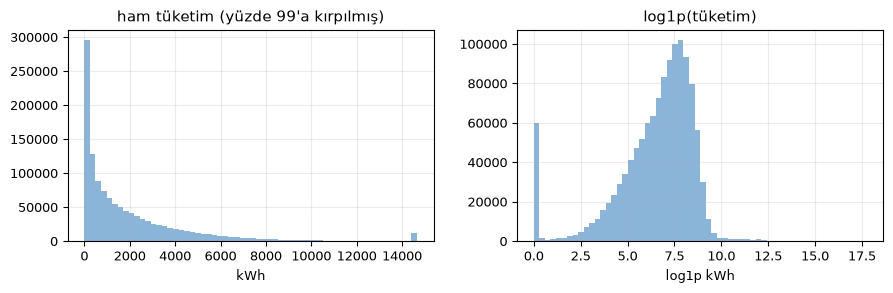

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9.0, 3.0))
ax[0].hist(np.clip(y, 0, np.percentile(y, 99)), bins=60, color="#8ab4d8")
ax[0].set_title("ham tüketim (yüzde 99'a kırpılmış)"); ax[0].set_xlabel("kWh")
ax[1].hist(np.log1p(y), bins=60, color="#8ab4d8")
ax[1].set_title("log1p(tüketim)"); ax[1].set_xlabel("log1p kWh")
plt.tight_layout(); plt.show()

Ham dağılımın çarpıklığı üç haneli, `log1p` sonrası mutlak değerce
bire yakın ve işareti dönüyor. Yani dönüşüm sağa çarpıklığı fazlasıyla
düzeltiyor. Sol uçtaki sıfır yığını da görünüyor ve o yığın RMSLE
altında oldukça pahalı: gerçeği sıfır olan bir satıra 1000 kWh dersek
`log1p` uzayında tek başına 48 birim hata alıyorum. Ölü trafo maskesi
bu yüzden en çok kazandıran düzeltmelerden biri oldu (bölüm 6).

Hedefi `log1p` ile dönüştürüp objective olarak RMSE kullandım. MAE ve
Tweedie denemedim, çünkü metrik zaten `log1p` uzayında karesel.

### 1.2 Panel Yapısı ve Trafo Girişleri

Bu bulguyu ilk bakışta görmek zor, ama çözümün tamamını şekillendirdi.

In [8]:
aktif = (pd.concat([train[["tarih", "tanim"]], test[["tarih", "tanim"]]])
         .groupby("tarih").tanim.nunique())
yeni = test[~test.tanim.isin(set(train.tanim))]
giris = yeni.groupby("tanim").tarih.min().value_counts()

print("eğitimde %d, testte %d ayrı trafo" % (train.tanim.nunique(), test.tanim.nunique()))
print("testte geçmişi olmayan trafo: %d" % len(yeni.tanim.unique()))
print("bunların %d tanesi tek günde giriyor: %s"
      % (giris.max(), giris.idxmax().date()))
print("günlük aktif trafo: %s günü %d, %s günü %d"
      % (aktif.index[0].date(), aktif.iloc[0], aktif.index[-1].date(), aktif.iloc[-1]))

eğitimde 5344, testte 7036 ayrı trafo
testte geçmişi olmayan trafo: 2024
bunların 1326 tanesi tek günde giriyor: 2026-05-11
günlük aktif trafo: 2025-01-01 günü 2059, 2026-07-31 günü 6795


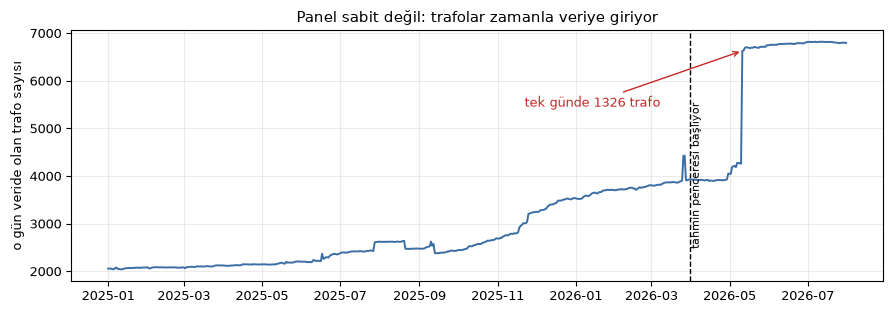

In [9]:
fig, ax = plt.subplots(figsize=(9.0, 3.2))
ax.plot(aktif.index, aktif.values, color="#3a6ea5", lw=1.4)
ax.axvline(train.tarih.max(), color="k", ls="--", lw=1)
ax.text(train.tarih.max(), aktif.max() * 0.35, " tahmin penceresi başlıyor",
        fontsize=8, rotation=90, va="bottom")
ax.annotate("tek günde %d trafo" % giris.max(),
            xy=(giris.idxmax(), aktif.loc[giris.idxmax()]),
            xytext=(giris.idxmax() - pd.Timedelta(days=170), aktif.max() * 0.80),
            arrowprops=dict(arrowstyle="->", color="#c62828"), color="#c62828")
ax.set_ylabel("o gün veride olan trafo sayısı")
ax.set_title("Panel sabit değil: trafolar zamanla veriye giriyor")
plt.tight_layout(); plt.show()

Aktif trafo sayısı üç katına çıkıyor ve geçmişi olmayan trafoların
üçte ikisi tek bir günde beliriyor. Tek günde binden fazla trafo tesis
edilmeyeceğine göre bu bir veri akışına toplu alım olmalı. Yani o
trafolar zaten çalışan, olgun trafolar; sadece ölçüm kayıtları bizim
veri kümeme o gün girmiş.

Buradan şunu çıkardım: o trafoları yeni doğmuş ve yükü rampa çıkan
birimler saymak yanlış olur. Doğrusu, olgun trafolar ama geçmişlerini
görmüyorum. Yani problem zaman serisi değil kesitsel seviye
kestirimi. Bölüm 5'ün modeli bu karara dayanıyor.

### 1.3 Mevsimsellik, Haftanın Günü ve Hava

Bu üç eksen birlikte bakılıyor, çünkü üçü de aynı terime, günlük
endekse girecek. Sorulan soru şu: hangisi ne kadar büyük ve endeksin
girdisi ham sıcaklık mı olmalı yoksa derece günleri mi.

In [10]:
gunluk = train.groupby("tarih").L.mean()
hafta = train.assign(g=train.tarih.dt.dayofweek).groupby("g").L.mean()
gun_adi = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]

print("yıl içi genlik (aylık ortalamaların aralığı) %.3f log birimi"
      % (train.groupby(train.tarih.dt.to_period("M")).L.mean().max()
         - train.groupby(train.tarih.dt.to_period("M")).L.mean().min()))
print("haftanın günü genliği %.3f log birimi" % (hafta.max() - hafta.min()))

yıl içi genlik (aylık ortalamaların aralığı) 0.930 log birimi
haftanın günü genliği 0.056 log birimi


Aynı iki büyüklüğün grafiği. Solda günlük ortalama tüketim ile on dört günlük hareketli ortalaması, sağda haftanın günü sapması.

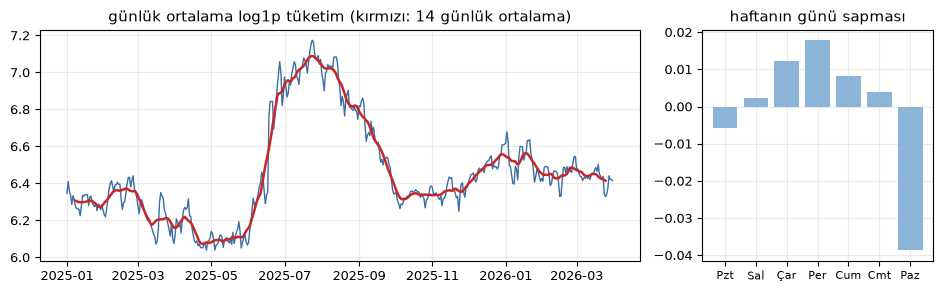

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.0),
                       gridspec_kw={"width_ratios": [2.6, 1]})
ax[0].plot(gunluk.index, gunluk.values, color="#3a6ea5", lw=1.0)
ax[0].plot(gunluk.index, gunluk.rolling(14, center=True).mean(),
           color="#c62828", lw=1.8)
ax[0].set_title("günlük ortalama log1p tüketim (kırmızı: 14 günlük ortalama)")
ax[1].bar(range(7), hafta.values - hafta.mean(), color="#8ab4d8")
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(gun_adi, fontsize=8)
ax[1].set_title("haftanın günü sapması")
plt.tight_layout(); plt.show()

Sıradaki soru endeksin girdisiyle ilgili: ham sıcaklık mı kullanmalı,
derece günleri mi? Aşağıdaki hücre üç şey ölçüyor; derece günü
korelasyonları, sıcaklık kovasına göre ortalama sapma ve soğutma
duyarlılığının güç sınıfına göre değişimi.

In [12]:
# Hava ilişkisi. Endeksin hangi girdilerle kurulacağını ve neden güç
# sınıfına göre katmanlanacağını belirleyen iki ölçüm (bölüm 4.1).
KENAR_GUC = [0, 100, 250, 400, 630, 1000, 1600, 1e9]
ETIKET_GUC = ["<=100", "160-250", "400", "630", "1000", "1250-1600", ">1600"]
gt_ = GUN_TABLO.set_index("tarih")
sapma = train.L - train.groupby("tanim").L.transform("mean")
gun_sapma = sapma.groupby(train.tarih).mean()

if "cdd_izmir" in gt_.columns:
    print("")
    for kol, ad in (("cdd_izmir", "soğutma derece günü"),
                    ("hdd_izmir", "ısıtma derece günü")):
        v = gun_sapma.index.map(gt_[kol]).to_numpy(dtype=float)
        print("trafo seviyesinden sapma ile %s korelasyonu %+.3f"
              % (ad, np.corrcoef(gun_sapma.to_numpy(), v)[0, 1]))

    # İlişki doğrusal mı yoksa U biçiminde mi: sıcaklık kovalarına bakılıyor.
    kova = pd.cut(train.tarih.map(gt_.sicaklik_ort_izmir).to_numpy(),
                  [-10, 5, 10, 14, 18, 22, 26, 30, 50])
    print("")
    print("gün ortalama sıcaklığına göre ortalama sapma, log birimi:")
    print(sapma.groupby(kova, observed=True).mean().round(3).to_string())

    # Soğutma duyarlılığı güç sınıfına göre değişiyorsa endeks katmanlanmalı.
    gs_ = pd.cut(train.guc, KENAR_GUC, labels=ETIKET_GUC).astype(str)
    kor = {}
    for g_ad in sorted(set(gs_)):
        m_ = (gs_ == g_ad).to_numpy()
        gs_gun = sapma[m_].groupby(train.tarih[m_]).mean()
        c_ = gs_gun.index.map(gt_.cdd_izmir).to_numpy(dtype=float)
        kor[g_ad] = float(np.corrcoef(gs_gun.to_numpy(), c_)[0, 1])
    HAVA_GUC = pd.Series(kor).sort_values(ascending=False)
    print("")
    print("güç sınıfı başına soğutma derece günü korelasyonu:")
    print(HAVA_GUC.round(3).to_string())
del sapma, gun_sapma
gc.collect()


trafo seviyesinden sapma ile soğutma derece günü korelasyonu +0.759
trafo seviyesinden sapma ile ısıtma derece günü korelasyonu +0.026

gün ortalama sıcaklığına göre ortalama sapma, log birimi:
(-10, 5]    0.108
(5, 10]     0.041
(10, 14]   -0.031
(14, 18]   -0.126
(18, 22]   -0.214
(22, 26]   -0.121
(26, 30]    0.138
(30, 50]    0.375



güç sınıfı başına soğutma derece günü korelasyonu:
160-250      0.861
<=100        0.845
400          0.729
1000         0.559
1250-1600    0.549
630          0.417
>1600        0.212


14745

Mevsimsel genlik haftanın günü genliğinden bir mertebe büyük, ayrıca
seri yılın ikinci yarısında yukarı kayıyor. İki gözlem de bölüm 4'ün
endeks tasarımına girdi: endeksi yıl içi harmonikler ve haftanın günü
kuklalarıyla kurdum, ve panel bileşimi değiştiği için dengeli bir alt
panelden hesapladım. Yoksa endeks, yeni trafo girişini mevsim
sanacaktı.

### 1.4 Güç ve Tüketim İlişkisi

Hava tarafında üç şey görünüyor.

Soğutma derece günü ile ilişki güçlü (+0,76), ısıtma derece günüyle ise
neredeyse sıfır. Bu ikincisi ilk bakışta şaşırtıcı ama sıcaklık kovası
tablosu açıklıyor: ilişki doğrusal değil, U biçiminde. Tüketim 18-22 °C
bandında en düşük, hem soğuğa hem sıcağa gidildikçe yükseliyor. Doğrusal
bir korelasyon bu iki kolu birbirine götürüyor, o yüzden endeksi ham
sıcaklıkla değil ısıtma ve soğutma derece günleriyle ayrı ayrı kuruyorum.

Soğutma duyarlılığı güç sınıfına göre de değişiyor: korelasyon en küçük
sınıfta 0,86, en büyükte 0,21. Küçük trafolar mesken ve ticari yüke,
büyükler sanayiye daha yakın; sanayi yükü havaya daha az duyarlı. Bu
gözlem bölüm 4.1'de endeksi güç sınıfına göre katmanlama kararının
gerekçesi.

In [13]:
tr_seviye = train.groupby("tanim").agg(sev=("L", "mean"), guc=("guc", "first"))
tr_seviye["lguc"] = np.log(tr_seviye.guc.clip(lower=1))
kor = np.corrcoef(tr_seviye.lguc, tr_seviye.sev)[0, 1]
A = np.column_stack([np.ones(len(tr_seviye)), tr_seviye.lguc])
w, *_ = np.linalg.lstsq(A, tr_seviye.sev.to_numpy(), rcond=None)
print("trafo seviyesi ile log(güç) korelasyonu %.3f, R2 %.3f" % (kor, kor ** 2))
print("eğim %.3f  kesme %.3f" % (w[1], w[0]))
print("trafo seviyelerinin standart sapması %.3f, artığın %.3f"
      % (tr_seviye.sev.std(), (tr_seviye.sev - A @ w).std()))

trafo seviyesi ile log(güç) korelasyonu 0.426, R2 0.182
eğim 1.025  kesme 0.163
trafo seviyelerinin standart sapması 2.195, artığın 1.985


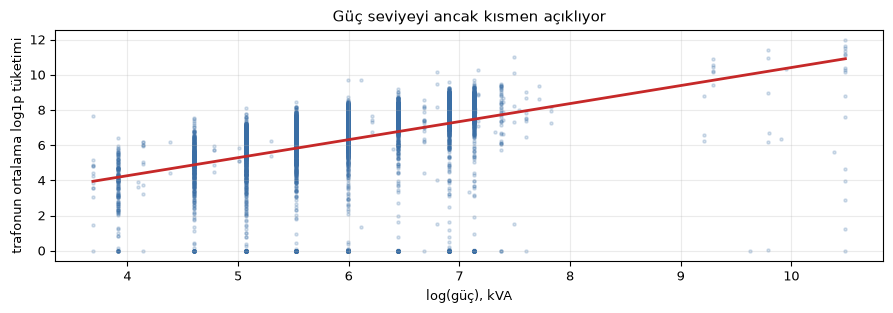

In [14]:
fig, ax = plt.subplots(figsize=(9.0, 3.2))
ax.scatter(tr_seviye.lguc, tr_seviye.sev, s=5, alpha=0.20, color="#3a6ea5")
xs = np.linspace(tr_seviye.lguc.min(), tr_seviye.lguc.max(), 50)
ax.plot(xs, w[0] + w[1] * xs, color="#c62828", lw=2)
ax.set_xlabel("log(güç), kVA"); ax.set_ylabel("trafonun ortalama log1p tüketimi")
ax.set_title("Güç seviyeyi ancak kısmen açıklıyor")
plt.tight_layout(); plt.show()

Güç, seviyenin yalnız küçük bir kısmını açıklıyor, geriye oldukça
geniş bir artık kalıyor. Geçmişi olmayan blok için bu kötü haber:
elimdeki en güçlü tek özellik bu ve tek başına yetmiyor. Bölüm 5 tam
olarak bu artığı daraltmaya çalışıyor.

### 1.5 Eksik Değer ve Sıfır Tüketim Taraması

In [15]:
# Hedef sütunu testte doğal olarak yok; tarama ortak sütunlar üzerinde.
ortak = [c for c in train.columns if c in test.columns]
tarama = pd.DataFrame({
    "eksik_train": train[ortak].isna().sum(),
    "eksik_test": test[ortak].isna().sum(),
    "tekil_train": train[ortak].nunique(),
})
print(tarama.to_string())
print("")
gun_trafo = train.groupby("tanim").tarih.nunique()
print("trafo başına gün sayısı: ortanca %d, en az %d, en çok %d"
      % (gun_trafo.median(), gun_trafo.min(), gun_trafo.max()))
sifir_oran = train.assign(s=(train.tuketim == 0)).groupby("tanim").s.mean()
print("hiç sıfır raporlamayan trafo oranı      %.3f" % (sifir_oran == 0).mean())
print("günlerinin tamamı sıfır olan trafo oranı %.3f" % (sifir_oran == 1).mean())
print("aralıklı çalışan (sıfır oranı 0,1 - 0,9) %.3f" % sifir_oran.between(0.1, 0.9).mean())
print("")
print("test trafolarının eğitimde bulunma oranı %.4f"
      % test.tanim.isin(set(train.tanim)).mean())

          eksik_train  eksik_test  tekil_train
tanim               0           0         5344
guc                 0           0           41
tarih               0           0          455
lokasyon            0           0           47
il                  0           0            2
bolge               0           0           20
ilce                0           0           47

trafo başına gün sayısı: ortanca 170, en az 1, en çok 455
hiç sıfır raporlamayan trafo oranı      0.897
günlerinin tamamı sıfır olan trafo oranı 0.056
aralıklı çalışan (sıfır oranı 0,1 - 0,9) 0.019



test trafolarının eğitimde bulunma oranı 0.7784


Sütunlarda eksik değer yok ama panel dengesiz: bazı trafoların iki
günü var, bazılarının bütün dönemi. Trafoların bir kısmı her gün sıfır
raporluyor, bir kısmı aralıklı. Bu üç grup farklı davranıyor, bölüm
5'te ayrı düzeltme yönleri olarak ele aldım.

### 1.6 Hata Bütçesinin Dağılımı

Modelin iyi olup olmadığını sormak yerine, bu hatanın indirgenemez
tabanının ne olduğunu sordum. Ölçmek için geçmişi ikiye böldüm: 30 Kasım 2025'e kadarki
kısım bilgi, sonraki dört ay ölçüm. Dört ay, gerçek tahmin ufkuyla
aynı uzunlukta.

Kâhin sütununu çapraz bölmeli hesapladım: trafo başına sabit, ölçüm
penceresinin tek günlerinde kuruluyor, çift günlerinde ölçülüyor. Aynı
satırlarda kurup ölçseydim yapay olarak iyi çıkardı.

In [16]:
gecmis_uzunlugu = train.groupby("tanim").tarih.nunique()
test["gecmis"] = test.tanim.map(gecmis_uzunlugu).fillna(0).astype(int)
kes = [0, 1, 30, 122, 365, 10 ** 6]
etiket = ["geçmişsiz", "1-29 gün", "30-121 gün", "122-364 gün", "365+ gün"]
test["bant"] = pd.cut(test.gecmis, kes, right=False, labels=etiket)
print("test satırlarının, trafonun eğitimdeki geçmiş uzunluğuna göre payı (%):")
print((100 * test.groupby("bant", observed=True).size() / len(test)).round(2).to_string())

test satırlarının, trafonun eğitimdeki geçmiş uzunluğuna göre payı (%):
bant
geçmişsiz      22.16
1-29 gün        9.18
30-121 gün     14.80
122-364 gün    24.67
365+ gün       29.19


Payları gördükten sonra asıl soruya geçiyorum: bu satırlar hatanın
ne kadarını taşıyor? Ölçmek için iki uç kuruyorum. Naif taban, hiçbir
model olmadan yapılabilecek en basit tahmin. Kâhin taban ise trafonun
seviyesini tam bilseydim kalacak hata, yani ulaşamayacağım alt sınır.
Kâhini çapraz bölmeli hesaplıyorum: ölçüm penceresinin tek günlerinde
kuruluyor, çift günlerinde ölçülüyor. Aynı satırlarda kurup ölçseydim
yapay olarak iyi çıkardı.

In [17]:
SINAMA = pd.Timestamp("2025-11-30")
E1 = train[train.tarih <= SINAMA]
H1 = train[train.tarih > SINAMA].copy()
H1["blok"] = np.where(H1.tanim.isin(set(E1.tanim)), "geçmişi olan", "geçmişi olmayan")

# Naif taban: geçmişi olan trafo için kendi son üç ayı, olmayan için
# kendi güç sınıfının ortalaması. Model değil, tabanın ölçülmesi.
son_uc_ay = E1[E1.tarih >= "2025-09-01"].groupby("tanim").L.mean()
guc_ortalama = E1.groupby("guc").L.mean()
H1["naif"] = H1.tanim.map(son_uc_ay).fillna(H1.guc.map(guc_ortalama)).fillna(E1.L.mean())

tek_gun = H1.tarih.dt.day % 2 == 1
kahin_sabit = H1[tek_gun].groupby("tanim").L.mean()
H1c = H1[~tek_gun].copy()
H1c["kahin"] = H1c.tanim.map(kahin_sabit)
H1c = H1c[H1c.kahin.notna()]

BLOK = pd.DataFrame(index=["geçmişi olan", "geçmişi olmayan"])
BLOK["satir_payi"] = [(test.gecmis > 0).mean(), (test.gecmis == 0).mean()]
BLOK["naif_mse"] = [float(((H1.L - H1.naif)[H1.blok == b] ** 2).mean()) for b in BLOK.index]
BLOK["kahin_mse"] = [float(((H1c.L - H1c.kahin)[H1c.blok == b] ** 2).mean()) for b in BLOK.index]
BLOK["naif_rmsle"] = np.sqrt(BLOK.naif_mse)
BLOK["katki"] = BLOK.satir_payi * BLOK.naif_mse
BLOK["katki_yuzde"] = 100 * BLOK.katki / BLOK.katki.sum()
BLOK["kahin_katki_yuzde"] = 100 * BLOK.satir_payi * BLOK.kahin_mse / BLOK.katki.sum()
print("")
print(BLOK[["satir_payi", "naif_rmsle", "kahin_mse", "katki", "katki_yuzde"]].round(4).to_string())
print("")
print("naif tabanın toplam RMSLE'si %.4f" % np.sqrt(BLOK.katki.sum()))
print("geçmişsiz blok: test satırlarının %%%.1f i, naif hatanın %%%.1f i"
      % (100 * BLOK.satir_payi.iloc[1], BLOK.katki_yuzde.iloc[1]))


                 satir_payi  naif_rmsle  kahin_mse   katki  katki_yuzde
geçmişi olan         0.7784      0.7438     0.1777  0.4306       36.466
geçmişi olmayan      0.2216      1.8401     0.1174  0.7503       63.534

naif tabanın toplam RMSLE'si 1.0867
geçmişsiz blok: test satırlarının %22.2 i, naif hatanın %63.5 i


Aynı iki büyüklüğün grafiği. Solda satır payı, sağda hata katkısı;
sağdaki grafikte koyu bölüm kâhin tabanı, yani o bloğun ulaşılamaz
kısmı. Kırmızı ile koyu arasındaki mesafe kazanılabilecek yer.

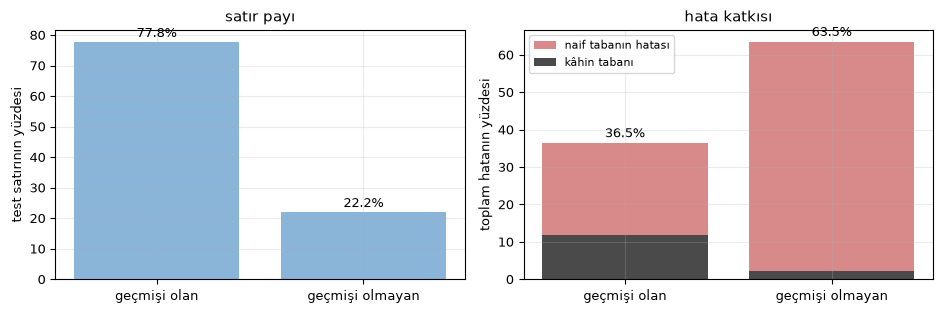

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
x = np.arange(2); ad = ["geçmişi olan", "geçmişi olmayan"]
ax[0].bar(x, 100 * BLOK.satir_payi, color="#8ab4d8")
ax[0].set_xticks(x); ax[0].set_xticklabels(ad); ax[0].set_ylabel("test satırının yüzdesi")
ax[0].set_title("satır payı")
for i, v in enumerate(100 * BLOK.satir_payi):
    ax[0].text(i, v + 1.5, "%.1f%%" % v, ha="center")
ax[1].bar(x, BLOK.katki_yuzde, color="#d88a8a", label="naif tabanın hatası")
ax[1].bar(x, BLOK.kahin_katki_yuzde, color="#4a4a4a", label="kâhin tabanı")
ax[1].set_xticks(x); ax[1].set_xticklabels(ad); ax[1].set_ylabel("toplam hatanın yüzdesi")
ax[1].set_title("hata katkısı"); ax[1].legend(loc="upper left", fontsize=8)
for i, v in enumerate(BLOK.katki_yuzde):
    ax[1].text(i, v + 1.5, "%.1f%%" % v, ha="center")
plt.tight_layout(); plt.show()

Grafiğin söylediği şu: satırların beşte biri, hatanın yaklaşık üçte
ikisi. Koyu bölüm, trafonun seviyesini tam bilsek bile kalan günlük
gürültü, yani ulaşamayacağım taban. Geçmişi olmayan blokta kırmızı
ile koyu arasındaki mesafe neredeyse bütün sütun, orada kazanılacak
çok yer var. Geçmişi olan blokta mesafe çok daha dar.

Kaynağı bu yüzden geçmişi olmayan bloğa ayırdım. Bölüm 5'ün kesitsel
modeli ve bölüm 6'in en büyük katsayıları oradan geliyor.

### 1.7 Varsayımların İstatistiksel Sınanması

Çözümün tamamı iki varsayıma dayanıyor ve ikisi de şu ana kadar
gözlemden ibaretti. Burada ikisini de sınıyorum. Testlerin ikisi de
permütasyon testi: gözlediğim büyüklüğü, aynı veriden rastgele
üretilmiş binlerce sahte kopyayla karşılaştırıyorum. Dağılım varsayımı
gerektirmediği için bu veriye uygun.

Birinci varsayım: geçmişi olmayan trafolar ayrı bir nüfus değil.
Bölüm 1.2'de bunların olgun trafolar olduğunu, sadece kayıtlarının geç
girdiğini söylemiştim. Doğruysa kurulu güç dağılımları eğitimdeki
trafolarla benzer olmalı. Yanlışsa, örneğin hepsi küçük kırsal trafo
çıkarsa, kesitsel modelin öğrendiği ilişki onlara taşınmaz.

İkinci varsayım: `tanim` kodundaki sayısal komşuluk coğrafi
yakınlığın vekili. Bölüm 5'ün dokuz özelliğinin üçü buna dayanıyor.
Doğruysa kod bakımından komşu iki trafonun seviyeleri, rastgele
seçilmiş iki trafodan daha yakın olmalı.

In [19]:
rng_t = np.random.default_rng(11)

# 1) Geçmişi olmayan trafolar ayrı bir nüfus mu? Permütasyon testi.
kimlik_t = (pd.concat([train[["tanim", "guc"]], test[["tanim", "guc"]]])
            .groupby("tanim").guc.first())
lguc_t = np.log(kimlik_t.clip(lower=1))
gecmisli = kimlik_t.index.isin(set(train.tanim))
gozlenen_fark = lguc_t[~gecmisli].mean() - lguc_t[gecmisli].mean()

v = lguc_t.to_numpy()
n1 = int((~gecmisli).sum())
sahte = np.array([rng_t.permutation(v)[:n1].mean() - rng_t.permutation(v)[n1:].mean()
                  for _ in range(1000)])
p1 = float((np.abs(sahte) >= abs(gozlenen_fark)).mean())
print("1) GEÇMİŞİ OLMAYAN TRAFOLAR AYRI BİR NÜFUS MU")
print("   eğitimde olan %d trafo, ortalama log(güç) %.3f"
      % (gecmisli.sum(), lguc_t[gecmisli].mean()))
print("   yalnız testte  %d trafo, ortalama log(güç) %.3f"
      % ((~gecmisli).sum(), lguc_t[~gecmisli].mean()))
print("   gözlenen fark %+.3f log birimi, permütasyon p = %.3f (1000 tekrar)" % (gozlenen_fark, p1))
print("   iki grubun sd'si %.3f ve %.3f" % (lguc_t[gecmisli].std(), lguc_t[~gecmisli].std()))
print("   fark, ortak sd'nin %.2f katı" % (abs(gozlenen_fark) / lguc_t.std()))
alt_s, ust_s = np.percentile(lguc_t[gecmisli], [1, 99])
icinde = ((lguc_t[~gecmisli] >= alt_s) & (lguc_t[~gecmisli] <= ust_s)).mean()
print("   asıl soru ekstrapolasyon: yalnız testte olan trafoların %%%.1f'i"
      % (100 * icinde))
print("   eğitim aralığının yüzde 1 ile yüzde 99 bandının içinde")
print("")

1) GEÇMİŞİ OLMAYAN TRAFOLAR AYRI BİR NÜFUS MU
   eğitimde olan 5344 trafo, ortalama log(güç) 5.988
   yalnız testte  2024 trafo, ortalama log(güç) 6.187
   gözlenen fark +0.199 log birimi, permütasyon p = 0.000 (1000 tekrar)
   iki grubun sd'si 0.913 ve 0.855
   fark, ortak sd'nin 0.22 katı
   asıl soru ekstrapolasyon: yalnız testte olan trafoların %99.4'i
   eğitim aralığının yüzde 1 ile yüzde 99 bandının içinde



İkinci varsayım kendi testini gerektiriyor. Trafo kodları sayısal
sıralandığında komşu olan çiftlerin seviyeleri, rastgele seçilmiş
çiftlerden daha mı yakın? Burada da permütasyon kullanıyorum: gözlenen
komşu farkını, aynı seviyelerin bin kez karıştırılmasıyla üretilen
farklarla karşılaştırıyorum.

In [20]:
# 2) Kod komşuluğu coğrafi yakınlığın vekili mi? Permütasyon testi.
sev_t = train.groupby("tanim").L.mean()
kod_t = pd.to_numeric(pd.Series(sev_t.index).str.extract(r"^(\d+)")[0],
                      errors="coerce").to_numpy()
gecerli = np.isfinite(kod_t)
sirala = np.argsort(kod_t[gecerli])
s_sirali = sev_t.to_numpy()[gecerli][sirala]
komsu_fark = np.abs(np.diff(s_sirali)).mean()
rastgele = np.array([np.abs(np.diff(rng_t.permutation(s_sirali))).mean()
                     for _ in range(1000)])
p2 = float((rastgele <= komsu_fark).mean())
print("2) KOD KOMŞULUĞU COĞRAFİ YAKINLIĞIN VEKİLİ Mİ")
print("   kod sırasına göre komşu çiftlerde ortalama |seviye farkı| %.4f" % komsu_fark)
print("   rastgele çiftlerde                                        %.4f"
      % rastgele.mean())
print("   komşuluk avantajı %.1f%%, permütasyon p = %.4f (1000 tekrar)"
      % (100 * (1 - komsu_fark / rastgele.mean()), p2))

2) KOD KOMŞULUĞU COĞRAFİ YAKINLIĞIN VEKİLİ Mİ
   kod sırasına göre komşu çiftlerde ortalama |seviye farkı| 1.8068
   rastgele çiftlerde                                        2.2640
   komşuluk avantajı 20.2%, permütasyon p = 0.0000 (1000 tekrar)


İki testin de görsel karşılığı aşağıda. Soldaki grafikte bakılacak
şey iki dağılımın üst üste binme miktarı, sağdakinde ise kırmızı
çizginin permütasyon dağılımının neresine düştüğü.

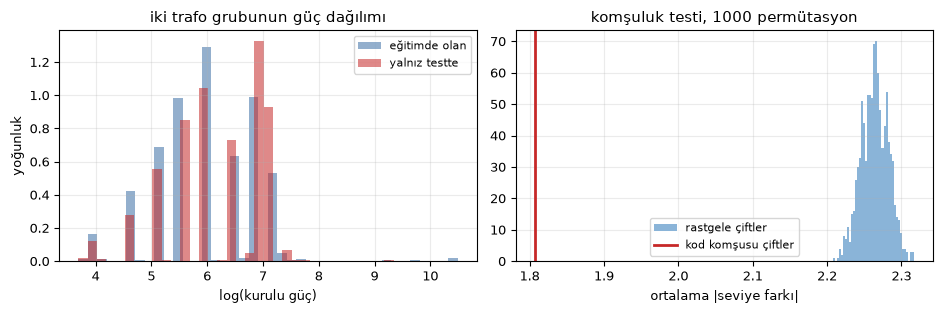

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].hist(lguc_t[gecmisli], bins=40, density=True, alpha=0.55,
           color="#3a6ea5", label="eğitimde olan")
ax[0].hist(lguc_t[~gecmisli], bins=40, density=True, alpha=0.55,
           color="#c62828", label="yalnız testte")
ax[0].set_xlabel("log(kurulu güç)"); ax[0].set_ylabel("yoğunluk")
ax[0].legend(fontsize=8); ax[0].set_title("iki trafo grubunun güç dağılımı")
ax[1].hist(rastgele, bins=40, color="#8ab4d8", label="rastgele çiftler")
ax[1].axvline(komsu_fark, color="#c62828", lw=2, label="kod komşusu çiftler")
ax[1].set_xlabel("ortalama |seviye farkı|")
ax[1].legend(fontsize=8); ax[1].set_title("komşuluk testi, 1000 permütasyon")
plt.tight_layout(); plt.show()

Birinci test beklediğimi doğrulamadı ve bu yüzden ilginç. İki grup
istatistiksel olarak farklı çıkıyor, p sıfıra yakın: yalnız testte
olan trafolar ortalamada biraz daha büyük güçlü. Ama 7368 trafoda çok
küçük farklar bile anlamlı çıkar, o yüzden asıl bakılacak yer etki
büyüklüğü. Fark ortak standart sapmanın beşte biri kadar ve iki grubun
sd'si neredeyse aynı, yani dağılımlar kaymış ama biçim değiştirmemiş.

Benim için asıl soru zaten fark olup olmadığı değil, modelin
dışdeğerleme yapmak zorunda kalıp kalmadığı. Yukarıdaki çıktı bunu da
veriyor: yalnız testte
olan trafoların neredeyse tamamı eğitim aralığının içinde kalıyor.
Yani `lguc` özelliğini kullanan bir ağaç için bu bir aradeğerleme
problemi, dışdeğerleme değil. Bölüm 1.2'nin yorumu, yani bu trafoların olgun
olduğu ve yalnız kayıtlarının geç girdiği, ayakta duruyor; ama
düzeltilmiş hâliyle: aynı nüfusun biraz daha büyük güçlü tarafı.

İkinci test net. Kod bakımından komşu trafolar rastgele çiftlerden
belirgin biçimde daha benzer seviyelere sahip, permütasyon p'si sıfır.
Bölüm 5'ün üç komşuluk özelliğinin dayandığı varsayım ölçülmüş oldu.

Bir uyarı da yazayım: bu test kod komşuluğunun coğrafi yakınlık
olduğunu kanıtlamıyor, yalnız komşu kodların benzer seviyeler
taşıdığını gösteriyor. Coğrafya en makul açıklama ama tek açıklama
değil; aynı dönemde tesis edilmiş olmak da hem benzer kod hem benzer
yük üretebilir.

## 2. Validation Stratejisi

Doğrulamayı model kodundan önce kurdum ve şema, test setinin ayrılma
biçimini taklit ediyor. Aşağıda neyi neden böyle seçtiğimi ve hangi
sızıntı kapılarını kapattığımı anlatıyorum.

### 2.1 Takvim Tabanlı Bölme

Şemam şu: bir **sınama tarihi** seçiyorum, o tarihe kadarki her şey
bilgi, sonraki **122 gün** ölçüm penceresi. 122 gün, gerçek tahmin
ufkunun tam uzunluğu (1 Nisan - 31 Temmuz 2026).

Rastgele bölmeyi iki sebeple eledim:

* Test, eğitimden zamanla ayrılmış. Rastgele bölseydim doğrulama
  satırının kendi trafosunun aynı haftadaki başka günleri eğitimde
  kalırdı; model o trafonun o dönemdeki seviyesini neredeyse doğrudan
  görür, doğrulama skoru gerçek görevden çok daha iyi çıkardı.
* Panel bileşimi zamanla değişiyor (bölüm 1.2). Gerçek görevde
  test trafolarının beşte biri hiç görülmemiş oluyor; rastgele bölmede
  bu oran sıfır olur, yani doğrulama en zor bloğu hiç içermezdi.

### 2.2 Üç Sınama Tarihi

Tek sınama tarihi mevsime bağımlı sonuç verir, o yüzden üç tarih
seçtim. Üçünün de ölçüm penceresi 122 gün ve üçü farklı bir mevsim
geçişini kapsıyor. Bir düzeltme yönünü ancak **üçünde de aynı işareti**
verirse ciddiye aldım; bu üç tarih aynı zamanda bölüm 6.4'ün çapraz
doğrulama katları.

In [22]:
UFUK = (test.tarih.max() - test.tarih.min()).days + 1
SINAMA_TARIHLERI = [pd.Timestamp("2025-06-30"),
                    pd.Timestamp("2025-08-31"),
                    pd.Timestamp("2025-11-30")]
print("gerçek tahmin ufku %d gün (%s .. %s)"
      % (UFUK, test.tarih.min().date(), test.tarih.max().date()))
print("")
satirlar = []
for T0 in SINAMA_TARIHLERI:
    T1 = T0 + pd.Timedelta(days=UFUK - 1)
    e = train[train.tarih <= T0]
    d = train[(train.tarih > T0) & (train.tarih <= T1)]
    satirlar.append({
        "sınama tarihi": T0.date(),
        "ölçüm penceresi": "%s .. %s" % ((T0 + pd.Timedelta(days=1)).date(), T1.date()),
        "eğitim satırı": len(e),
        "ölçüm satırı": len(d),
        "ölçümde geçmişsiz pay": round(float((~d.tanim.isin(set(e.tanim))).mean()), 4),
    })
SEMA = pd.DataFrame(satirlar)
print(SEMA.to_string(index=False))
print("")
print("gerçek testte geçmişsiz pay %.4f" % (test.gecmis == 0).mean())

gerçek tahmin ufku 122 gün (2026-04-01 .. 2026-07-31)



sınama tarihi          ölçüm penceresi  eğitim satırı  ölçüm satırı  ölçümde geçmişsiz pay
   2025-06-30 2025-07-01 .. 2025-10-29         386786        302853                 0.0920
   2025-08-31 2025-09-01 .. 2025-12-30         542109        342403                 0.2100
   2025-11-30 2025-12-01 .. 2026-03-31         782161        444076                 0.1394

gerçek testte geçmişsiz pay 0.2216


Doğrulamam gerçek görevin en zor bloğunu olduğundan az temsil
ediyor. Ölçüm penceresindeki geçmişsiz satır payı sınama tarihi
ilerledikçe büyüyor ve gerçek testteki paya yaklaşıyor, ama onu
yakalamıyor. Bunu bir eksiklik olarak yazıyorum; sonucu şu: geçmişsiz
blok modelinin doğrulamada ölçtüğüm katkısı, gerçek testteki
katkısının alt sınırı.

Asıl doğrulama tarihi olarak sonuncusunu seçtim, çünkü ölçüm penceresi
hem en uzun geçmişe hem gerçek teste en yakın kompozisyona sahip.

### 2.3 Leakage Kapıları

Üç kapı var, üçünü de beyanla değil kodla kontrol ediyorum.

Birincisi, zaman kapısı. Sınama tarihinden sonraki hiçbir satır
hiçbir özelliğe girmiyor. Aşağıdaki hücre bunu doğruluyor.

İkincisi, hedef kapısı. Kesitsel modelin özellikleri yalnız
geçmişi olan trafolardan üretiliyor; tahmin edilecek trafo o referans
kümesinde hiç yok, yani kendi hedefi kendi özelliğine giremiyor.
Alışılmış refleks olan leave-one-out kodlaması burada ayrıca sınandı ve
işe yaramadığı, hatta ters yönde sızdırdığı ölçüldü; gerekçesi ve
sayıları bölüm 5.3'de.

Üçüncüsü, dış veri kapısı. Hava ve takvim verisi tahmin gününde
zaten bilinebilir olduğu için gecikmesiz kullanılabilir. Gerçekleşmiş
sistem tüketimi kullanılmadı; gerekçesi bölüm 7'de.

In [23]:
SINAMA = SINAMA_TARIHLERI[-1]
E = train[train.tarih <= SINAMA].copy()
D = train[(train.tarih > SINAMA) & (train.tarih <= SINAMA + pd.Timedelta(days=UFUK - 1))].copy()

# Zaman kapısı: eğitim tarafında sınama tarihinden sonra satır olmamalı,
# ölçüm tarafında da öncesinde. Sessiz geçmesin diye assert ile.
assert E.tarih.max() <= SINAMA, "eğitim penceresi sınama tarihini aşıyor"
assert D.tarih.min() > SINAMA, "ölçüm penceresi sınama tarihinden önce başlıyor"
assert len(set(E.index) & set(D.index)) == 0, "iki pencere satır paylaşıyor"

print("seçilen sınama tarihi %s" % SINAMA.date())
print("eğitim  %d satır, %s .. %s" % (len(E), E.tarih.min().date(), E.tarih.max().date()))
print("ölçüm   %d satır, %s .. %s" % (len(D), D.tarih.min().date(), D.tarih.max().date()))
print("zaman kapısı: geçti")
print("ölçüm penceresindeki trafoların %.1f%% i eğitimde de var"
      % (100 * D.tanim.isin(set(E.tanim)).mean()))

seçilen sınama tarihi 2025-11-30
eğitim  782161 satır, 2025-01-01 .. 2025-11-30
ölçüm   444076 satır, 2025-12-01 .. 2026-03-31
zaman kapısı: geçti


ölçüm penceresindeki trafoların 86.1% i eğitimde de var


## 3. Çözümün Mimarisi

Tahmin tek bir modelin çıktısı değil, dört bileşenin toplamıdır. Bu
bölüm hiçbir şey hesaplamaz; bileşenlerin ne olduğunu, nerede
kurulduklarını ve nasıl birleştiklerini bir kerede gösterir. Sonraki
dört bölüm bu tabloyu satır satır doldurur.

### 3.1 Nihai Tahmin Denklemi

Test kümesindeki her satır için üretilen tahmin şudur:

$$\hat{y}_{i,t} = \exp\!\Big(
\underbrace{s_i}_{\text{seviye}}
+ \underbrace{a_i\,m_t}_{\text{endeks}}
+ \underbrace{p + g + \tau}_{\text{takvim düzeltmeleri}}
+ \underbrace{\textstyle\sum_k \alpha_k\, d_k(i,t)}_{\text{artık düzeltmeleri}}
\Big) - 1$$

Seviye terimi trafonun kendi geçmişi ile grubunun ortalaması arasında
bir ağırlıklı ortalamadır:

$$s_i = \frac{W_i\,\mathrm{ham}_i + m(h)\, g_i}{W_i + m(h)},
\qquad m(h) = 0{,}35 \cdot 2^{h/45}$$

Geçmişi olmayan bir trafoda $W_i = 0$ olur ve seviye tamamen $g_i$
değerine düşer. İşte cross-sectional model tam olarak bu $g_i$ değerini
üretmek için vardır.

### 3.2 Bileşenler ve Kuruldukları Bölümler

| Bileşen | Ne yapar | Nerede kurulur |
|---|---|---|
| Günlük endeks $m_t$. | Bütün trafoları aynı gün aynı yönde iten mevsim ve takvim etkisini tek bir sayıya indirir. | Bölüm 4.1 |
| Trafo seviyesi $s_i$. | Her trafo için mevsimden arındırılmış bir taban değer üretir. | Bölüm 4.2 |
| Cross-sectional model $g_i$. | Geçmişi olmayan trafolar için grup ortalamasının yerine geçen kişiselleştirilmiş bir taban üretir. | Bölüm 5 |
| Düzeltme yönleri $d_k$. | Taban formülünün sistematik olarak bıraktığı artığı hedefler. | Bölüm 6.1 |
| Katsayılar $\alpha_k$ | Yönlerin ağırlıklarını cross-validation artığından kapalı formla çözer. | Bölüm 6.4 |

### 3.3 Eğitilen Modeller

Çözümde iki gradient boosting modeli vardır ve ikisi de yalnızca
cross-sectional blokta çalışır. Taban formülü ile düzeltme katsayıları
kapalı formludur, ağaç kullanmaz.

| Model | Rol | Tohum | Ana parametreler |
|---|---|---|---|
| LightGBM | Geçmişi olmayan trafonun seviyesini kestirir. | 3 (7, 17, 27) | `num_leaves` 15, `min_data_in_leaf` 40, `lambda_l2` 5, `learning_rate` 0,05, 300 tur |
| CatBoost | Aynı görevi farklı bir tümevarım önyargısıyla yapar. | 3 (7, 17, 27) | `depth` 5, `l2_leaf_reg` 6, `learning_rate` 0,05, 400 tur |
| Ridge | Günlük endeksi hava ve takvimden kestirir. | Yok, deterministik | `alpha` 1,0, güç sınıfına göre katmanlı |

Her iki gradient boosting modeli üç tohumla eğitilir ve tohum
ortalaması alınır. İkisinin ortalaması tek bir düzeltme yönü olur.
Parametreler sığdır ve cezalıdır; gerekçesi bölüm 5.3'te ölçülür.

### 3.4 Boru Hattı

| Adım | Girdi | Çıktı | Bölüm |
|---|---|---|---|
| 1 | Ham veri, hava ve takvim tablosu. | Günlük endeks $m_t$. | 4.1 |
| 2 | Endeksten arındırılmış tüketim. | Trafo seviyesi $s_i$. | 4.2 |
| 3 | Geçmişi olan trafoların seviyeleri. | Geçmişsiz trafolar için $g_i$. | 5 |
| 4 | Taban tahminin artığı. | Düzeltme yönleri $d_k$. | 6.1 |
| 5 | Üç zaman katının artığı. | Katsayılar $\alpha_k$ | 6.4 |
| 6 | Yukarıdakilerin tamamı | `submission.csv` | 9.2 |

Bu zincir iki kez kurulur. Bir kez bölüm 6.4'te üç cross-validation
katında katsayıları çözmek için, bir kez de bölüm 9.2'de bütün eğitim
verisiyle nihai tahmini üretmek için. İkisinde de aynı fonksiyonlar
çağrılır; değişen tek şey bilgi penceresinin uzunluğudur.

## 4. Seviye ve Endeks Modeli

Bu bölüm bölüm 3.1'deki denklemin ilk beş terimini kurar: günlük endeks
$m_t$, trafo seviyesi $s_i$, mevsim genliği $a_i$ ve üç takvim
düzeltmesi. Kalan iki terimi bölüm 5 ile bölüm 6 tamamlar.

Bu terimlerin hiçbiri bir gradient boosting modelinden çıkmaz. Endeks
Ridge ile kestirilir, seviye ise ağırlıklı ortalama ve büzülmeden
oluşan kapalı formlu bir hesaptır. LightGBM ile CatBoost yalnızca bölüm
5'te, geçmişi olmayan trafoların seviyesini kestirmek için devreye
girer.

Tercihin gerekçesini bölüm 1.6'da ölçtüm. Hata büyük ölçüde seviye
hatasıdır ve seviye kestirimi trafo başına bir sayı üretme problemidir,
satır başına değil. Gradient boosting bu iskeletin üstüne düzeltme
olarak girer, taban olarak değil.

### 4.1 Günlük Endeks

Endeks, bütün trafoları aynı gün aynı yönde iten şeyi tek bir sayıya
indiriyor: mevsim ve takvim. Bunu ayrı bir terim olarak çıkarmanın
sebebi, trafo seviyesini ondan arındırılmış hâlde kestirebilmek.
Aksi hâlde bir trafonun yüksek görünmesi, gerçekten yüksek olmasından
da ölçüldüğü günlerin sıcak olmasından da gelebilirdi.

Kurgusundaki üç seçim, üç ayrı tuzağa karşı alındı:

* Panel bileşimi. Aktif trafo sayısı üç katına çıkıyor (bölüm 1.2).
  Endeksi bütün trafoların günlük ortalaması olarak alsaydım, yeni
  trafo girişini mevsim etkisi sanardım. Bu yüzden endeksi yalnız
  bütün dönem boyunca veride olan dengeli bir alt panelden
  hesaplıyorum.
* Doğrusal model, ağaç değil. Doğrulama penceresindeki endeks,
  eğitimde görülen en yüksek değerin katlarına çıkabiliyor. Ağaç en
  yüksek yaprağında sıkışır; Ridge, soğutma derece gününü ileri taşır.
  Yıllık büyümeyi de doğrusal trend terimi karşılıyor, bu yüzden `yıl`
  diye bir özellik yok.
* Güç sınıfına göre katmanlama. Soğutma derece günü korelasyonu güç
  sınıfına göre 0,21 ile 0,86 arasında değişiyor (bölüm 1.3). Her güç sınıfı
  kendi endeksini alıyor; kırılımda kırktan az trafo varsa panel
  geneline düşüyor, çünkü az trafodan hesaplanan endeks gürültü olur.

Endeks girdisi iki il için sıcaklık, ısıtma ve soğutma derece gün,
ışınım, nem, bulut ve rüzgar; yirmi üç takvim sütunu; haftanın günü
kuklaları ve doğrusal trend.

In [24]:
from sklearn.linear_model import Ridge

GUC_KENAR = [0, 100, 250, 400, 630, 1000, 1600, 1e9]
GUC_ETIKET = ["<=100", "160-250", "400", "630", "1000", "1250-1600", ">1600"]
TATIL_TIP = ["dini_bayram", "resmi_tatil", "arife"]


# Panele ortak kalan zaman etkisi, yalnız kesintisiz veri veren alt panelden.
def gunluk_endeks(e):
    gun_sayisi = e.groupby("tanim").tarih.nunique()
    panel = gun_sayisi[gun_sayisi == e.tarih.nunique()].index
    alt = e[e.tanim.isin(panel)].copy()
    alt["log_t"] = np.log1p(alt.tuketim)
    alt["sapma"] = alt.log_t - alt.groupby("tanim").log_t.transform("mean")
    return alt.groupby("tarih").sapma.mean().rename("endeks").reset_index(), len(panel)


# Endeksi hava, takvim ve doğrusal trendden kestirir. Ridge seçilmesinin
# gerekçesi dışdeğerlemedir, markdownda anlatıldı.
def endeks_modeli(e_endeks, tahmin_gunleri, baslangic):
    def hazir(gunler):
        t = pd.DataFrame({"tarih": pd.to_datetime(gunler)})
        t = t.merge(GUN_TABLO, on="tarih", how="left")
        t["trend"] = (t.tarih - baslangic).dt.days / 365.0
        return t[ENDEKS_OZELLIK + ["trend"]]

    model = Ridge(alpha=1.0).fit(hazir(e_endeks.tarih), e_endeks.endeks)
    gunler = pd.to_datetime(tahmin_gunleri)
    return pd.Series(model.predict(hazir(gunler)), index=gunler.values)

Son parça katmanlama. Soğutma duyarlılığı güç sınıfına göre
değiştiği için (bölüm 1.3) her sınıf kendi endeksini alıyor; kırılımda
kırktan az trafo varsa panel geneline düşüyor.

In [25]:
# Güç sınıfına göre katmanlı endeks. Kırktan az trafolu kırılım panel
# geneline düşer.
def endeks_ekle(egitim, hedef, min_trafo=40, fit_veri=None):
    e, h = egitim.copy(), hedef.copy()
    # fit_veri verilirse endeks ONDAN fitlenir. Kat 1'in eğitim penceresi
    # Ocak-Mart ve orada CDD hep sıfır, soğutma katsayısı tanımsız kalır.
    f = e if fit_veri is None else fit_veri.copy()
    bas = f.tarih.min()
    tum_gun = pd.concat([e.tarih, h.tarih]).drop_duplicates().sort_values()
    genel = endeks_modeli(gunluk_endeks(f)[0], tum_gun, bas)

    for t in (e, h, f):
        t["_gs"] = pd.cut(t.guc, GUC_KENAR, labels=GUC_ETIKET).astype(str)
    katman = {}
    for g, alt in f.groupby("_gs", observed=True):
        if alt.tanim.nunique() < min_trafo:
            continue
        ge, n_panel = gunluk_endeks(alt)
        if n_panel < 10 or len(ge) < 30:
            continue
        katman[g] = endeks_modeli(ge, tum_gun, bas)

    for t in (e, h):
        deger = t.tarih.map(genel).to_numpy().astype(float)
        for g, seri in katman.items():
            m = (t["_gs"] == g).to_numpy()
            if m.any():
                deger[m] = t.loc[m, "tarih"].map(seri).to_numpy()
        t["endeks"] = deger
    return e.drop(columns="_gs"), h.drop(columns="_gs"), len(katman)

Endeksi ölçüm penceresinde kuruyorum. Grafikte bakılacak yer eğitim
uyumu değil, kesikli çizginin sağı: kestirilen endeksin ölçüm
penceresinde gözlenen mevsim hareketini yakalayıp yakalamadığı.

In [26]:
E, D, n_katman = endeks_ekle(E, D)

# Karşılaştırma için gözlenen panel ortalaması: modelin oturmaya
# çalıştığı hedef. R2 bu iki serinin uyumunu ölçüyor.
ge_gozlem, n_panel = gunluk_endeks(E)
endeks_seri = E.groupby("tarih").endeks.mean()
r2 = 1 - float(np.var(ge_gozlem.endeks.to_numpy()
                      - ge_gozlem.tarih.map(endeks_seri).to_numpy())
               / np.var(ge_gozlem.endeks.to_numpy()))

print("dengeli panel %d trafo | katmanlı endeks üretilen güç sınıfı: %d"
      % (n_panel, n_katman))
print("endeksin eğitim penceresindeki R2'si %.4f" % r2)
print("endeks genliği (en yüksek - en düşük gün) %.3f log birimi"
      % (endeks_seri.max() - endeks_seri.min()))
print("ölçüm penceresinde öngörülen endeks: ortalama %+.3f, sd %.3f"
      % (D.endeks.mean(), D.endeks.std()))

dengeli panel 1417 trafo | katmanlı endeks üretilen güç sınıfı: 7
endeksin eğitim penceresindeki R2'si 0.9656
endeks genliği (en yüksek - en düşük gün) 0.934 log birimi
ölçüm penceresinde öngörülen endeks: ortalama +0.002, sd 0.087


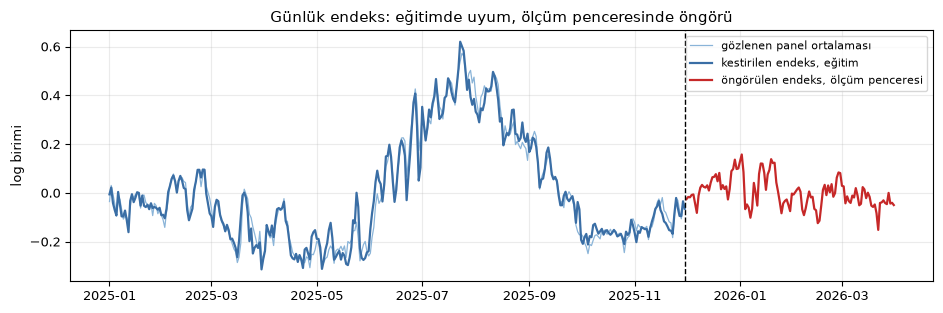

In [27]:
# Kesikli çizginin sağı ölçüm penceresi: orada endeks artık kestirim
# değil öngörü, çünkü o günlerin tüketimi modele hiç girmedi.
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.plot(ge_gozlem.tarih, ge_gozlem.endeks, color="#8ab4d8", lw=0.9,
        label="gözlenen panel ortalaması")
ax.plot(endeks_seri.index, endeks_seri.values, color="#3a6ea5", lw=1.6,
        label="kestirilen endeks, eğitim")
d_end = D.groupby("tarih").endeks.mean()
ax.plot(d_end.index, d_end.values, color="#c62828", lw=1.6,
        label="öngörülen endeks, ölçüm penceresi")
ax.axvline(SINAMA, color="k", ls="--", lw=1)
ax.set_ylabel("log birimi"); ax.legend(fontsize=8)
ax.set_title("Günlük endeks: eğitimde uyum, ölçüm penceresinde öngörü")
plt.tight_layout(); plt.show()

### 4.2 Trafo Seviyesi

Seviye, tahminin ağırlık merkezi: bölüm 1.6 hatanın büyük kısmının
günlük dalgalanmadan değil trafonun ortalamasını bilmemekten geldiğini
ölçmüştü. Buradaki asıl gerilim de basit. Trafonun kendi geçmişi en
bilgilendirici kaynak, ama kısa geçmişte gürültülü ve uzak ufukta
bayat. Aşağıdaki katmanların hepsi bu gerilimin bir kesitini
çözüyor.

Grup önceliği, dört kademeli. Genel ortalamadan başlayıp güç
sınıfı, ilçe çarpı güç sınıfı ve ilçe çarpı güç kademelerine iniyor;
her kademe bir üstüne $m=800$ ile büzülüyor. Trafolar kendi kanıt
ağırlıklarıyla katılıyor, yani üç günlük bir trafo grup ortalamasını
sürüklemiyor.

Bayatlık yasası. Trafonun kendi kanıtı, tahmin ufku büyüdükçe
değersizleşiyor:

$$s_i(h) = \frac{W_i\,\mathrm{ham}_i + m(h)\,g_i}{W_i + m(h)},
\qquad m(h) = 0{,}35\cdot 2^{h/45}$$

Uzak ufukta tahmin gruba kayıyor, yakın ufukta trafonun kendi
geçmişine güveniliyor.

Ölü muafiyeti. Dört koşulu birden sağlayan trafolar (ham seviye
eşik altı, kanıt ağırlığı yeterli, bütün dönem eşik altı, doksan
beşinci yüzdelik düşük) ayrı ele alınıyor. Kışın karanlık olan bir
sulama trafosu yazın uyanabiliyor; uyanma olasılığı ve uyandığındaki
seviye eğitim verisinden ölçülüyor, aylık bir ağırlıkla uygulanıyor.

Trafo bazlı mevsim genliği. Her trafo endekse aynı ölçüde tepki
vermiyor. $a_i$ katsayısı trafonun kendi geçmişinden kestiriliyor ve
$[0;\,1{,}2]$ aralığına kırpılıyor.

Profil, gün deseni ve tatil. Endeks bütün panele tek bir mevsim,
tek bir hafta sonu ve tek bir tatil sapması uyguluyor. Oysa sapma
bölgeye ve güce göre değişiyor: sanayi bayramda duruyor, mesken
durmuyor, sahilde tüketim artıyor çünkü nüfus oraya gidiyor. Üç
düzeltme bu ayrışmayı ilçe ve güç sınıfı bazında kademeli yumuşatmayla
ekliyor.

W kritik: iki yüz gün veri vermiş ama son iki aydır susmuş bir trafonun
gözlem sayısı yüksek, taze kanıtı neredeyse yok. Seviyeyi ne kadar kendi
geçmişine dayanacağına bu sayı karar veriyor.

In [28]:
OLU_ESIK = 3.0
AY_AGIRLIK = {4: 0.0, 5: 0.3, 6: 0.9, 7: 1.0, 8: 1.0, 9: 0.5}
SAHIL = ["ÇEŞME", "URLA", "SEFERİHİSAR", "DİKİLİ", "FOÇA", "KARABURUN",
         "GÜZELBAHÇE", "MENDERES", "SELÇUK"]
KENTSEL = ["KONAK", "BORNOVA", "KARABAĞLAR", "BUCA", "BAYRAKLI", "KARŞIYAKA",
           "ÇİĞLİ", "GAZİEMİR", "YUNUSEMRE", "ŞEHZADELER", "NARLIDERE", "BALÇOVA"]


# Trafonun mevsimden arındırılmış, yaşlanma ağırlıklı ham seviyesi ve
# yanında ne kadar taze kanıta dayandığı.
def ham_seviye(e, yarilanma=9.0):
    v = np.log1p(e.tuketim.to_numpy()) - e.endeks.to_numpy()
    w = (np.ones(len(e)) if yarilanma is None
         else 0.5 ** ((e.tarih.max() - e.tarih).dt.days.to_numpy() / yarilanma))
    t = pd.DataFrame({"g": e.tanim.to_numpy(), "vw": v * w, "w": w})
    top = t.groupby("g").agg(vw=("vw", "sum"), w=("w", "sum"))
    return top.vw / top.w.replace(0, np.nan), top.w


GRUP_KADEME = [("grup_guc", ["guc"], None),
               ("grup_ilce", ["ilce"], None),
               ("grup_ilce_gucsinif", ["ilce", "guc_sinif"], "grup_guc"),
               ("grup_ilce_guc", ["ilce", "guc"], "grup_ilce_gucsinif")]
GRUP_OZELLIK = [a for a, _, _ in GRUP_KADEME]

Trafonun kendi kanıtı yetmediğinde tahmin nereye düşecek? Grup
önceliği bunu cevaplıyor: genel ortalamadan başlayıp güç sınıfı, ilçe
çarpı güç sınıfı ve ilçe çarpı güç kademelerine iniyor, her kademe bir
üstüne büzülüyor.

Her kademe bir üstüne m=800 ile büzülüyor. Trafolar kendi kanıt
ağırlıklarıyla katılıyor, yani üç günlük bir trafo grup ortalamasını
sürüklemiyor.

In [29]:
# Dört kademeli grup önceliği: genel, güç sınıfı, ilçe x güç sınıfı, ilçe x
# güç.
def grup_oncelikleri(egitim, hedef, grup_yarilanma=12.0, grup_m=800.0):
    e, h = egitim.copy(), hedef.copy()
    ham_g, w_g = ham_seviye(e, grup_yarilanma)
    bilgi = e.groupby("tanim").agg(guc=("guc", "first"), ilce=("ilce", "first"))
    bilgi["ham"], bilgi["w"] = ham_g, w_g
    bilgi = bilgi.dropna(subset=["ham"])
    bilgi["hamw"] = bilgi.ham * bilgi.w
    bilgi["guc_sinif"] = pd.cut(bilgi.guc, GUC_KENAR, labels=GUC_ETIKET)
    genel = bilgi.hamw.sum() / bilgi.w.sum()

    tablolar = {}
    for ad, anahtar, ust in GRUP_KADEME:
        tam = bilgi.groupby(anahtar, observed=True)[["hamw", "w"]].sum()
        ust_deger = (genel if ust is None
                     else bilgi.groupby(anahtar, observed=True)[ust].mean())
        tablolar[ad] = ((tam.hamw + grup_m * ust_deger) / (tam.w + grup_m)).rename(ad)
        bilgi = bilgi.join(tablolar[ad], on=anahtar)

    e = e.join(bilgi[GRUP_OZELLIK], on="tanim")
    h["guc_sinif"] = pd.cut(h.guc, GUC_KENAR, labels=GUC_ETIKET)
    for ad, anahtar, _ in GRUP_KADEME:
        h = h.merge(tablolar[ad].reset_index(), on=anahtar, how="left")
    h = h.drop(columns="guc_sinif")
    for t in (e, h):
        for ad in ("grup_guc", "grup_ilce"):
            t[ad] = t[ad].fillna(genel)
        t["grup_ilce_gucsinif"] = t.grup_ilce_gucsinif.fillna(t.grup_guc)
        t["grup_ilce_guc"] = t.grup_ilce_guc.fillna(t.grup_ilce_gucsinif)
    return e, h

Yukarıdaki iki fonksiyon seviyenin tabanını kuruyor. Sırada
seviyenin üstüne binen dört ayrı sapma var: ölü trafoların yazın
uyanması, mevsim profilinin ilçe ve güç sınıfına göre ayrışması, gün
tipi deseninin bölgeye göre ters yönlere gitmesi ve tatilin sanayi ile
meskende farklı davranması. Dördü de aynı biçimde kuruluyor: sapmayı
gruptan ölç, üst kademeye büzüştür, bir $\lambda$ katsayısıyla
yumuşat.

In [30]:
# Karanlık trafonun yazın uyanma olasılığı ve uyandığındaki seviyesi.
def uyanma_parametreleri(e):
    kis = e[e.tarih.dt.month.isin([1, 2, 3, 12])]
    yaz = e[e.tarih.dt.month.isin([6, 7, 8])]
    k = kis.groupby("tanim").tuketim.agg(km="median",
                                         kp=lambda s: s.quantile(0.95), kn="size")
    y = yaz.groupby("tanim").tuketim.agg(ym="median", yn="size")
    t = k.join(y, how="inner")
    t = t[(t.kn >= 45) & (t.yn >= 45) & (t.km <= 20) & (t.kp < 20)]
    if len(t) < 15:
        return 0.0, 0.0
    u = t.ym > 20
    return float(u.mean()), float(np.log1p(t.ym[u]).mean()) if u.any() else 0.0


# Her (ilçe, güç sınıfı) için ayın panel endeksinden sapması.
def grup_mevsim_profili(e, lam=0.3, min_trafo=8):
    x = e.copy()
    x["ilce_"] = x.ilce.astype(str)
    x["gs"] = pd.cut(x.guc, GUC_KENAR, labels=GUC_ETIKET).astype(str)
    x["ay"] = x.tarih.dt.month
    sev = ham_seviye(x, None)[0]
    x["artik"] = np.log1p(x.tuketim) - x.tanim.map(sev) - x.endeks
    say = x.groupby(["ilce_", "gs"], observed=True).tanim.nunique()
    p = x.groupby(["ilce_", "gs", "ay"], observed=True).artik.mean()
    return p[p.index.droplevel("ay").map(say) >= min_trafo] * lam


def tatil_sutunlari(t):
    t = t.copy()
    for c in TATIL_TIP:
        t[c] = t.tarih.map(TAKVIM_GUN[c]).fillna(0).astype(int)
    t["gs"] = pd.cut(t.guc, GUC_KENAR, labels=GUC_ETIKET).astype(str)
    ilce_s = t.ilce.astype(str)
    t["tip"] = np.where(ilce_s.isin(SAHIL), "sahil",
                        np.where(ilce_s.isin(KENTSEL), "kentsel", "iç"))
    return t

Gün deseni ile tatil düzeltmesi aynı kalıbı paylaşıyor ama ayrı
duruyor, çünkü referansları farklı: gün deseni hafta içine göre sapmayı
ölçüyor, tatil düzeltmesi ise tatil olmayan güne göre. İkisi de ilçe
kademesinde ölçülüp bir üst kademeye büzülüyor.

Panel endeksi bunların ortalamasını yakalıyor ama ayrışmayı kaçırıyor:
hafta sonunda sahil artı, kentsel eksi, ortalaması sıfır.

In [31]:
# İlçe x güç sınıfı bazında gün tipi sapması.
def gun_deseni(e, h, m_ilce=300.0, lam=0.8):
    e, h = tatil_sutunlari(e), tatil_sutunlari(h)
    sev = ham_seviye(e, None)[0]
    e["artik"] = np.log1p(e.tuketim) - e.tanim.map(sev) - e.endeks
    for t in (e, h):
        t["gun_tipi"] = np.where((t.dini_bayram + t.resmi_tatil) > 0, "tatil",
                                 np.where(t.tarih.dt.dayofweek >= 5,
                                          "hafta_sonu", "hafta_ici"))
    grup = e.groupby(["ilce", "gs", "gun_tipi"], observed=True).artik.agg(["sum", "count"])
    ust = e.groupby(["gs", "gun_tipi"], observed=True).artik.mean()
    idx = grup.index.to_frame(index=False)
    ust_d = pd.MultiIndex.from_frame(idx[["gs", "gun_tipi"]]).map(ust)
    d_ilce = pd.Series((grup["sum"].to_numpy() + m_ilce * ust_d)
                       / (grup["count"].to_numpy() + m_ilce), index=grup.index)
    ref = d_ilce.xs("hafta_ici", level="gun_tipi")   # hafta içi referans
    cikti = []
    for t in (e, h):
        k = pd.MultiIndex.from_arrays([t.ilce, t.gs, t.gun_tipi])
        deger = pd.Series(k.map(d_ilce), index=t.index)
        taban = pd.Series(pd.MultiIndex.from_arrays([t.ilce, t.gs]).map(ref),
                          index=t.index)
        cikti.append(((deger - taban).fillna(0.0) * lam).to_numpy())
    return cikti

Tatil düzeltmesi aynı kalıbı izliyor ama referansı farklı: gün deseni
hafta içine göre sapmayı ölçüyordu, bu tatil olmayan güne göre ölçüyor.
Üç tatil tipi ayrı ayrı ele alınıyor, çünkü dini bayram, resmi tatil ve
arife farklı büyüklükte sapmalar üretiyor.

Endeks bütün panele tek bir tatil sapması uyguluyor, ama sapma bölgeye ve
güce göre çok değişiyor: sanayi bayramda duruyor, mesken durmuyor, sahilde
tüketim artıyor çünkü nüfus oraya gidiyor.

In [32]:
# Tatil sapmasını grup bazında düzeltir.
def tatil_duzeltmesi(egitim, hedef, m_ilce=400.0, m_tip=100.0, lam=0.5):
    e, h = tatil_sutunlari(egitim), tatil_sutunlari(hedef)
    sev = ham_seviye(e, None)[0]
    e["artik"] = np.log1p(e.tuketim) - e.tanim.map(sev) - e.endeks
    top_e = np.zeros(len(e)); top_h = np.zeros(len(h))
    for c in TATIL_TIP:
        alt = e[e[c] == 1]
        if len(alt) < 500:
            continue
        genel = alt.artik.mean()
        tip_g = alt.groupby(["tip", "gs"], observed=True).artik.agg(["sum", "count"])
        tip_d = (tip_g["sum"] + m_tip * genel) / (tip_g["count"] + m_tip)
        ilce_g = alt.groupby(["ilce", "gs"], observed=True).artik.agg(["sum", "count"])
        ust = ilce_g.index.to_frame(index=False)
        ust["tip"] = np.where(ust.ilce.astype(str).isin(SAHIL), "sahil",
                              np.where(ust.ilce.astype(str).isin(KENTSEL),
                                       "kentsel", "iç"))
        ust_deger = pd.MultiIndex.from_frame(ust[["tip", "gs"]]).map(tip_d)
        ilce_d = pd.Series((ilce_g["sum"].to_numpy() + m_ilce * ust_deger)
                           / (ilce_g["count"].to_numpy() + m_ilce), index=ilce_g.index)
        for t, birikim in ((e, "e"), (h, "h")):
            anahtar = pd.MultiIndex.from_arrays([t.ilce, t.gs])
            deger = pd.Series(anahtar.map(ilce_d), index=t.index)
            deger = deger.fillna(pd.Series(
                pd.MultiIndex.from_arrays([t.tip, t.gs]).map(tip_d), index=t.index))
            katki = (deger.fillna(genel) * t[c] * lam).to_numpy()
            if birikim == "e":
                top_e = top_e + katki
            else:
                top_h = top_h + katki
    return top_e, top_h

Şimdi parçalar tek formülde birleşiyor. Sıra önemli: grup
önceliği ve bayatlık büzülmesi seviyeyi belirliyor, ölü muafiyeti o
seviyenin üstüne yazıyor, mevsim genliği endeksin katkısını trafo
bazında ölçekliyor, profil ve gün deseni ile tatil en sona toplamsal
olarak ekleniyor.

In [33]:
# Tam seviye formülü: grup önceliği, bayatlık yasası, ölü muafiyeti,
# trafo bazlı mevsim genliği, profil, gün deseni ve tatil.
def seviye_kur(egitim, hedef, yarilanma=9.0, kanit_m=0.35, tau=45.0,
               m_a=2.0, a_ust=1.2, p_carpan=0.5):
    e, h = grup_oncelikleri(egitim, hedef)
    hk, wk = ham_seviye(e, yarilanma)
    capa = egitim.tarih.max()

    # 1) Bayatlık yasası: ufuk büyüdükçe trafonun kendi kanıtı değersizleşiyor.
    for t in (e, h):
        uf = np.maximum((t.tarih - capa).dt.days.to_numpy(), 0)
        m = kanit_m * 2.0 ** (uf / tau)
        hi = t.tanim.map(hk).to_numpy()
        wi = t.tanim.map(wk).fillna(0.0).to_numpy()
        gr = t.grup_ilce_guc.to_numpy()
        hi = np.where(np.isnan(hi), gr, hi)
        t["kanit"] = wi
        t["seviye"] = (hi * wi + m * gr) / (wi + m) + t.endeks.to_numpy()

    # 2) Ölü muafiyeti: dört koşulu sağlayan trafolar aylık uyanma olasılığıyla.
    ham_t, _ = ham_seviye(e, None)
    p95 = e.groupby("tanim").tuketim.quantile(0.95)
    olu = (hk < OLU_ESIK) & (wk >= 8.0) & (ham_t < OLU_ESIK) & (p95 < 20.0)
    p_uyan, sev_uyan = uyanma_parametreleri(e)
    p_uyan = p_uyan * p_carpan
    for t in (e, h):
        m = t.tanim.map(olu).fillna(False).to_numpy().astype(bool)
        if m.any():
            olu_sev = t.tanim.map(hk).to_numpy()[m]
            mevsim = t.tarih.dt.month.map(AY_AGIRLIK).fillna(0.0).to_numpy()[m]
            p = p_uyan * mevsim
            t.loc[m, "seviye"] = ((1 - p) * olu_sev + p * sev_uyan
                                  + t.endeks.to_numpy()[m])

    # 3) Trafo bazlı mevsim genliği, kırpılmış.
    sev_i = e.seviye - e.endeks
    yy = np.log1p(e.tuketim.to_numpy()) - sev_i.to_numpy()
    xx = e.endeks.to_numpy()
    s = pd.DataFrame({"g": e.tanim.to_numpy(), "xy": xx * yy,
                      "xx": xx * xx}).groupby("g")[["xy", "xx"]].sum()
    a = ((s.xy + m_a) / (s.xx + m_a)).clip(0.0, a_ust)
    for t in (e, h):
        t["seviye"] = (t.seviye - t.endeks) + t.tanim.map(a).fillna(1.0) * t.endeks

    # 4) Profil, gün deseni ve tatil düzeltmesi.
    pr = grup_mevsim_profili(e)
    for t in (e, h):
        kk = pd.MultiIndex.from_arrays([
            t.ilce.astype(str),
            pd.cut(t.guc, GUC_KENAR, labels=GUC_ETIKET).astype(str),
            t.tarih.dt.month])
        t["seviye"] = t.seviye + pd.Series(kk.map(pr), index=t.index).fillna(0.0)
    dg_e, dg_h = gun_deseni(e, h)
    e["seviye"] = e.seviye + dg_e
    h["seviye"] = h.seviye + dg_h
    dt_e, dt_h = tatil_duzeltmesi(e, h)
    e["seviye"] = e.seviye + dt_e
    h["seviye"] = h.seviye + dt_h
    return e, h, olu

Formülü ölçüm penceresinde koşturup tabanı çıkarıyorum.
Skoru üç ayrı okuyorum, çünkü tek sayı iki bloğu birbirine karıştırıyor:
geçmişi olan satırlarla geçmişsiz satırlar aynı mekanizmayla tahmin
edilmiyor.

In [34]:
E, D, OLU_MASKE = seviye_kur(E, D)
ham, W = ham_seviye(E)
# Grup önceliği artık satır bazında ve dört kademeli. Geçmişi olmayan
# trafonun tahmini bu değere düşüyor; bölüm 5 ve 5 bunu taban alıyor.
grup_oncelik = D.grup_ilce_guc.to_numpy()
D["taban"] = D.seviye.to_numpy()
D["W"] = D.kanit.to_numpy()
D["ufuk"] = (D.tarih - SINAMA).dt.days
artik = D.L.to_numpy() - D.taban.to_numpy()
TABAN_MSE = float((artik ** 2).mean())
gecmissiz = D.W.to_numpy() == 0

print("kanıt ağırlığı W: ortanca %.2f, yüzde 90 dilimi %.2f"
      % (np.median(W), np.percentile(W, 90)))
print("ölü ilan edilen trafo %d" % int(OLU_MASKE.sum()))
print("")

# Skor üç ayrı okunuyor: tek sayı iki bloğu birbirine karıştırıyor.
BLOK_TABAN = pd.DataFrame([
    ("tümü", len(D), np.sqrt(TABAN_MSE)),
    ("geçmişi olan", int((~gecmissiz).sum()),
     np.sqrt(float((artik[~gecmissiz] ** 2).mean()))),
    ("geçmişsiz", int(gecmissiz.sum()),
     np.sqrt(float((artik[gecmissiz] ** 2).mean()))),
], columns=["blok", "satır", "RMSLE"]).set_index("blok")
BLOK_TABAN["satır payı %"] = 100.0 * BLOK_TABAN["satır"] / len(D)
print("TABAN FORMÜLÜ, ölçüm penceresinde. MSE %.4f" % TABAN_MSE)
print(BLOK_TABAN.round({"RMSLE": 4, "satır payı %": 1}).to_string())
print("")

orn = np.random.default_rng(7).choice(len(D), size=min(40000, len(D)), replace=False)

kanıt ağırlığı W: ortanca 13.47, yüzde 90 dilimi 13.49
ölü ilan edilen trafo 106

TABAN FORMÜLÜ, ölçüm penceresinde. MSE 0.8538
               satır   RMSLE  satır payı %
blok                                      
tümü          444076  0.9240         100.0
geçmişi olan  382158  0.6755          86.1
geçmişsiz      61918  1.8185          13.9



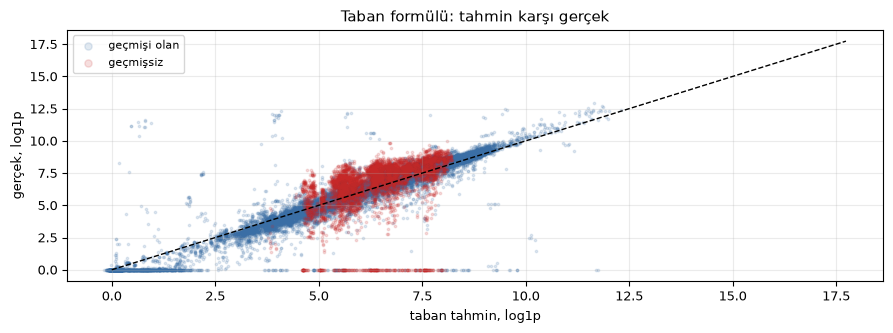

In [35]:
fig, ax = plt.subplots(figsize=(9.0, 3.4))
for ad_b, m, renk in (("geçmişi olan", ~gecmissiz, "#3a6ea5"),
                      ("geçmişsiz", gecmissiz, "#c62828")):
    k = orn[m[orn]]
    ax.scatter(D.taban.to_numpy()[k], D.L.to_numpy()[k], s=3, alpha=0.15,
               color=renk, label=ad_b)
lim = [0, float(max(D.L.max(), D.taban.max()))]
ax.plot(lim, lim, color="k", lw=1, ls="--")
ax.set_xlabel("taban tahmin, log1p"); ax.set_ylabel("gerçek, log1p")
ax.legend(fontsize=8, markerscale=3)
ax.set_title("Taban formülü: tahmin karşı gerçek")
plt.tight_layout(); plt.show()

del orn
gc.collect()
ZIRVE_BELLEK = max(ZIRVE_BELLEK, bellek_gb())

Kanıt ağırlığı bir üst sınıra doyuyor: belirli bir uzunluktan sonra ek
geçmiş, seviye kestirimine bilgi eklemiyor. Bu, bölüm 8'de uzun geçmiş
bandında ayrı bir model kurmanın neden kazandırmadığının da açıklaması.

Saçılımda iki blok arasındaki fark açıkça görünüyor: geçmişi olan
satırlarda noktalar köşegen etrafında toplanıyor, geçmişsiz satırlarda
ise tahmin dar bir banda sıkışıyor, çünkü o trafoların hepsi grup
önceliğine düşüyor. Bölüm 5 tam olarak bu bandı açıyor.

## 5. Geçmişsiz Trafolar İçin Cross-Sectional Model

Bölüm 4 seviyeyi kurdu, ama geçmişi olmayan trafoda o formül tamamen
grup önceliğine düşer. Bu bölüm, bölüm 3.2'nin tablosundaki $g_i$
terimini üretir.

Bölüm 4'ün son satırı problemi ortaya koydu: geçmişi olmayan trafoda
formül tamamen grup önceliğine düşüyor, yani bütün trafolara aynı
sayıyı veriyor. Bölüm 1.6 ise o bloğun satırların beşte biri ve hatanın
üçte ikisi olduğunu göstermişti.

Kurgu. Panel değil kesit: trafo başına **bir satır**. Bu bilinçli
bir seçim, çünkü geçmişi olmayan trafo için zaman ekseni diye bir şey
yok; tahmin etmem gereken tek bir sayı var, o trafonun seviyesi.

| | |
|---|---|
| Gözlem birimi | Bir trafo |
| Hedef ($y$) | Trafonun endeksten arındırılmış seviyesi, $\mathrm{ham}_i$. |
| Eğitim kümesi | Eğitim penceresinde geçmişi olan trafolar. |
| Uygulama kümesi | Geçmişi olmayan trafolar. |
| Model | LightGBM ve CatBoost, üçer tohum; iki öğrenicinin tahmini ortalanıyor. |
| Çıktı | Her geçmişsiz trafo için bir $g_i$ değeri, yani bölüm 4.2'nin grup önceliğinin yerine geçen kişiselleştirilmiş öncelik. |

Modelin özellikleri yalnız geçmişi olan trafolardan üretilir; sayıları
aşağıdaki hücrede `len(OZELLIK)` ile basılır. Tahmin edeceğim trafo bu referans kümesinde hiç yok, yani
kendi hedefi kendi özelliğine giremiyor.

| Özellik | Tanım | Neden |
|---|---|---|
| `lguc` | $\log(\text{guc})$, kurulu gücün logaritması | Elimdeki tek doğrudan büyüklük ölçüsü. Tek başına seviyenin $R^2$ 0,18'ini açıklıyor (bölüm 1.4) |
| `il_ort` | Trafonun ilindeki trafoların ortalama seviyesi. | Coğrafi taban seviye. |
| `bolge_ort` | Bölgesindeki ortalama seviye. | İlden daha ince kırılım. |
| `ilce_ort` | İlçesindeki ortalama seviye. | En ince coğrafi kırılım. |
| `bolge_n`, `ilce_n` | O hücredeki trafo sayısı. | Ortalamanın ne kadar güvenilir olduğunu modele söylüyor; üç trafodan hesaplanmış ortalama ile üç yüzden hesaplanmış aynı şey değil. |
| `komsu3`, `komsu10`, `komsu30` | Trafo kodunun sayısal olarak en yakın 3, 10 ve 30 komşusunun ortalama seviyesi. | `tanim` alanı sayısal bir kod ile başlıyor ve aynı fider üzerindeki trafolar ardışık kod alıyor. Yani kod komşuluğu, elimde koordinat olmadığı için coğrafi yakınlığın vekili |

Üç ayrı komşuluk yarıçapı (3, 10, 30) kullanmamın sebebi, doğru
yarıçapın önceden bilinmemesi: dar komşuluk gürültülü, geniş komşuluk
ilçe ortalamasına yaklaşıyor. Hangisinin ağır bastığını modele
bıraktım, cevabı bölüm 5.3'nin önem tablosunda.

Grup ortalamalarını neden leave-one-out yapmıyorum. Ders kitabının
tersini söylediği bir yer burası, o yüzden bölüm 5.4'te ölçüyorum.
Kısaca: uygulayacağım trafolar referans kümesinde zaten yok, yani
dışarıda bırakılacak bir katkı da yok. Buna karşılık leave-one-out,
ağaç modelinde **ters yönde bir sızıntı** açıyor.

In [36]:
def lokasyon_parcala(s):
    p = s.str.split(">")
    return p.str[0], p.str[:2].str.join(">"), s


# Trafo düzeyinde özellik tablosu; loo=True grup ortalamasından
# trafonun kendi katkısını çıkarır.
def kesitsel_tablo(e, hedef_index, loo=True, ek=None):
    ref = (e.assign(v=e.L - e.endeks).groupby("tanim")
             .agg(sev=("v", "mean"), guc=("guc", "first"), lok=("lokasyon", "first")))
    ref["il"], ref["bolge"], ref["ilce"] = lokasyon_parcala(ref.lok)
    ref["kod"] = pd.to_numeric(ref.index.str.extract(r"^(\d+)")[0], errors="coerce").values

    ek = D if ek is None else ek
    kimlik = (pd.concat([e[["tanim", "guc", "lokasyon"]], ek[["tanim", "guc", "lokasyon"]]])
              .groupby("tanim").first().reindex(hedef_index))
    M = pd.DataFrame(index=hedef_index)
    M["lguc"] = np.log(kimlik.guc.clip(lower=1))
    M["il"], M["bolge"], M["ilce"] = lokasyon_parcala(kimlik.lokasyon)
    M["kod"] = pd.to_numeric(pd.Series(hedef_index).str.extract(r"^(\d+)")[0],
                             errors="coerce").values

    kendi = M.index.isin(ref.index)
    kendi_sev = pd.Series(M.index.map(ref.sev), index=M.index)
    for c in ("il", "bolge", "ilce"):
        toplam = M[c].map(ref.groupby(c).sev.sum()).astype(float)
        adet = M[c].map(ref.groupby(c).sev.size()).astype(float)
        if loo:
            toplam = toplam.where(~kendi, toplam - kendi_sev)
            adet = adet.where(~kendi, adet - 1)
        M[c + "_ort"] = toplam / adet.replace(0, np.nan)
        M[c + "_n"] = adet

    rs = ref.dropna(subset=["kod"]).sort_values("kod")
    rk, rv = rs.kod.to_numpy(), rs.sev.to_numpy()
    yer = np.searchsorted(rk, M.kod.to_numpy())
    for k in (3, 10, 30):
        cikti = np.full(len(M), np.nan)
        for i, (kod, p) in enumerate(zip(M.kod.to_numpy(), yer)):
            if not np.isfinite(kod):
                continue
            lo, hi = max(0, p - 60), min(len(rk), p + 60)
            idx = np.arange(lo, hi)
            idx = idx[rk[idx] != kod]
            if len(idx):
                cikti[i] = rv[idx[np.argsort(np.abs(rk[idx] - kod))[:k]]].mean()
        M["komsu%d" % k] = cikti
    M["hedef"] = M.index.map(ref.sev)
    return M


OZELLIK = ["lguc", "il_ort", "bolge_ort", "ilce_ort", "ilce_n", "bolge_n",
           "komsu3", "komsu10", "komsu30"]

Tabloyu kurup iki kümeye ayırıyorum: hedefi olanlar eğitim kümesi,
olmayanlar uygulama kümesi.

In [37]:
tum_trafolar = pd.Index(sorted(set(E.tanim) | set(D.tanim)))
M = kesitsel_tablo(E, tum_trafolar, loo=False)
egitim_trafo = M[M.hedef.notna()]
hedef_trafo = M[M.hedef.isna()]
print("kesitsel model: %d trafo ile eğitiliyor, %d geçmişsiz trafoya uygulanıyor"
      % (len(egitim_trafo), len(hedef_trafo)))

kesitsel model: 4121 trafo ile eğitiliyor, 1223 geçmişsiz trafoya uygulanıyor


### 5.1 Model Çeşitliliği

LightGBM ve CatBoost aynı özellik kümesiyle, üçer tohumla eğitiliyor.
Tohumlar arası sapma raporlanıyor, çünkü bölüm 5.2'te söylendiği gibi
bu sapmanın iki katı anlamlılık eşiği. İki öğrenici kullanmamın sebebi doğruluk
değil **tümevarım önyargısı çeşitliliği**: tahminleri yüksek
korelasyonlu olsa bile artıkları farklı yerlerde yanılıyor, o yüzden
ortalamaları tek birinden daha kararlı. Bölüm 6 bu ortalamayı tek bir
düzeltme yönü olarak alıyor; korelasyon aşağıda basılıyor ve ikisini
ayrı yönler olarak tutmayı anlamsız kılacak kadar yüksek.

In [38]:
import lightgbm as lgb
from catboost import CatBoostRegressor

TOHUMLAR = (7, 17, 27)
# Sığ ağaçlar ve güçlü L2: girdi trafo başına birkaç bin satır ve
# özelliklerin çoğu grup ortalaması, yani derin ağaç ezberler.
LGB_PARAM = {"objective": "l2", "learning_rate": 0.05, "num_leaves": 15,
             "min_data_in_leaf": 40, "feature_fraction": 0.8,
             "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 5,
             "verbose": -1}

tahminler, ozet = {}, []
for ad in ("LightGBM", "CatBoost"):
    tohum_tahmini = []
    for s in TOHUMLAR:
        if ad == "LightGBM":
            model = lgb.train(dict(LGB_PARAM, seed=s),
                              lgb.Dataset(egitim_trafo[OZELLIK], egitim_trafo.hedef),
                              num_boost_round=300)
            tohum_tahmini.append(model.predict(hedef_trafo[OZELLIK]))
        else:
            model = CatBoostRegressor(iterations=400, depth=5, learning_rate=0.05,
                                      l2_leaf_reg=6, random_seed=s, verbose=0)
            model.fit(egitim_trafo[OZELLIK].fillna(-999), egitim_trafo.hedef)
            tohum_tahmini.append(model.predict(hedef_trafo[OZELLIK].fillna(-999)))
    P = np.column_stack(tohum_tahmini)
    tahminler[ad] = pd.Series(P.mean(axis=1), index=hedef_trafo.index)
    ozet.append({"öğrenici": ad, "tohum sayısı": len(TOHUMLAR),
                 "tohumlar arası sd": round(float(P.std(axis=1).mean()), 4),
                 "tahmin sd": round(float(P.mean(axis=1).std()), 4)})

print(pd.DataFrame(ozet).to_string(index=False))
print("")
print("iki öğrenicinin tahminleri arasındaki korelasyon %.4f"
      % np.corrcoef(tahminler["LightGBM"], tahminler["CatBoost"])[0, 1])
print("grup önceliğinin tek başına tahmin sd'si 0,0000 (sabit)")

öğrenici  tohum sayısı  tohumlar arası sd  tahmin sd
LightGBM             3             0.0879     1.0390
CatBoost             3             0.0556     0.9973

iki öğrenicinin tahminleri arasındaki korelasyon 0.9257
grup önceliğinin tek başına tahmin sd'si 0,0000 (sabit)


### 5.2 Gürültü Bandı

Bir doğrulama farkının anlamlı olup olmadığına karar vermeden önce
gürültünün ne kadar olduğunu ölçmek gerekir. Ölçüt şudur: aynı kurgu
farklı rastgele tohumlarla koşulduğunda skorlar arasındaki standart
sapmanın iki katı. Bu bandın altındaki farklar karar için
kullanılmaz.

Tohumun dokunduğu tek yer cross-sectional modeldir, çünkü taban formülü
deterministiktir. Bant bu yüzden burada ölçülür ve bölüm 6.4'te
düzeltmelerin kazancını yargılamak için kullanılır.

In [39]:
# Gürültü bandı: aynı kurgu beş tohumla, skorlar arası std'nin iki katı.
def gurultu_bandi(tohumlar=(11, 22, 33, 44, 55)):
    skor = []
    for s in tohumlar:
        m = lgb.train(dict(LGB_PARAM, seed=s),
                      lgb.Dataset(egitim_trafo[OZELLIK], egitim_trafo.hedef),
                      num_boost_round=300)
        p = pd.Series(m.predict(hedef_trafo[OZELLIK]), index=hedef_trafo.index)
        d = np.where(gecmissiz, D.tanim.map(p).fillna(0.0).to_numpy()
                     - D.grup_ilce_guc.to_numpy(), 0.0)
        E_d = float((d ** 2).mean())
        a = float((d * artik).mean() / E_d) if E_d > 0 else 0.0
        skor.append(np.sqrt(TABAN_MSE) - np.sqrt(max(TABAN_MSE - a * a * E_d, 0)))
    return np.array(skor)


BAND_SKOR = gurultu_bandi()
BAND = 2 * float(BAND_SKOR.std(ddof=1))
print("bes tohumla ölçülen kazanç, RMSLE:")
print("  " + "  ".join("%.5f" % x for x in BAND_SKOR))
print("ortalama %.5f | std %.5f" % (BAND_SKOR.mean(), BAND_SKOR.std(ddof=1)))
print("")
print("GÜRÜLTÜ BANDI (2 x std) = %.5f RMSLE" % BAND)
print("Bu bandın altındaki farklar karar için kullanılmıyor.")

bes tohumla ölçülen kazanç, RMSLE:
  0.00002  0.00003  0.00001  0.00000  0.00004
ortalama 0.00002 | std 0.00002

GÜRÜLTÜ BANDI (2 x std) = 0.00003 RMSLE
Bu bandın altındaki farklar karar için kullanılmıyor.


Tahminlerin standart sapması sıfırdan farklı, yani model geçmişsiz
trafolar arasında gerçekten ayrım yapıyor; oysa bölüm 4'ün formülü
hepsine aynı sayıyı veriyordu. Tohumlar arası sapma bu ayrımın çok
altında, yani sinyal gürültünün üstünde.

### 5.3 Kapasite ve Aşırı Uyum Denetimi

Model bir kez kurulduktan sonra sorulacak soru skorunun ne olduğu
değil, o skora sınırı neyin koyduğu. İki ihtimal var ve ikisi zıt yöne
işaret ediyor: model sinyali kaçıracak kadar katıysa esnetmek
gerekir, gürültüyü ezberleyecek kadar esnekse kısmak. Aşağıdaki
hücre hangisinin geçerli olduğunu ölçüyor. Eğitim trafolarının beşte biri ayrılıp doğrulama olarak
kullanılıyor; bu ayırma zamana göre değil rastgele, çünkü buradaki
problem kesitsel, her trafo bir satır ve zaman ekseni yok. Zaman kapısı
bir üst düzeyde, bölüm 2.3'te zaten kapatıldı.

In [40]:
# Kesitsel problem: bölme zamana göre değil rastgele. Zaman kapısı
# bir üst düzeyde, bölüm 2.3'te zaten kapatıldı.
rng_k = np.random.default_rng(7)
karisik = rng_k.permutation(len(egitim_trafo))
kes_i = int(0.8 * len(karisik))
alt_egt = egitim_trafo.iloc[karisik[:kes_i]]
alt_dog = egitim_trafo.iloc[karisik[kes_i:]]

kayit = {}
lgb.train(dict(LGB_PARAM, seed=7),
          lgb.Dataset(alt_egt[OZELLIK], alt_egt.hedef), num_boost_round=600,
          valid_sets=[lgb.Dataset(alt_egt[OZELLIK], alt_egt.hedef),
                      lgb.Dataset(alt_dog[OZELLIK], alt_dog.hedef)],
          valid_names=["eğitim", "doğrulama"],
          callbacks=[lgb.record_evaluation(kayit), lgb.log_evaluation(0)])
egr_e = np.array(kayit["eğitim"]["l2"])
egr_d = np.array(kayit["doğrulama"]["l2"])
en_iyi = int(np.argmin(egr_d)) + 1
print("doğrulama hatası en düşük %d. turda (%.4f); üretimde 300 tur kullanılıyor"
      % (en_iyi, egr_d.min()))
print("600. turda doğrulama %.4f" % egr_d[-1])

doğrulama hatası en düşük 283. turda (3.5075); üretimde 300 tur kullanılıyor
600. turda doğrulama 3.5431


Erken durdurma sorusu cevaplandı. İkinci soru kapasitenin kendisi:
kasten fazla esnek bir model kurup eğitim ve doğrulama hatalarını
üretimdeki modelle karşılaştırıyorum.

In [41]:
# Kasten fazla esnek model: çok yaprak, düğüm başına iki örnek, ceza yok.
asiri = lgb.train({"objective": "l2", "learning_rate": 0.05, "num_leaves": 255,
                   "min_data_in_leaf": 2, "lambda_l2": 0.0, "verbose": -1, "seed": 7},
                  lgb.Dataset(alt_egt[OZELLIK], alt_egt.hedef), num_boost_round=600)
olculu = lgb.train(dict(LGB_PARAM, seed=7),
                   lgb.Dataset(alt_egt[OZELLIK], alt_egt.hedef), num_boost_round=300)
kapasite = []
for ad_m, m_m in (("üretimdeki model", olculu), ("kasten fazla esnek", asiri)):
    kapasite.append({"model": ad_m,
        "eğitim MSE": round(float(np.mean((alt_egt.hedef - m_m.predict(alt_egt[OZELLIK])) ** 2)), 4),
        "doğrulama MSE": round(float(np.mean((alt_dog.hedef - m_m.predict(alt_dog[OZELLIK])) ** 2)), 4)})
print("")
KAPASITE = pd.DataFrame(kapasite)
print(KAPASITE.to_string(index=False))


             model  eğitim MSE  doğrulama MSE
  üretimdeki model      2.5697         3.5184
kasten fazla esnek      0.0000         4.0002


Üçüncü soru hangi özelliğin taşıdığı. Önem dağılımı aynı zamanda bir
sızıntı işareti; gerekçesi aşağıdaki okumada.

In [42]:
# taşıyan bir özellik olsaydı tablo tek bir satıra yığılırdı.
onem = pd.Series(olculu.feature_importance("gain"), index=OZELLIK).sort_values()
onem = 100 * onem / onem.sum()
print("")
print("kazanç payı, büyükten küçüğe:")
for ad_o, v_o in onem.sort_values(ascending=False).items():
    print("  %-12s %5.1f%%" % (ad_o, v_o))
komsu_pay = onem[[o for o in OZELLIK if o.startswith("komsu")]].sum()
print("")
print("log(güç) payı %.1f%%, kod komşuluğunun toplam payı %.1f%%"
      % (onem["lguc"], komsu_pay))
print("en yüksek paylı özellik: %s" % onem.idxmax())


kazanç payı, büyükten küçüğe:
  lguc          29.3%
  komsu30       21.8%
  komsu3        15.9%
  komsu10       14.5%
  ilce_ort       9.5%
  ilce_n         4.6%
  bolge_ort      2.6%
  bolge_n        1.5%
  il_ort         0.2%

log(güç) payı 29.3%, kod komşuluğunun toplam payı 52.3%
en yüksek paylı özellik: lguc


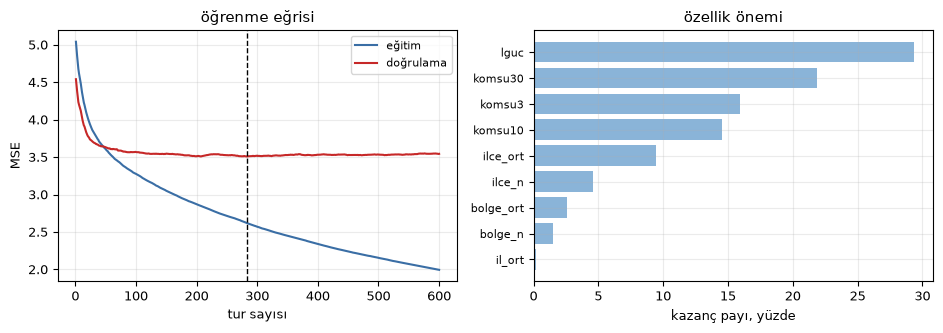

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax[0].plot(np.arange(1, len(egr_e) + 1), egr_e, color="#3a6ea5", label="eğitim")
ax[0].plot(np.arange(1, len(egr_d) + 1), egr_d, color="#c62828", label="doğrulama")
ax[0].axvline(en_iyi, color="k", ls="--", lw=1)
ax[0].set_xlabel("tur sayısı"); ax[0].set_ylabel("MSE"); ax[0].legend(fontsize=8)
ax[0].set_title("öğrenme eğrisi")
ax[1].barh(range(len(onem)), onem.values, color="#8ab4d8")
ax[1].set_yticks(range(len(onem))); ax[1].set_yticklabels(onem.index, fontsize=8)
ax[1].set_xlabel("kazanç payı, yüzde"); ax[1].set_title("özellik önemi")
plt.tight_layout(); plt.show()

Hücrenin cevabı üç yerde.

Erken durdurma gerekmiyor: doğrulama hatası belirli bir turdan sonra
düzleşiyor ve kayda değer yükselmiyor. Üretimde kullanılan 300 tur o
düzlüğün içinde kalıyor, yani model tur sayısına duyarlı değil.

Fazla esneklik de yardım etmiyor. Kasten derinleştirilmiş ve cezası
kaldırılmış model eğitim hatasını belirgin düşürüyor ama doğrulama
hatasını düşürmüyor. Üretimdeki model yetersiz esnek değil; sınırlayan
şey kapasite değil, bölüm 1.6'da ölçülen bilgi tavanı.

Önem tablosunda baskın olan `lguc` değil kod komşuluğu. Tek özellik
olarak `lguc` başta ama komşuluk ailesi toplamda onun neredeyse iki
katını taşıyor. Bu, bölüm 5'ün kurulum varsayımının doğrulanması:
ardışık trafo kodları aynı fider üzerinde toplandığı için komşuluk,
elimde koordinat olmadığı hâlde coğrafi yakınlığın işe yarar bir
vekili. Bölüm 1.4 `log(güç)`'ün seviyeyi ancak kısmen açıkladığını
ölçmüştü; geri kalanın bir kısmını komşuluk kapatıyor.

Dağılımın biçimi ayrıca sızıntıya karşı bir işaret. Hiçbir özellik tek
başına ezici değil, kazanç beş özelliğe yayılmış. Hedefi doğrudan
taşıyan bir özellik olsaydı tablo çok daha tepe ağırlıklı çıkardı;
bölüm 5.4'ün leave-one-out kurgusunda tam olarak bu oluyor.

### 5.4 Target Encoding Kurgusunun Sınanması

Hedef kodlamasında alışılmış refleks, bir satırın kendi hedefini grup
ortalamasından çıkarmaktır. Burada bu refleks yanlış ve sebebi ağaç
modelinin ne öğrenebildiğiyle ilgili.

Grup ortalaması leave-one-out hesaplandığında, bir trafonun kendi
değeri o ortalamanın içinde **eksi işaretle** duruyor:

$$\text{ort}^{\,-i} = \frac{S - x_i}{n-1}
\quad\Longrightarrow\quad
x_i = S - (n-1)\,\text{ort}^{\,-i}$$

Grup toplamı $S$ ve büyüklüğü $n$ o grubun bütün üyeleri için aynı
olduğundan, ağaç grubu tanıdığı anda kendi hedefini bu denklemden geri
kurabiliyor. Yani leave-one-out sızıntıyı kapatmıyor, işaretini
çeviriyor.

Aşağıdaki hücre iki kurguyu üç sayıyla karşılaştırıyor: eğitim içi
uyum, geçmişsiz trafolara verilen tahminlerin yayılımı, ve asıl olan,
o tahminlerin **ölçüm penceresinde gözlenen gerçek seviyeye** ne kadar
uyduğu.

In [44]:
# Aynı model, grup ortalamaları leave-one-out hesaplanmış hâliyle.
M_loo = kesitsel_tablo(E, tum_trafolar, loo=True)
egitim_loo, hedef_loo = M_loo[M_loo.hedef.notna()], M_loo[M_loo.hedef.isna()]

# Transfer sınavı: geçmişsiz trafonun ölçüm penceresinde GÖZLENEN seviyesi.
gozlenen_seviye = D.groupby("tanim").L.mean()

karsilastirma = []
for etiket, egt, hdf in (("leave-one-out yok", egitim_trafo, hedef_trafo),
                         ("leave-one-out var", egitim_loo, hedef_loo)):
    m = lgb.train(dict(LGB_PARAM, seed=7),
                  lgb.Dataset(egt[OZELLIK], egt.hedef), num_boost_round=300)
    ic = 1 - np.mean((egt.hedef - m.predict(egt[OZELLIK])) ** 2) / np.var(egt.hedef)
    tah = pd.Series(m.predict(hdf[OZELLIK]), index=hdf.index)
    ortak = gozlenen_seviye.reindex(tah.index).dropna()
    transfer = 1 - np.mean((ortak - tah.reindex(ortak.index)) ** 2) / np.var(ortak)
    karsilastirma.append({"kurgu": etiket, "eğitim içi R2": round(float(ic), 4),
                          "tahmin sd": round(float(tah.std()), 4),
                          "gerçek seviyeye R2": round(float(transfer), 4)})
    if etiket == "leave-one-out var":
        model_loo, hedef_loo_tahmin = m, tah

print(pd.DataFrame(karsilastirma).to_string(index=False))

            kurgu  eğitim içi R2  tahmin sd  gerçek seviyeye R2
leave-one-out yok         0.4801     1.0421              0.0731
leave-one-out var         0.9975     0.3324              0.0206


## 6. Düzeltme Yönleri ve Katsayı Çözümü

Bölüm 4 ve 5 tahminin tabanını kurdu. Bu bölüm tabanın sistematik
olarak kaçırdığı artığı hedefler.

Bir düzeltme yönü, her satır için bir sayı üreten $d_k$ vektörüdür.
Tahmine bir katsayıyla eklenir ve o katsayı elle seçilmez, doğrulama
artığından çözülür. Artık $r = \log(1+y) - \text{taban}$ olmak üzere,
tek bir yön için en iyi katsayı şudur:

$$\alpha_k^{*} = \frac{E[d_k\, r]}{E[d_k^2]}$$

Yönler birbirine dik olmadığı için hepsi birlikte çözülür:

$$b_k = E[d_k\, r], \qquad H_{kj} = E[d_k\, d_j], \qquad
\alpha = \left(H + \theta\,\mathrm{diag}(H)\right)^{-1} b$$

Burada $b_k$ yönün artıkla örtüşmesini, $H$ ise yönlerin birbiriyle
örtüşme matrisini gösterir. Ceza düz ridge değil ölçeklidir. Bunun
sebebi şudur: $b_k$'nin ölçüm varyansı $E[d_k^2]$ ile orantılıdır, yani
büyük normlu bir yönün katsayısı daha gürültülü kestirilir ve daha çok
cezalandırılması gerekir. Elde edilen kazanç kapalı formda
$\Delta\mathrm{MSE} = 2\alpha^{\top}b - \alpha^{\top}H\alpha$ olur.

Bölüm 6.2 ile 6.4 aynı denklemi çözer, farkları veridedir. Bölüm 6.2
denklemi tek bir ölçüm penceresinde çözer ve yöntemi görünür kılar;
oradaki katsayılar teşhis amaçlıdır, nihai tahmine girmez. Bölüm 6.4
ise aynı denklemi üç ayrı zaman katında çözer, katsayıyı her katın
dışında sınar ve gönderim dosyasına giren değerleri üretir. Kısacası
6.2 yöntemi gösterir, 6.4 katsayıyı üretir.

### 6.1 Düzeltme Yönlerinin Kurulması

Aşağıdaki yönlerin her biri, taban formülünün sistematik olarak
bıraktığı belirli bir artığı hedefliyor ve hiçbiri ölçüm penceresinin
hedefini görmüyor. Kaç yön kurulduğu ve kaçının çözüme girdiği bölüm
5.1'in son hücresinde `len(YON)` ile basılıyor; metinde elle yazılmış
bir sayı yok.

| Yön | Ne yakalıyor |
|---|---|
| `geçmişsizBlok` | Bölüm 5'ün kesitsel kestiriminin grup önceliğinden sapması, yalnız geçmişsiz satırlarda. |
| `kenar` | Veri boşluğunun ve girişin kenarındaki kısmi gün okumaları ham seviyeyi aşağı çekiyor; satır tipine göre ölçülmüş dip geri ekleniyor. |
| `kesinlik` | Kanıt ağırlığı, trafonun kendi gürültüsüyle ölçekleniyor: sakin bir trafonun aynı gün sayısı daha güvenilir kanıt. |
| `oluEndeks` | Endeks, son otuz gününde sönen trafolar dışarıda bırakılarak yeniden kestiriliyor. |
| `d_C` | Tahminin grup önceliğine duyarlılığı, $m(h)/(W_i+m(h))$, merkezlenmiş. |
| `bosluk` | Veri boşluğu kenarındaki satırların sistematik düşük okunması. |
| `trafoDow` | Trafonun kendi haftalık deseni; gün deseni tabanda yalnız grup düzeyinde. |
| `CDD` ve `HDD` | Trafo başına soğutma ve ısıtma tepkisi, çıpadaki havadan sapmayla çarpılmış. Ölçüm penceresi Aralık-Mart olduğu için `CDD` orada tam sıfır kalıyor ve hücre onu eliyor; gerçek tahmin penceresi Nisan-Temmuz olduğundan orada elenmiyor. |

Yönlerin dördü taban zincirinin bir parçasını yamalayıp farkı alarak
kuruluyor (`kenar`, `kesinlik`, `oluEndeks` ve dolaylı olarak `d_C`).
Bu kurgu, şu düzeltme olsaydı tahminin ne kadar değişeceği sorusunun
tam karşılığı.

Yönleri tek bir fonksiyonda kuruyorum. Sebebi tekrar değil doğruluk:
aynı fonksiyon hem bölüm 6.4'ün çapraz doğrulama katlarında hem bölüm
8'in nihai tahmininde çağrılıyor, yani katsayının çözüldüğü yön ile
uygulanan yön tanım olarak aynı oluyor.

Kapanış ofseti dilimin KENDİ son gününe göre tanımlı, panelin son gününe
göre değil; yoksa hiç susmamış trafolar da kapanış sayılırdı.

In [45]:
# Kenar: kısmi gün okuması ham seviyeyi aşağı çekiyor.
KENAR_OFSET = {"dogum_tekil": 0.781, "dogum_toplu": 0.172, "dogum+1": 0.052,
               "kapanis": 0.996, "donus": 0.770, "bosluk_oncesi": 0.988}
TOPLU_ESIK = 51


# Satır tipine göre ham seviyenin ne kadar aşağı çekildiği.
def kenar_ofset(e):
    d = e[["tanim", "tarih"]].reset_index(drop=True)
    duzen = np.lexsort((d.tarih.to_numpy(), d.tanim.to_numpy()))
    sira = np.argsort(duzen)
    o = d.iloc[duzen].copy()
    g = o.groupby("tanim", sort=False)
    son_gun = e.tarih.max()
    ilk, onc, snr = g.cumcount(), g.tarih.shift(1), g.tarih.shift(-1)
    grp_son = g.tarih.transform("max")
    v = np.zeros(len(o))
    panel0 = np.datetime64(e.tarih.min())
    gun = o.tarih.to_numpy()
    dg = (ilk == 0).to_numpy()
    # Öncelik: doğum < doğum+1 < kapanış < dönüş < boşluk öncesi.
    parti = pd.Series(gun[dg]).value_counts()
    v[dg] = np.where(pd.Series(gun[dg]).map(parti).to_numpy() >= TOPLU_ESIK,
                     KENAR_OFSET["dogum_toplu"], KENAR_OFSET["dogum_tekil"])
    v[dg & (gun == panel0)] = 0.0          # panel başı doğum değil
    v[(ilk == 1).to_numpy()] = KENAR_OFSET["dogum+1"]
    v[((o.tarih == grp_son) & (grp_son < son_gun - pd.Timedelta(days=3))).to_numpy()] = \
        KENAR_OFSET["kapanis"]
    v[((onc.notna()) & ((o.tarih - onc).dt.days > 1)).to_numpy()] = KENAR_OFSET["donus"]
    v[((snr.notna()) & ((snr - o.tarih).dt.days > 1)).to_numpy()] = KENAR_OFSET["bosluk_oncesi"]
    return v[sira]


def ham_kenar(e, yarilanma=9.0):
    v = np.log1p(e.tuketim.to_numpy()) - e.endeks.to_numpy() + kenar_ofset(e)
    w = (np.ones(len(e)) if yarilanma is None
         else 0.5 ** ((e.tarih.max() - e.tarih).dt.days.to_numpy() / yarilanma))
    t = pd.DataFrame({"g": e.tanim.to_numpy(), "vw": v * w, "w": w})
    top = t.groupby("g").agg(vw=("vw", "sum"), w=("w", "sum"))
    return top.vw / top.w.replace(0, np.nan), top.w

İkinci kusur kanıt ağırlığında. Bölüm 4.2 bir trafonun kaç gün veri
verdiğini sayıyor ama ne kadar sakin olduğuna bakmıyor. Aynı gün sayısı,
gürültüsüz bir trafoda çok daha güvenilir kanıt; aşağıdaki yama ağırlığı
trafonun kendi varyansıyla ölçekliyor.

In [46]:
# Kesinlik: kanıt ağırlığı trafonun kendi gürültüsüyle ölçekleniyor.
K_KESINLIK = 4.0


# Trafonun YEREL ortalaması etrafındaki varyans; sürüklenme sayılmaz.
def sigma2(e):
    v = np.log1p(e.tuketim.to_numpy()) - e.endeks.to_numpy()
    t = pd.DataFrame({"g": e.tanim.to_numpy(), "d": e.tarih.to_numpy(), "v": v})
    t = t.sort_values(["g", "d"])
    yerel = t.groupby("g", sort=False).v.transform(
        lambda s: s.rolling(63, center=True, min_periods=8).mean())
    t["e2"] = (t.v - yerel) ** 2
    z = t.groupby("g").e2.agg(["mean", "size"])
    return z["mean"], z["size"]


def ham_kesinlik(e, yarilanma=9.0):
    v = np.log1p(e.tuketim.to_numpy()) - e.endeks.to_numpy()
    w = (np.ones(len(e)) if yarilanma is None
         else 0.5 ** ((e.tarih.max() - e.tarih).dt.days.to_numpy() / yarilanma))
    t = pd.DataFrame({"g": e.tanim.to_numpy(), "vw": v * w, "w": w})
    top = t.groupby("g").agg(vw=("vw", "sum"), w=("w", "sum"))
    s2, n = sigma2(e)
    med = float(s2[n >= 20].median())
    olcek = (med / s2.replace(0, np.nan)).clip(1.0 / K_KESINLIK, K_KESINLIK)
    olcek = olcek.where(n >= 8, 1.0).reindex(top.index).fillna(1.0)
    return top.vw / top.w.replace(0, np.nan), top.w * olcek

Üçüncüsü endeksin kendisiyle ilgili. Günlük endeks dengeli panelden
hesaplanıyor, ama o panelde son otuz gününde sönmüş trafolar da var ve
onların düşüşü mevsim etkisi gibi okunuyor. Bu yama onları dışarıda
bırakıp endeksi yeniden kuruyor.

In [47]:
# OluEndeks: sönen trafolar endeksi kirletiyor.
SONME_ESIK = 2.0


def endeks_olusuz(e):
    gs = e.groupby("tanim").tarih.nunique()
    panel = gs[gs == e.tarih.nunique()].index
    alt = e[e.tanim.isin(panel)].copy()
    alt["log_t"] = np.log1p(alt.tuketim)
    son = alt[alt.tarih > alt.tarih.max() - pd.Timedelta(days=30)]
    m_tum = alt.groupby("tanim").log_t.mean()
    m_son = son.groupby("tanim").log_t.mean().reindex(m_tum.index)
    olu = m_tum.index[(m_son - m_tum) <= -SONME_ESIK]
    kalan = alt[~alt.tanim.isin(olu)].copy()
    if kalan.tanim.nunique() < 10:
        return gunluk_endeks(e)
    kalan["sapma"] = kalan.log_t - kalan.groupby("tanim").log_t.transform("mean")
    return (kalan.groupby("tarih").sapma.mean().rename("endeks").reset_index(),
            kalan.tanim.nunique())

İlk üç yön seviyenin kendi kurgusundaki üç kusuru
hedefliyordu. Sıradaki üçü veriden ve dış kaynaktan geliyor: ölçüm
boşluklarının kenarı, trafonun kendi haftalık deseni ve trafo başına
hava tepkisi. Hava eğimleri yalnız bilgi penceresinde kestiriliyor ve
tahmin gününün sıcaklığı, aynı pencerenin ortalamasına göre sapma
olarak giriyor; yani mutlak sıcaklık değil, çıpaya göre fark.

In [48]:
# Bosluk: veri boşluklarının kenarı.
SEV_BOSLUK = {("ilk", 0): -0.6356, ("sonra", 0): -0.7663, ("sonra", 1): -0.1243,
              ("once", 0): -1.1089, ("once", 1): -0.2123, ("once", 4): -0.1333,
              ("once", 15): -0.0972, ("once", 31): -0.1012, ("son", 0): -0.7866}
KOVA_BOSLUK = [(0, 0, 0), (1, 3, 1), (4, 14, 4), (15, 30, 15), (31, 60, 31)]


# Her satırın en yakın veri boşluğu kenarına uzaklığı ve o kenarın tipi.
def bosluk_kenari(veri):
    ilk_gun, son_gun = veri.tarih.min(), veri.tarih.max()
    parca = []
    for t, alt in veri.groupby("tanim", sort=False):
        g = pd.DatetimeIndex(np.sort(alt.tarih.unique()))
        gi = (g - ilk_gun).days.to_numpy()
        kop = np.where(np.diff(gi) > 1)[0]
        ken = []
        if gi[0] > 0:
            ken.append((gi[0], "ilk"))
        for k in kop:
            ken.append((gi[k], "once")); ken.append((gi[k + 1], "sonra"))
        if g[-1] < son_gun:
            ken.append((gi[-1], "son"))
        if not ken:
            continue
        kp = np.array([k for k, _ in ken])
        kv = np.array([v for _, v in ken], dtype=object)
        dd = np.abs(gi[:, None] - kp[None, :])
        j = dd.argmin(axis=1)
        parca.append(pd.DataFrame({"tanim": t, "tarih": g,
                                   "uz": dd[np.arange(len(gi)), j], "tip": kv[j]}))
    return pd.concat(parca, ignore_index=True) if parca else None

Trafonun kendi haftalık deseni ayrı bir yön, çünkü bölüm 4.2'nin gün
deseni düzeltmesi yalnız ilçe çarpı güç sınıfı düzeyinde çalışıyor. Bir
trafonun kendine özgü hafta sonu davranışı orada ortalamaya karışıyor.

In [49]:
# TrafoDow: trafonun kendi haftalık deseni.
MIN_DOW = 8


# (trafo, gün) -> düzeltme; ampirik Bayes ile büzülmüş, trafo içinde sıfır toplamlı.
def dow_deseni(e):
    d = e[["tanim", "tarih", "tuketim", "ilce", "guc"]].copy()
    d["lg"] = np.log1p(d.tuketim)
    d["dow"] = d.tarih.dt.dayofweek
    d["Ld"] = d.lg - d.tarih.map(d.groupby("tarih").lg.mean()).to_numpy()
    d = d.sort_values(["tanim", "tarih"])
    yerel = (d.groupby("tanim", sort=False).Ld
             .transform(lambda s: s.rolling(63, center=True, min_periods=10).mean()))
    d["r"] = d.Ld - yerel
    d = d[d.r.notna()]
    d["r"] = d.r - d.dow.map(d.groupby("dow").r.mean()).to_numpy()
    d["gs"] = pd.cut(d.guc, GUC_KENAR, labels=GUC_ETIKET).astype(str)
    d["hucre"] = d.ilce.astype(str) + "|" + d.gs
    gd = d.groupby(["hucre", "dow"]).r.mean()
    d["r"] = d.r - pd.MultiIndex.from_arrays([d.hucre, d.dow]).map(gd).to_numpy()
    d["hafta"] = d.tarih.dt.isocalendar().week.astype(int) % 2
    A = d.groupby(["tanim", "dow"]).agg(ort=("r", "mean"), n=("r", "size"), var=("r", "var"))
    A = A[A.n >= MIN_DOW]
    T = d.groupby(["tanim", "dow", "hafta"]).r.mean().unstack("hafta")
    T = T.reindex(A.index).dropna()
    if len(T) < 30:
        return None
    # Gerçek varyans tek ve çift haftaların KOVARYANSI: gürültü sinyal sanılmasın.
    V = float(np.cov(T[0].to_numpy(), T[1].to_numpy(), ddof=1)[0, 1])
    A["u"] = A.ort * V / (V + A["var"] / A.n)
    return (A.u - A.groupby("tanim").u.transform("mean"))

Hava yönlerinin iki parçası var: trafo başına eğim ve satır başına
hava değeri. Eğim yalnız bilgi penceresinde kestiriliyor, sonra tahmin
gününün havası bu pencerenin ortalamasına göre sapma olarak çarpılıyor.
Mutlak sıcaklık değil, çıpaya göre fark.

In [50]:
# CDD ve HDD: trafo başına hava tepkisi.
M_BUZ = 200.0


# Trafo başına v ~ x eğimi, kanıtı kadar güvenilip gerisi gruba büzülüyor.
def hava_egimi(e, xkol, bilgi, min_n=30):
    t = pd.DataFrame({"g": e.tanim.to_numpy(), "x": e[xkol].to_numpy(), "v": e.v.to_numpy()})
    t["xv"] = t.x * t.v
    t["xx"] = t.x * t.x
    a = t.groupby("g").agg(n=("x", "size"), sx=("x", "sum"), sv=("v", "sum"),
                           sxv=("xv", "sum"), sxx=("xx", "sum"))
    kov = a.sxv - a.sx * a.sv / a.n
    S = a.sxx - a.sx ** 2 / a.n
    ok = (a.n >= min_n) & (S > 1e-9)
    b, S = kov[ok] / S[ok], S[ok]
    bg = b.groupby(bilgi.gs.reindex(b.index)).transform("mean")
    return (S * b + M_BUZ * bg) / (S + M_BUZ)


# Satır bazında hava değeri: trafonun ilinin o günkü ölçümü.
def hava_sutunu(cerceve, kol):
    if "%s_izmir" % kol not in GUN_TABLO.columns:
        return np.zeros(len(cerceve))
    g = GUN_TABLO.set_index("tarih")
    izm = cerceve.il.to_numpy() == "İZMİR"
    return np.where(izm, cerceve.tarih.map(g["%s_izmir" % kol]).to_numpy(),
                    cerceve.tarih.map(g["%s_manisa" % kol]).to_numpy())

Yönlerin tamamı tek fonksiyonda kuruluyor. İmzasındaki ayrım
bu bölümün en kritik parçası: `e` yalnız bilgi penceresi, `d` tahmin
edilecek satırlar. Yönü üreten her istatistik `e` üzerinden
hesaplanıyor, `d` yalnız uygulanıyor. Bölüm 6.4'te aynı fonksiyon
çapraz doğrulama katlarında çağrıldığında bu ayrım, doğrulama
penceresinin hedefinin kestirime sızmasını engelleyen tek mekanizma.

e: bilgi penceresi, d: tahmin edilecek satırlar, taban: d üzerindeki taban
tahmin. Hiçbir yön d'nin hedefini kullanmıyor; her istatistik e'den.

Endeks bu iki yamadan etkilenmiyor, o yüzden yeniden kurulmuyor.
seviye_kur kendi sütunlarını ekliyor; ikinci çağrıyı temiz çerçeveyle
yapmazsak birleştirme çakışıyor.

In [51]:
# Seviye kurgusundan doğan yönler: geçmişsiz blok, iki yamalı yön, ölü
# trafosuz endeks ve grup önceliğine duyarlılık.
def yonleri_seviye(e, d, taban, grup, tahmin_lgb, tahmin_cat, ufuk_gun):
    gecmissiz = d.kanit.to_numpy() == 0
    canli = ~gecmissiz
    Y = {}

    # 1) Geçmişsiz blok: kesitsel modelin grup önceliğinden sapması.
    ort = 0.5 * (d.tanim.map(tahmin_lgb).fillna(0.0).to_numpy()
                 + d.tanim.map(tahmin_cat).fillna(0.0).to_numpy())
    Y["geçmişsizBlok"] = np.where(gecmissiz, ort - grup, 0.0)

    # 2) Yamalı yönler: seviyeyi başka bir ham tanımıyla kurup farkı al.
    EK_SUTUN = GRUP_OZELLIK + ["kanit", "seviye"]

    def _temiz(t):
        return t.drop(columns=[c for c in EK_SUTUN if c in t.columns])

    _orj = globals()["ham_seviye"]
    for ad, yama in (("kenar", ham_kenar), ("kesinlik", ham_kesinlik)):
        globals()["ham_seviye"] = yama
        try:
            _, dy, _ = seviye_kur(_temiz(e), _temiz(d))
        finally:
            globals()["ham_seviye"] = _orj
        Y[ad] = dy.seviye.to_numpy() - taban

    # 3) oluEndeks: endeksin kendisi değişiyor, zincir baştan kuruluyor.
    _orj_ge = globals()["gunluk_endeks"]
    globals()["gunluk_endeks"] = endeks_olusuz
    try:
        eo, do, _ = endeks_ekle(_temiz(e).drop(columns="endeks"),
                                _temiz(d).drop(columns="endeks"))
        _, do, _ = seviye_kur(eo, do)
    finally:
        globals()["gunluk_endeks"] = _orj_ge
    Y["oluEndeks"] = np.maximum(do.seviye.to_numpy(), 0.0) - np.maximum(taban, 0.0)

    # 4) d_C: tahminin grup önceliğine duyarlılığı.
    m_h = 0.35 * 2.0 ** (np.maximum(ufuk_gun, 0) / 45.0)
    wi = d.kanit.to_numpy()
    turev = m_h / (wi + m_h)
    dC = np.where(canli, turev, 0.0)
    if canli.any():
        dC = np.where(canli, dC - dC[canli].mean(), 0.0)
    Y["d_C"] = dC
    return Y

Kalan üç yön seviyenin kurgusuyla değil verinin kendisiyle ilgili,
o yüzden ayrı fonksiyonlarda. Sondaki sarmalayıcı üçünü tek sözlükte
topluyor ve sırayı sabitliyor; yön adlarının sırası hem katsayıların
çözüldüğü yerde hem üretimde aynı olmak zorunda.

In [52]:
# Verinin kendi biçiminden doğan yönler: boşluk kenarı ve trafonun
# kendi haftalık deseni.
def yonleri_veri(e, d):
    Y = {}

    # 5) bosluk: veri boşluğu kenarındaki satırlar.
    KT = bosluk_kenari(d)
    db = np.zeros(len(d))
    if KT is not None:
        tid = d[["tanim", "tarih"]].merge(KT, on=["tanim", "tarih"], how="left")
        tp, uz = tid.tip.to_numpy(), tid.uz.to_numpy()
        for a, b, anah in KOVA_BOSLUK:
            for k in ("ilk", "sonra", "once", "son"):
                if (k, anah) not in SEV_BOSLUK:
                    continue
                db[(tp == k) & (uz >= a) & (uz <= b)] = -SEV_BOSLUK[(k, anah)]
    Y["bosluk"] = db

    # 6) trafoDow: trafonun kendi haftalık deseni.
    u = dow_deseni(e)
    if u is None:
        Y["trafoDow"] = np.zeros(len(d))
    else:
        val = pd.MultiIndex.from_arrays([d.tanim, d.tarih.dt.dayofweek]).map(u)
        Y["trafoDow"] = pd.Series(val, index=d.index).fillna(0.0).to_numpy()
    return Y

In [53]:
# 7) CDD ve HDD: trafo başına hava tepkisi, çıpadaki havadan sapma ile.
def yonleri_hava(e, d):
    Y = {}
    ev = e.assign(v=np.log1p(e.tuketim.to_numpy()) - e.endeks.to_numpy())
    bilgi = e.groupby("tanim").agg(guc=("guc", "first"))
    bilgi["gs"] = pd.cut(bilgi.guc, GUC_KENAR, labels=GUC_ETIKET).astype(str)
    capa = e.tarih.max()
    onc = ev[ev.tarih > capa - pd.Timedelta(days=60)]
    for ad in ("cdd", "hdd"):
        ev[ad] = hava_sutunu(ev, ad)
        dv = hava_sutunu(d, ad)
        if not np.any(ev[ad].to_numpy() > 0):
            Y[ad.upper()] = np.zeros(len(d))
            continue
        alt = ev[ev[ad] > 0]
        b = hava_egimi(alt, ad, bilgi)
        cipa = float(hava_sutunu(onc, ad).mean())
        Y[ad.upper()] = d.tanim.map(b).fillna(0.0).to_numpy() * (dv - cipa)
    return Y

In [54]:
# Üçünü tek sözlükte topluyor. Sıra sabit: yön adlarının sırası hem
# katsayıların çözüldüğü yerde hem üretimde aynı olmak zorunda.

Kalan yönler iki aileden geliyor. Birincisi yapısal göstergeler:
taban formülünün bir satır sınıfına tekdüze uyguladığı kaymayı serbest
bırakıyorlar. İkincisi seviye yamaları: bir sabiti değiştirip farkı
alıyorlar, yani düzeltmenin ne kadar olması gerektiğini veriden
soruyorlar.

Ağaç yönü satır düzeyinde çalışıyor ve taban formülünün
kullanmadığı öznitelikleri görüyor: sıcaklık uçları, yağış, bayram
ayrıntıları ve trafonun kendi geçmiş istatistikleri.

Endeks yalnız yirmi dokuz sütunla kuruluyor; satır düzeyli ağaç ise sıcaklık uçları, yağış ve bayram ayrıntıları dahil elli beş sütunu görüyor.

In [55]:
# Satır düzeyli ağaç günlük tablonun tam sürümünü kullanıyor.
HAVA_KOL = ["sicaklik_ort", "sicaklik_min", "sicaklik_maks", "hissedilen_ort",
            "nem_ort", "yagis_top", "ruzgar_ort", "ruzgar_maks", "bulut_ort",
            "isinim_top", "hdd", "cdd"]
TAKVIM_KOL = ["resmi_tatil", "hafta_sonu", "tatil_gunu", "dini_bayram",
              "milli_bayram", "arife", "kopru_gunu", "tatil_var_gelecek_3g",
              "tatil_var_gelecek_7g", "tatil_var_gelecek_15g",
              "tatil_vardi_gecmis_3g", "tatil_vardi_gecmis_7g",
              "sonraki_tatile_gun", "ramazan_bayrami", "kurban_bayrami",
              "bayram_gun_no", "bayram_uzunlugu", "bayram_son_gun",
              "dini_bayrama_mesafe", "bayram_hafta_ici", "turizm_sezonu",
              "sulama_sezonu", "okul_donemi"]
TARIH_KOL = ["haftanin_gunu", "ay", "ayin_gunu", "yilin_gunu", "yilin_haftasi",
             "gun_sin", "gun_cos", "log_guc"]
KATEGORIK = ["il", "bolge", "ilce"]
SATIR_OZ = ["guc", "il", "ilce", "bolge"] + TAKVIM_KOL + HAVA_KOL + TARIH_KOL
TRAFO_OZ = ["trafo_ort", "trafo_medyan", "trafo_std", "trafo_son45",
            "trafo_trend", "trafo_hafta_sonu_farki", "trafo_cdd_egim",
            "trafo_kapasite"]
OZ_TAM = (SATIR_OZ + ["egitim_gun"] + GRUP_OZELLIK + TRAFO_OZ
          + ["trafo_grup_sapma", "seviye", "endeks"])

_tam_yolu = None
for _a in ("data/notebook_dis_veri/gun_tablo_tam.csv",
           "./data/notebook_dis_veri/gun_tablo_tam.csv",
           "../data/notebook_dis_veri/gun_tablo_tam.csv"):
    if os.path.exists(_a):
        _tam_yolu = _a
        break
AGAC_VAR = _tam_yolu is not None
GUN_TAM = pd.read_csv(_tam_yolu, parse_dates=["tarih"]) if AGAC_VAR else None
print("ağaç tablosu %s" % (_tam_yolu if AGAC_VAR else "yok, ağaç yönü kurulmayacak"))

ağaç tablosu ../data/notebook_dis_veri/gun_tablo_tam.csv


In [56]:
# Günlük tabloyu satıra taşır ve tarih türevlerini ekler.
def satir_ozellikleri(veri):
    d = veri.copy()
    g = GUN_TAM.set_index("tarih")
    izmir = d.il.to_numpy() == "İZMİR"
    for k in HAVA_KOL:
        d[k] = np.where(izmir,
                        d.tarih.map(g["%s_izmir" % k]).to_numpy(),
                        d.tarih.map(g["%s_manisa" % k]).to_numpy())
    for k in TAKVIM_KOL:
        d[k] = d.tarih.map(g[k]).to_numpy()
    d["haftanin_gunu"] = d.tarih.dt.dayofweek
    d["ay"] = d.tarih.dt.month
    d["ayin_gunu"] = d.tarih.dt.day
    d["yilin_gunu"] = d.tarih.dt.dayofyear
    d["yilin_haftasi"] = d.tarih.dt.isocalendar().week.astype(int)
    d["gun_sin"] = np.sin(2 * np.pi * d.yilin_gunu / 365.25)
    d["gun_cos"] = np.cos(2 * np.pi * d.yilin_gunu / 365.25)
    d["log_guc"] = np.log(d.guc)
    return d


# Trafonun eğitim penceresinde kaç gün göründüğü, doksanda kırpık.
def egitim_gun_ekle(e, h):
    gun = e.groupby("tanim").tarih.nunique().clip(upper=90)
    return (e.assign(egitim_gun=e.tanim.map(gun).fillna(0).to_numpy()),
            h.assign(egitim_gun=h.tanim.map(gun).fillna(0).to_numpy()))

In [57]:
MIN_GUN_IST, MIN_GUN_MAKAS, MIN_GUN_EGIM = 20, 30, 60


# Trafonun kendi geçmişinden çıkan istatistikler. Az günlü trafolarda
# istatistik gürültü olacağı için eşiğin altındakiler boş bırakılıyor.
def trafo_ozellikleri_ekle(egitim, hedef):
    e, h = egitim.copy(), hedef.copy()
    e["log_t"] = np.log1p(e.tuketim)
    ozet = e.groupby("tanim").agg(
        trafo_ort=("log_t", "mean"), trafo_medyan=("log_t", "median"),
        trafo_std=("log_t", "std"), trafo_gun=("log_t", "size"),
        _guc=("guc", "first"))
    son = e[e.tarih > e.tarih.max() - pd.Timedelta(days=45)]
    ozet["trafo_son45"] = son.groupby("tanim").log_t.mean()
    ozet["trafo_trend"] = ozet.trafo_son45 - ozet.trafo_ort
    hs = e.groupby(["tanim", "hafta_sonu"]).log_t.mean().unstack()
    ozet["trafo_hafta_sonu_farki"] = ((hs[1] - hs[0])
                                      if {0, 1} <= set(hs.columns) else np.nan)
    e["cdd_m"] = e.cdd - e.groupby("tanim").cdd.transform("mean")
    e["log_m"] = e.log_t - e.groupby("tanim").log_t.transform("mean")
    pay = (e.cdd_m * e.log_m).groupby(e.tanim).sum()
    payda = (e.cdd_m ** 2).groupby(e.tanim).sum()
    ozet["trafo_cdd_egim"] = pay / payda.replace(0, np.nan)
    ozet["trafo_kapasite"] = np.expm1(ozet.trafo_medyan) / (ozet._guc * 24)
    ozet.loc[ozet.trafo_gun < MIN_GUN_IST,
             ["trafo_ort", "trafo_medyan", "trafo_std", "trafo_son45",
              "trafo_trend", "trafo_kapasite"]] = np.nan
    ozet.loc[ozet.trafo_gun < MIN_GUN_MAKAS, "trafo_hafta_sonu_farki"] = np.nan
    ozet.loc[ozet.trafo_gun < MIN_GUN_EGIM, "trafo_cdd_egim"] = np.nan
    e = e.drop(columns=["log_t", "cdd_m", "log_m"]).join(ozet[TRAFO_OZ], on="tanim")
    return e, h.join(ozet[TRAFO_OZ], on="tanim")

In [58]:
def lgb_satir_ayar(seed=42):
    return dict(objective="regression", metric="rmse", learning_rate=0.05,
                num_leaves=63, min_data_in_leaf=100, feature_fraction=0.8,
                bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                num_threads=8, verbosity=-1, seed=seed, deterministic=True)


# Zincir: öznitelikler, eğitim günü, düz endeks, trafo istatistikleri, seviye.
def agac_cercevesi(egitim, hedef):
    # Çerçeve zincirin kendi sütunlarını yeniden kuruyor; gelen çerçevede
    # zaten varsa birleştirme çakışır, o yüzden önce temizleniyor.
    _at = GRUP_OZELLIK + ["kanit", "seviye", "endeks", "taban", "W", "ufuk"]
    egitim = egitim.drop(columns=[c for c in _at if c in egitim.columns])
    hedef = hedef.drop(columns=[c for c in _at if c in hedef.columns])
    e, h = satir_ozellikleri(egitim), satir_ozellikleri(hedef)
    e, h = egitim_gun_ekle(e, h)
    e, h, _ = endeks_ekle(e, h, min_trafo=10 ** 9)
    e, h = trafo_ozellikleri_ekle(e, h)
    e, h, _ = seviye_kur(e, h)
    for t in (e, h):
        t["trafo_grup_sapma"] = t.trafo_ort - t.grup_ilce_guc
        t["cdd_kare"] = t.cdd ** 2
        t["cdd_carpi_guc"] = t.cdd * t.log_guc
        t["ufuk_carpi_kanit"] = t.egitim_gun * t.cdd
    # Kategori seviyeleri iki çerçeveden birleştiriliyor; ayrı ayrı
    # kurulursa kodlar kayar ve ağaç başka bölmeler seçer.
    for c in KATEGORIK:
        sev = pd.Index(sorted(set(e[c].astype(str)) | set(h[c].astype(str))))
        for t in (e, h):
            t[c] = pd.Categorical(t[c].astype(str), categories=sev)
    for t in (e, h):
        for c in t.columns:
            if c != "tuketim" and t[c].dtype == "float64":
                t[c] = t[c].astype("float32")
    return e, h


_AGAC_ONBELLEK = {}

In [59]:
# Çerçeve pahalı, beş ağaç yönü aynısını kullanıyor. Anahtar bilgi
# penceresinin uzunluğu ve son günü; her çağrı yerinde bir kez kuruluyor.
def agac_cerceve_onbellekli(egitim, hedef):
    anahtar = (len(egitim), str(egitim.tarih.max()), len(hedef))
    if _AGAC_ONBELLEK.get("anahtar") != anahtar:
        _AGAC_ONBELLEK.clear()
        _AGAC_ONBELLEK["anahtar"] = anahtar
        _AGAC_ONBELLEK["eh"] = agac_cercevesi(egitim, hedef)
    e, h = _AGAC_ONBELLEK["eh"]
    return e, h

Endeksin katmanlaması da bir seçim. Üretimdeki endeks güç sınıfına
göre katmanlı; aşağıdaki iki yön bölge tipine göre katmanlanmış ve ilçe
düzeyinde büzülmüş alternatiflerin tabandan farkını taşıyor.

Üretimdeki endeks güç sınıfına göre katmanlı; burada bölge tipine göre
katmanlı ve ilçe düzeyinde büzülmüş sürümleri kuruluyor. İkisinin tabandan
farkı birer yön.

Tahmin beş kovaya bölünüp her kovanın ortalama artığı yön olarak
yazılıyor. d_B: mevsim salınımının ay ekseninde doğrusal kayması.

In [60]:
# Endeks katmanlamasının iki alternatifi.
def _tip_etiketi(ilce):
    s = ilce.astype(str)
    return np.where(s.isin(SAHIL), "sahil",
                    np.where(s.isin(KENTSEL), "kentsel", "iç"))


def _katman_endeksi(e, kol, gunler, bas):
    cikti = {}
    for g, alt in e.groupby(kol, observed=True):
        if alt.tanim.nunique() < 40:
            continue
        ge, n_panel = gunluk_endeks(alt)
        if n_panel < 10 or len(ge) < 30:
            continue
        cikti[g] = (endeks_modeli(ge, gunler, bas), alt.tanim.nunique())
    return cikti

In [61]:
# kappa None ise yalnız tip katmanı, sayı ise ilçe katmanı da n/(n+kappa)
# ağırlığıyla karışıyor. Büyük kappa ilçeyi bastırır, küçük kappa öne çıkarır.
def endeks_kappa(egitim, hedef, kappa):
    e, h = egitim.copy(), hedef.copy()
    for t in (e, h):
        t["_tip"] = _tip_etiketi(t.ilce)
        t["_ilce"] = t.ilce.astype(str)
    bas = e.tarih.min()
    tum = pd.concat([e.tarih, h.tarih]).drop_duplicates().sort_values()
    genel = endeks_modeli(gunluk_endeks(e)[0], tum, bas)
    tip_s = _katman_endeksi(e, "_tip", tum, bas)
    ilce_s = {} if kappa is None else _katman_endeksi(e, "_ilce", tum, bas)
    for t in (e, h):
        d = t.tarih.map(genel).to_numpy().astype(float)
        for g, (s, _) in tip_s.items():
            m = (t["_tip"] == g).to_numpy()
            if m.any():
                d[m] = t.loc[m, "tarih"].map(s).to_numpy()
        for g, (s, n) in ilce_s.items():
            m = (t["_ilce"] == g).to_numpy()
            if m.any():
                w = n / (n + kappa)
                d[m] = w * t.loc[m, "tarih"].map(s).to_numpy() + (1.0 - w) * d[m]
        t["endeks"] = d
    return e.drop(columns=["_tip", "_ilce"]), h.drop(columns=["_tip", "_ilce"])

In [62]:
KAPPA_ILCE = 50.0


# tipEndeks: endeks güç sınıfı yerine bölge tipine göre katmanlansaydı.
# d_marj: onun üstüne ilçe katmanı da karışsaydı, kappa ile büzülmüş.
def yonleri_endeks(egitim, hedef, taban):
    def _temiz(t):
        return t.drop(columns=[c for c in GRUP_OZELLIK + ["kanit", "seviye"]
                               if c in t.columns])

    Y = {}
    sev = {}
    for ad, kap in (("tip", None), ("marj", KAPPA_ILCE)):
        e2, h2 = endeks_kappa(_temiz(egitim).drop(columns="endeks"),
                              _temiz(hedef).drop(columns="endeks"), kap)
        _, dy, _ = seviye_kur(e2, h2)
        sev[ad] = dy.seviye.to_numpy()
    Y["tipEndeks"] = sev["tip"] - taban
    Y["d_marj"] = sev["marj"] - sev["tip"]
    return Y


# yayilim: tanıdık blokta tahminin büyüklüğüne göre kalibrasyon.
def yonleri_kalibrasyon(e, d, taban):
    canli = d.kanit.to_numpy() > 0
    v = np.zeros(len(d))
    if canli.sum() > 100:
        kova = pd.qcut(pd.Series(taban[canli]), 5, labels=False, duplicates="drop")
        art = (e.L.mean() - taban[canli])
        ort = pd.Series(art).groupby(kova).transform("mean").to_numpy()
        v[canli] = ort - ort.mean()
    ay = d.tarih.dt.month.to_numpy().astype(float)
    ramp = ay - ay.mean()
    sd = ramp.std()
    return {"yayilim": v, "d_B": ramp / sd if sd > 0 else ramp}

Ağacın seviyeyi sıfırdan öğrenmesi gereksiz ve zararlı: seviye
zaten kapalı formla kuruldu. Aşağıdaki yön onu `init_score` olarak
veriyor ve ağaca yalnız artığı bırakıyor. Çıpalar yuvarlanıyor, yani her
model kendi çıpasına kadarki veriyi görüyor.

pencere None ise bütün geçmiş, sayı ise çıpadan geriye o kadar gün.

In [63]:
CIPALAR = [181, 271]
AGAC_TOHUM = (1, 2)
AGAC_PENCERE = 180


def agac_par(seed, yaprak=31, min_yaprak=500, l2=10.0, lr=0.03):
    return dict(objective="regression", learning_rate=lr, num_leaves=yaprak,
                min_data_in_leaf=min_yaprak, feature_fraction=0.8,
                bagging_fraction=0.8, bagging_freq=1, lambda_l2=l2,
                num_threads=8, verbosity=-1, seed=seed, bagging_seed=seed,
                feature_fraction_seed=seed, deterministic=True)


# Çıpalı eğitim: her çıpada model o güne kadarki veriyi görüyor, seviye
# init_score olarak veriliyor ve ağaç yalnız artığı öğreniyor.

In [64]:
def agac_tahmini(e, h, oz, pencere, tur, par_ek=None):
    son = e.tarih.max()
    p = []
    for gun in CIPALAR:
        kes = son - pd.Timedelta(days=int(gun))
        m = (e.tarih <= kes).to_numpy()
        if pencere is not None:
            m = m & (e.tarih > kes - pd.Timedelta(days=int(pencere))).to_numpy()
        if m.sum() < 30000:
            continue
        alt = e[m]
        y = np.log1p(alt.tuketim.to_numpy()) - alt.seviye.to_numpy()
        for s in AGAC_TOHUM:
            ayar = agac_par(s)
            if par_ek:
                ayar.update(par_ek)
            mdl = lgb.train(ayar, lgb.Dataset(alt[oz], y,
                            categorical_feature=[c for c in KATEGORIK if c in oz]),
                            num_boost_round=tur)
            p.append(mdl.predict(h[oz]))
    return np.mean(np.column_stack(p), axis=1) if p else np.zeros(len(h))

In [65]:
def log_fark(s, p):
    return (np.log1p(np.maximum(np.expm1(s + p), 0.0))
            - np.log1p(np.maximum(np.expm1(s), 0.0)))


# Ağaç yönleri birbirine yakın; her biri kendinden öncekilere
# dikleştiriliyor ki ortak çözüm aynı bilgiyi iki kez saymasın.
def dikles(Y, sirali):
    var = [a for a in sirali if a in Y]
    for i, ad in enumerate(var[1:], 1):
        onceki = np.column_stack([Y[b] for b in var[:i]])
        c, *_ = np.linalg.lstsq(onceki, Y[ad], rcond=None)
        Y[ad] = Y[ad] - onceki @ c
    return Y

Beş ağaç yönü aynı çerçeveden çıkıyor ve birbirine
dikleştiriliyor, böylece ortak çözüm aynı bilgiyi birden çok kez
saymıyor.

Üçü de tek bir gösterge vektörü olduğu için zincirin yeniden kurulmasını
gerektirmez.

Bu yön yaşlanmayı kapatıp o geçmişi geri koyuyor.

In [66]:
# Beş ağaç yönü aynı çerçeveden çıkıyor, farkları kurguda: agacsiz beş
# turluk sığ artığı geri alıyor, agacV1 bütün geçmişi görüyor, agacV2.
def yonleri_agac(egitim, hedef):
    bos = {a: np.zeros(len(hedef)) for a in
           ("agacsiz", "agacV1", "agacV2", "agacV3", "agacV4")}
    if not AGAC_VAR:
        return bos
    e, h = agac_cerceve_onbellekli(egitim, hedef)
    s0 = h.seviye.to_numpy()
    y5 = np.log1p(e.tuketim.to_numpy()) - e.seviye.to_numpy()
    m5 = lgb.train(lgb_satir_ayar(42), lgb.Dataset(e[OZ_TAM], y5,
                   categorical_feature=KATEGORIK), num_boost_round=5)
    Y = {"agacsiz": -log_fark(s0, m5.predict(h[OZ_TAM]))}
    Y["agacV1"] = log_fark(s0, agac_tahmini(e, h, OZ_TAM, None, 120))
    Y["agacV2"] = log_fark(s0, agac_tahmini(e, h, OZ_TAM, AGAC_PENCERE, 120))
    Y["agacV3"] = log_fark(s0, agac_tahmini(e, h, OZ_TAM, AGAC_PENCERE, 200,
                                            {"num_leaves": 63, "lambda_l2": 1.0}))
    zengin = OZ_TAM + ["cdd_kare", "cdd_carpi_guc", "ufuk_carpi_kanit"]
    Y["agacV4"] = log_fark(s0, agac_tahmini(e, h, zengin, None, 120))
    hiz = lambda v: pd.Series(v, index=h.index).reindex(hedef.index).fillna(0.0).to_numpy()
    Y = {a: hiz(v) for a, v in Y.items()}
    return dikles(Y, ["agacsiz", "agacV1", "agacV2", "agacV3", "agacV4"])

In [67]:
# Yapısal göstergeler: taban formülünün belirli bir satır sınıfına tekdüze
# uyguladığı kaymayı serbest bırakan yönler.
def yonleri_yapisal(e, d, olu_maske):
    gecmissiz = d.kanit.to_numpy() == 0
    lg = np.log(np.maximum(d.guc.to_numpy(), 1.0))
    cipa = lg[gecmissiz].mean() if gecmissiz.any() else 0.0
    return {
        "yeniTrafo": np.where(gecmissiz, 1.0, 0.0),
        "oluSid": np.where(d.tanim.map(olu_maske).fillna(False).to_numpy(), 1.0, 0.0),
        "E1": np.where(gecmissiz, lg - cipa, 0.0),
    }


# Seviye kurgusunun parametrelerini değiştirip farkı alan yönler. Her

In [68]:
# biri "şu sabit başka olsaydı tahmin ne kadar kayardı" sorusunun tam
# karşılığı; katsayısını cross-validation belirliyor.
def yonleri_yama(e, d, taban):
    def _temiz(t):
        return t.drop(columns=[c for c in GRUP_OZELLIK + ["kanit", "seviye"]
                               if c in t.columns])

    Y = {}
    for ad, kw in (("d_ufuk", {"tau": 90.0}),
                   ("uyanma", {"p_carpan": 1.0}),
                   ("mhGuc", {"kanit_m": 0.70})):
        _, dy, _ = seviye_kur(_temiz(e), _temiz(d), **kw)
        Y[ad] = dy.seviye.to_numpy() - taban
    return Y

In [69]:
# bayatCipa: çıpada satırı olmayan trafoların kanıt ağırlığı sıfıra düşüyor
# ve uzun geçmişleri çöpe gidiyor.
def yon_bayat_cipa(e, d, taban):
    def _temiz(t):
        return t.drop(columns=[c for c in GRUP_OZELLIK + ["kanit", "seviye"]
                               if c in t.columns])

    orj = globals()["ham_seviye"]

    def ham_bayatsiz(x, yarilanma=9.0):
        return orj(x, None)

    globals()["ham_seviye"] = ham_bayatsiz
    try:
        _, dy, _ = seviye_kur(_temiz(e), _temiz(d))
    finally:
        globals()["ham_seviye"] = orj
    return dy.seviye.to_numpy() - taban

Sarmalayıcı bütün aileleri tek sözlükte topluyor. Sıra sabit
tutuluyor, çünkü yön adlarının sırası hem katsayıların çözüldüğü yerde
hem üretimde aynı olmak zorunda.

In [70]:
def yonleri_kur(e, d, taban, grup, tahmin_lgb, tahmin_cat, ufuk_gun,
                olu_maske=None):
    Y = yonleri_seviye(e, d, taban, grup, tahmin_lgb, tahmin_cat, ufuk_gun)
    Y.update(yonleri_veri(e, d))
    Y.update(yonleri_hava(e, d))
    Y.update(yonleri_yapisal(e, d, olu_maske if olu_maske is not None
                             else pd.Series(dtype=bool)))
    Y.update(yonleri_yama(e, d, taban))
    Y["bayatCipa"] = yon_bayat_cipa(e, d, taban)
    Y.update(yonleri_agac(e, d))
    Y.update(yonleri_endeks(e, d, taban))
    Y.update(yonleri_kalibrasyon(e, d, taban))
    return Y

Yönleri ölçüm penceresinde kuruyorum. Enerjisi sayısal
sıfır çıkan yön çözüme giremez, normal denklemi tekilleştirir; onları
burada eliyorum. Aşağıdaki tabloda her yönün enerjisi ve kaç ayrı
trafoya yayıldığı var. İkisi birlikte okunuyor: yüksek enerjili ama az
trafoya sıkışmış bir yön, kat dışında taşınmayan yerel bir düzeltme
olma riski taşıyor.

In [71]:
ham, W = ham_seviye(E)
gecmissiz = D.kanit.to_numpy() == 0
YON = yonleri_kur(E, D, D.seviye.to_numpy(), D.grup_ilce_guc.to_numpy(),
                  tahminler["LightGBM"], tahminler["CatBoost"], D.ufuk.to_numpy(),
                  olu_maske=OLU_MASKE)

# Enerjisi sayısal sıfır olan yön çözüme giremez, normal denklemi tekil yapar.
bos = [a for a in YON if float((YON[a] ** 2).mean()) < 1e-12]
for a in bos:
    print("enerjisi sıfır, eleniyor: %s" % a)
    YON.pop(a)
adlar = list(YON)
Dm = np.column_stack([YON[a] for a in adlar])

# Yön sayısı metinde elle yazılı değil, tek kaynağı bu satır.
print("ölçüm penceresi %d satır, kurulan yön %d" % (len(D), len(YON)))
print("")
YON_OZET = pd.DataFrame({
    "yön": adlar,
    "E_kare": [float((YON[a] ** 2).mean()) for a in adlar],
    "etkin_trafo": [int(D.tanim[YON[a] != 0].nunique()) for a in adlar],
    "kapsam_yuzde": [100.0 * float((YON[a] != 0).mean()) for a in adlar],
}).set_index("yön")
print(YON_OZET.round({"E_kare": 5, "kapsam_yuzde": 1}).to_string())
gc.collect()
ZIRVE_BELLEK = max(ZIRVE_BELLEK, bellek_gb())

enerjisi sıfır, eleniyor: CDD
enerjisi sıfır, eleniyor: agacV2
ölçüm penceresi 444076 satır, kurulan yön 23



                E_kare  etkin_trafo  kapsam_yuzde
yön                                              
geçmişsizBlok  0.06023         1223          13.9
kenar          0.00102         4640         100.0
kesinlik       0.04345         4547          97.6
oluEndeks      0.00035         4640          99.7
d_C            0.00871         3417          86.1
bosluk         0.00638         1895           5.7
trafoDow       0.00357         2606          65.5
HDD            0.09789         2626          67.0
yeniTrafo      0.13943         1223          13.9
oluSid         0.02755          106           2.8
E1             0.08302         1223          13.9
d_ufuk         0.00358         4287          86.7
uyanma         0.00000           11           0.3
mhGuc          0.00896         3311          83.3
bayatCipa      0.32847         4640         100.0
agacsiz        0.05359         4640          99.8
agacV1         0.25281         4640          99.9
agacV3         0.01207         4640          99.9


### 6.2 Tek Pencerede Ortak Çözüm

Yönler birbirinden bağımsız kurulmuş olsa da bağımsız değiller: aynı
hatanın parçalarını paylaşıyorlar. Bir yönü tek başına optimize edip
katsayısını sabitlemek, o katsayının bir kısmının aslında komşu bir
yöne ait olduğunu gizler. Bu yüzden hepsi tek denklemde birlikte
çözülüyor.

Aşağıdaki tabloda `tek_basina` sütunu her yönün diğerleri yokmuş gibi
alacağı katsayı, `ortak_cozum` ise hepsi birlikte çözüldüğünde kalan
katsayı. İkisi arasındaki mesafe, o yönün ne kadarının kendine ait
olduğunu gösteriyor.

In [72]:
# Ölçekli cezalı ortak çözüm. theta 0,01: yönler arası korelasyon yüksek
# olduğunda çözümün savrulmasını engelleyecek kadar, katsayıları ezecek

def ortak_cozum(Dm, r, theta=0.01):
    n = len(r)
    g = Dm.T @ r / n
    H = Dm.T @ Dm / n
    # Sayısal taban: enerjisi çok küçük bir yön H'yi tekil yapabilir.
    c = np.linalg.solve(H + np.diag(theta * np.diag(H) + 1e-9), g)
    kazanc = float(2 * c @ g - c @ H @ c)
    return c, g, H, kazanc


c, g, H, kazanc = ortak_cozum(Dm, artik)
SONUC = pd.DataFrame({"E[d^2]": np.diag(H), "E[d.r]": g,
                      "tek_basina": g / np.diag(H), "ortak_cozum": c}, index=adlar)
SONUC["tek_basina_kazanc"] = SONUC["E[d.r]"] ** 2 / SONUC["E[d^2]"]
print(SONUC.round(4).to_string())
print("")
print("taban    MSE %.4f   RMSLE %.4f" % (TABAN_MSE, np.sqrt(TABAN_MSE)))
print("düzeltmeli MSE %.4f   RMSLE %.4f"
      % (TABAN_MSE - kazanc, np.sqrt(TABAN_MSE - kazanc)))
print("kazanç   %.4f MSE, yani %.4f RMSLE"
      % (kazanc, np.sqrt(TABAN_MSE) - np.sqrt(TABAN_MSE - kazanc)))
print("tek tek kazançların toplamı %.4f, ortak çözümün kazancı %.4f"
      % (SONUC.tek_basina_kazanc.sum(), kazanc))

               E[d^2]  E[d.r]  tek_basina  ortak_cozum  tek_basina_kazanc
geçmişsizBlok  0.0602  0.0004      0.0068       0.0779             0.0000
kenar          0.0010  0.0012      1.2033       1.5386             0.0015
kesinlik       0.0435 -0.0021     -0.0483       0.0661             0.0001
oluEndeks      0.0004  0.0008      2.2803       1.3599             0.0018
d_C            0.0087  0.0012      0.1324       0.1497             0.0002
bosluk         0.0064 -0.0048     -0.7451      -0.8937             0.0035
trafoDow       0.0036  0.0040      1.1090       0.9019             0.0044
HDD            0.0979  0.0147      0.1500       0.1565             0.0022
yeniTrafo      0.1394  0.0222      0.1589       0.1777             0.0035
oluSid         0.0275  0.0008      0.0287       0.1979             0.0000
E1             0.0830 -0.0091     -0.1094      -0.1146             0.0010
d_ufuk         0.0036  0.0083      2.3273       1.0958             0.0194
uyanma         0.0000 -0.0000    -17.8

En çok kazandıran iki yön `trafoDow` ve `bosluk`: ikisi de trafonun
kendi davranışındaki bir düzenliliği yakalıyor. Listenin en altında ise
`geçmişsizBlok` var, oysa bölüm 1.6 hatanın üçte ikisinin tam orada
olduğunu ölçmüştü. Sebebi tabloda görünüyor: yönün enerjisi yüksek
($E[d^2]$ 0,060, en büyük ikinci değer) ama artıkla örtüşmesi neredeyse
sıfır. Yani kesitsel model grup önceliğinden **çok** sapıyor, ama
saptığı yön ölçüm penceresindeki hatanın yönü değil. Bu, bölüm 5'ün
kurgusuna dair ciddi bir uyarı ve bölüm 6.4 aynı soruyu üç zaman
katında tekrar soruyor.

İkinci okuma alışılmışın tersi: ortak çözümün kazancı, tek tek
kazançların toplamından **büyük** çıkıyor. Yönler birbirini
bastırmıyor, tamamlıyor. Tabloda mekanizması da görünür: `oluEndeks` tek başına 2,28
katsayı alırken ortak çözümde 1,23'e iniyor, `kenar` ise 1,20'den
1,31'e çıkıyor. Yönler birbirinin katsayısını hem bastırıyor hem
netleştiriyor; tek tek okunan katsayılar bu yüzden yanıltıcı.

Katsayıların ölçekleri de çok farklı ve bu tek başına bir şey
söylemiyor. `oluEndeks`'in katsayısı 2,3 iken `d_C`'ninki sıfıra yakın,
ama `oluEndeks` yönünün enerjisi 0,0003, `d_C`'ninki 0,0087. Katsayı,
yönün ölçeğine göre okunmalı; karşılaştırılabilir olan tek şey
`tek_basina_kazanc` sütunu.

Bu bölümün kazancı iyimserdir. Katsayılar, ölçüldükleri pencerenin
kendi artığından çözülmüştür. Bölüm 6.4 aynı denklemi üç ayrı zaman
katında çözer ve kazancın kat dışında ne kadarının kaldığını ölçer;
gönderim dosyasına giren katsayılar oradan gelir.

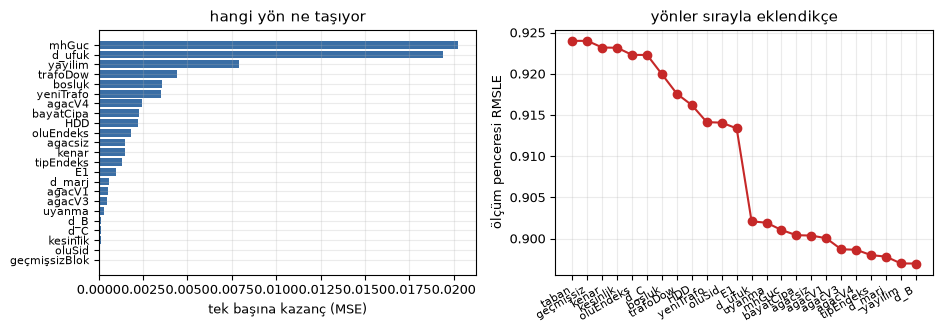

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
sira = SONUC.sort_values("tek_basina_kazanc")
ax[0].barh(range(len(sira)), sira.tek_basina_kazanc, color="#3a6ea5")
ax[0].set_yticks(range(len(sira))); ax[0].set_yticklabels(sira.index, fontsize=8)
ax[0].set_xlabel("tek başına kazanç (MSE)")
ax[0].set_title("hangi yön ne taşıyor")

adim = [TABAN_MSE]
for i in range(1, len(adlar) + 1):
    _, _, _, k_i = ortak_cozum(Dm[:, :i], artik)
    adim.append(TABAN_MSE - k_i)
ax[1].plot(range(len(adim)), np.sqrt(adim), marker="o", color="#c62828")
ax[1].set_xticks(range(len(adim)))
ax[1].set_xticklabels(["taban"] + [a[:9] for a in adlar], rotation=30,
                      ha="right", fontsize=8)
ax[1].set_ylabel("ölçüm penceresi RMSLE")
ax[1].set_title("yönler sırayla eklendikçe")
plt.tight_layout(); plt.show()

Kalibrasyon, artığın tahminin büyüklüğüne göre ortalamasıdır. Düzgün kalibre edilmiş bir tahminde bu eğri sıfır çizgisinde yatay durur.

In [74]:
# Kalibrasyon: artığın, tahminin büyüklüğüne göre ortalaması. 
# Düzgün kalibre bir tahminde bu eğri sıfır çizgisinde yatay olmalı.
duzeltilmis = D.taban.to_numpy() + Dm @ c
kova = pd.qcut(D.taban.to_numpy(), 20, duplicates="drop")
kal = pd.DataFrame({"kova": kova, "once": artik,
                    "sonra": D.L.to_numpy() - duzeltilmis}).groupby("kova", observed=True).mean()
orta = [iv.mid for iv in kal.index]
print("ortalama mutlak sapma: önce %.4f, sonra %.4f"
      % (kal.once.abs().mean(), kal.sonra.abs().mean()))

ortalama mutlak sapma: önce 0.1171, sonra 0.0536


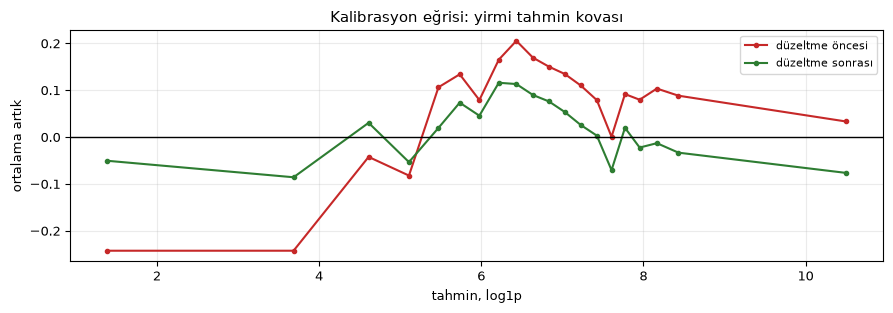

In [75]:
fig, ax = plt.subplots(figsize=(9.0, 3.2))
ax.plot(orta, kal.once, marker="o", ms=3, color="#c62828", label="düzeltme öncesi")
ax.plot(orta, kal.sonra, marker="o", ms=3, color="#2e7d32", label="düzeltme sonrası")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("tahmin, log1p"); ax.set_ylabel("ortalama artık")
ax.legend(fontsize=8); ax.set_title("Kalibrasyon eğrisi: yirmi tahmin kovası")
plt.tight_layout(); plt.show()

Kalibrasyon eğrisi düzeltmelerin nereyi düzelttiğini gösteriyor:
tahminin düşük olduğu kovalarda taban formülü sistematik olarak eksik
kalıyordu, düzeltmelerden sonra eğri sıfır çizgisine belirgin biçimde
yaklaşıyor. Kalan sapma uçlarda yoğunlaşıyor; oralarda satır sayısı az
ve düzeltmelerin de söyleyecek bir şeyi kalmıyor.

### 6.3 Ters Leakage'ın Bedeli

Bölüm 5.4 leave-one-out kurgusunun eğitim içi uyumu şişirdiğini ve
geçmişsiz trafoya transferini bozduğunu gösterdi. Aşağıdaki hücre aynı
karşılaştırmayı düzeltme yönü düzeyinde tekrarlıyor, yani sorunun
skora ne kadar mal olduğunu ölçüyor.

In [76]:
d_loo = np.where(gecmissiz,
                 D.tanim.map(hedef_loo_tahmin).fillna(0.0).to_numpy() - grup_oncelik, 0.0)

for etiket, d in (("leave-one-out yok", YON["geçmişsizBlok"]), ("leave-one-out var", d_loo)):
    E_d = float((d ** 2).mean())
    katsayi_d = float((d * artik).mean() / E_d)
    print("%-18s E[d^2] %.4f  katsayı %+.4f  tek başına kazanç %.5f"
          % (etiket, E_d, katsayi_d, katsayi_d ** 2 * E_d))
print("")
print("iki yönün korelasyonu %.4f"
      % np.corrcoef(d_loo[gecmissiz], YON["geçmişsizBlok"][gecmissiz])[0, 1])

leave-one-out yok  E[d^2] 0.0602  katsayı +0.0068  tek başına kazanç 0.00000
leave-one-out var  E[d^2] 0.1083  katsayı +0.0857  tek başına kazanç 0.00079

iki yönün korelasyonu 0.1276


Leave-one-out kurgusunun ürettiği yön hem daha dar yayılıyor hem daha
az kazandırıyor. Eğitim içi uyumu neredeyse mükemmeldi ve o uyumun
tamamı kendi hedefini geri kurmaktan geliyordu; ölçüm penceresine
taşınan bir şey yok.

Buradan çıkan kural genel: **bir kodlamanın sızdırıp sızdırmadığına
eğitim içi uyuma bakarak karar verilemez.** Karar, kodlamanın hiç
görülmemiş bir birime uygulandığında ne yaptığına bakılarak verilir.
Bölüm 7.2 aynı testi daha ayrıntılı kuruyor.

### 6.4 Cross-Validation ile Katsayıların Çözülmesi

Bölüm 6.2 katsayıları tek bir ölçüm penceresinden çözdü. Nihai tahmin
edicide kullandıklarım bunlar değil: **üç zaman katından çözülmüş
çapraz doğrulama katsayıları**.

Kat şeması test uzunluğunda üç ardışık pencere, genişleyen eğitim:

| Kat | Eğitim | Doğrulama |
|---|---|---|
| 1 | 2025-01-01 öncesi ve 2025-03-31'e kadar. | 2025-04-01 - 2025-07-31. |
| 2 | 2025-07-31'e kadar | 2025-08-01 - 2025-11-30. |
| 3 | 2025-11-30'a kadar | 2025-12-01 - 2026-03-31. |

Her kat için zinciri baştan kuruyorum: endeksi yeniden kestiriyor,
seviyeyi yeniden hesaplıyor, kesitsel modeli yeniden eğitiyor, yönleri
yeniden kuruyor ve katsayıları o katın kendi artığından çözüyorum.
Endeks önbelleği kat kimliğine bağlı; bir kat bitince boşalıyor, yani
katlar arasında hiçbir şey paylaşılmıyor.

Fold 1'in endeksi dışarıdan fitleniyor. Fold 1'in eğitim penceresi
Ocak-Mart 2025 ve o pencerede soğutma derece günü hep sıfır, yani
soğutma katsayısı tanımsız kalıyor. Endeksi bu yüzden eğitim verisinin
Nisan-Temmuz 2025 dışındaki kısmından fitliyorum. Fold 1'in doğrulama
günleri fit çerçevesine hiç girmiyor, dolayısıyla hedef sızıntısı yok.
Kalan iyimserlik şu ve açıkça yazıyorum: global hava-tüketim ilişkisi
ileriden biliniyor. Bu, yönlerin sıralaması için adil, mutlak seviye
için iyimser.

Sonra üç şey yapıyorum:

* θ ızgarası. Ölçekli cezanın gücü de elle seçilmiyor. Izgara
  taranıyor ve her θ için kat dışı doğrulama hatası ölçülüyor;
  seçilen değer o hatanın en düşük olduğu nokta.
* İşaret kapısı. Bir yön ancak üç katta da aynı işareti verirse
  nihai tahmin ediciye giriyor. İşaret değiştiren yönün katsayısı tam
  sıfırlanıyor; o yön bir mekanizmaya değil tek bir pencerenin şekline
  karşılık geliyor demektir.
* Kat dışı sınav. Bir kat tutuluyor, katsayı diğer iki katın
  satırları **birleştirilerek** tek seferde çözülüyor ve tutulan katta
  ölçülüyor. Katsayıların çözüldüğü veriden bağımsız tek sınav bu.
  Ayrı çözümleri ortalamak yerine satırları birleştirmek gerekiyor;
  sebebi ve ilk kurgumun neden ters sonuç verdiği aşağıda.

Önbellek anahtarı KAT KİMLİĞİ. Bir kat bitince önbellek boşalıyor, çünkü
katlar arasında paylaşılan bir endeks sızıntı olurdu: erken katın endeksi
geç katın verisini görmüş olurdu.

In [77]:
# Fold şeması: test uzunluğunda üç ardışık pencere, genişleyen eğitim.
FOLD = [("kat 1", "2025-04-01", "2025-07-31"),
        ("kat 2", "2025-08-01", "2025-11-30"),
        ("kat 3", "2025-12-01", "2026-03-31")]
THETA_IZGARA = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0]

_ENDEKS_ONBELLEK = {}


# Katın endeksini kurar ve önbelleğe alır.
def kat_endeksi(kat_ad, egitim, dogrulama, fit_veri=None):
    if _ENDEKS_ONBELLEK.get("kat") != kat_ad:
        _ENDEKS_ONBELLEK.clear()
        kaynak = egitim if fit_veri is None else fit_veri
        e, h, _ = endeks_ekle(egitim, dogrulama, fit_veri=kaynak)
        _ENDEKS_ONBELLEK["kat"] = kat_ad
        _ENDEKS_ONBELLEK["eh"] = (e, h)
    assert _ENDEKS_ONBELLEK["kat"] == kat_ad, "endeks önbelleği başka kata ait"
    e, h = _ENDEKS_ONBELLEK["eh"]
    return e.copy(), h.copy()

Bir katın tamamını koşturan fonksiyon aşağıda. Zinciri baştan
kuruyor: endeks, seviye, kesitsel model ve yönler. Kat 1'in endeksi için
ayrı bir çerçeve verilmesinin sebebi fonksiyonun içinde yazılı.

Endeksi eğitim verisinin Nisan-Temmuz 2025 DIŞINDAKİ kısmından fitleniyor;
katın doğrulama günleri fit çerçevesine girmiyor.

In [78]:
# Bir katın tamamı: endeks, seviye, kesitsel model, yönler ve çözüm.
def kat_kos(kat_ad, bas, son, tohum=7):
    bas, son = pd.Timestamp(bas), pd.Timestamp(son)
    egitim = train[train.tarih < bas].copy()
    dogrulama = train[(train.tarih >= bas) & (train.tarih <= son)].copy()

    # Kat 1'in eğitim penceresi Ocak-Mart, orada CDD hep sıfır.
    fit_veri = None
    if kat_ad == "kat 1":
        fit_veri = train[~((train.tarih >= bas) & (train.tarih <= son))].copy()

    e, d = kat_endeksi(kat_ad, egitim, dogrulama, fit_veri)
    e, d, olu_kat = seviye_kur(e, d)
    d["ufuk"] = (d.tarih - egitim.tarih.max()).dt.days
    d["W"] = d.kanit.to_numpy()
    r = d.L.to_numpy() - d.seviye.to_numpy()

    # Geçmişsiz blok için kesitsel model, bölüm 5'ün aynısı.
    tablo = kesitsel_tablo(e, pd.Index(sorted(set(e.tanim) | set(d.tanim))),
                           loo=False, ek=d)
    egt, hdf = tablo[tablo.hedef.notna()], tablo[tablo.hedef.isna()]
    t_lgb = pd.Series(lgb.train(dict(LGB_PARAM, seed=tohum),
                                lgb.Dataset(egt[OZELLIK], egt.hedef),
                                num_boost_round=300).predict(hdf[OZELLIK]),
                      index=hdf.index)
    cat = CatBoostRegressor(iterations=400, depth=5, learning_rate=0.05,
                            l2_leaf_reg=6, random_seed=tohum, verbose=0)
    cat.fit(egt[OZELLIK].fillna(-999), egt.hedef)
    t_cat = pd.Series(cat.predict(hdf[OZELLIK].fillna(-999)), index=hdf.index)

    Y = yonleri_kur(e, d, d.seviye.to_numpy(), d.grup_ilce_guc.to_numpy(),
                    t_lgb, t_cat, d.ufuk.to_numpy(), olu_maske=olu_kat)
    M = np.column_stack([Y[a] for a in adlar])
    print("  %s: eğitim %s satır, doğrulama %s satır"
          % (kat_ad, format(len(e), ","), format(len(d), ",")), flush=True)
    del e, tablo, egt, hdf
    gc.collect()
    return {"D": M, "r": r, "taban_mse": float((r ** 2).mean())}

Üç katı da koşturup θ ızgarasını taramaya geçiyorum. θ,
düzeltme yönlerinin katsayılarını sıfıra doğru çeken ceza katsayısı.
Değerini kat dışı doğrulama hatası seçiyor: her θ için bir kat
tutuluyor, katsayı diğer ikisinden çözülüyor ve tutulan katta ölçülüyor.
Bu koşum notebook'un en uzun süren adımı, çünkü her kat için endeks,
seviye, kesitsel model ve yönlerin tamamı baştan kuruluyor.

Üç ayrı çözümü ortalamak yerine tek çözüm yapmak gerekiyor: katların
pencereleri farklı uzunlukta ve yönlerin ölçeği katlar arasında değişiyor.

Bir yön ancak üç katın üçünde de aynı işareti aldıysa çözümde kalıyor.
Kapı sabit bir referans cezayla okunuyor; cezanın kendisi bir sonraki
hücrede, yalnız kalan yönler üzerinde seçiliyor. Sıra böyle olmak zorunda:
elenen yönler ızgarada dursaydı ceza onlara göre büyür ve kalan yönlerin
katsayılarını ezerdi.

In [79]:
print("KATLAR KURULUYOR", flush=True)
KAT = {ad: kat_kos(ad, b, s) for ad, b, s in FOLD}


# Bir kat tutulup diğer katların satırları BİRLEŞTİRİLEREK çözülüyor.
def kat_disi_katsayi(disarida, theta, sutun):
    Dm = np.vstack([KAT[j]["D"][:, sutun] for j in KAT if j != disarida])
    rr = np.concatenate([KAT[j]["r"] for j in KAT if j != disarida])
    return ortak_cozum(Dm, rr, theta)[0]


# Önce işaret kapısı.
THETA_KAPI = 10.0
tum_sutun = list(range(len(adlar)))
KATSAYI_KAT = pd.DataFrame(
    {k: pd.Series(ortak_cozum(v["D"], v["r"], THETA_KAPI)[0], index=adlar)
     for k, v in KAT.items()})
isaret = np.sign(KATSAYI_KAT)
gecen = list(isaret.index[(isaret.nunique(axis=1) == 1) & (isaret.iloc[:, 0] != 0)])
SUTUN = [adlar.index(a) for a in gecen]
print("")
print("işaret kapısından geçen %d yön: %s" % (len(gecen), ", ".join(gecen)))
print("kapıda elenen %d yön: %s"
      % (len(adlar) - len(gecen), ", ".join(a for a in adlar if a not in gecen)))

KATLAR KURULUYOR


  kat 1: eğitim 187,500 satır, doğrulama 274,929 satır


  kat 2: eğitim 462,429 satır, doğrulama 319,732 satır


  kat 3: eğitim 782,161 satır, doğrulama 444,076 satır



işaret kapısından geçen 9 yön: geçmişsizBlok, kenar, d_C, bosluk, trafoDow, HDD, oluSid, bayatCipa, agacV3
kapıda elenen 14 yön: kesinlik, oluEndeks, yeniTrafo, E1, d_ufuk, uyanma, mhGuc, agacsiz, agacV1, agacV4, tipEndeks, d_marj, yayilim, d_B


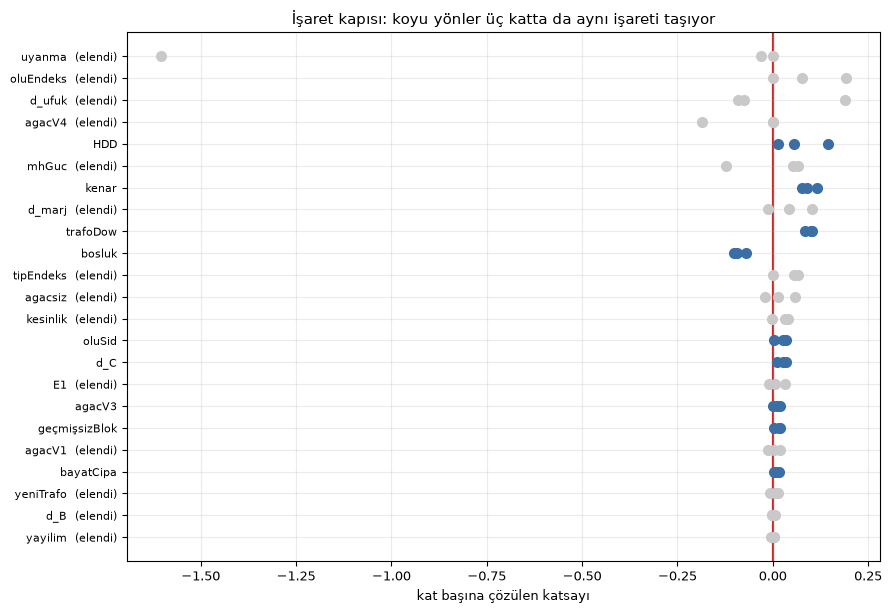

In [80]:
sira = KATSAYI_KAT.reindex(
    KATSAYI_KAT.abs().max(axis=1).sort_values().index)

fig, ax = plt.subplots(figsize=(9.0, 6.2))
for j, ad in enumerate(sira.index):
    gec = ad in gecen
    ax.plot(sira.loc[ad].to_numpy(), [j] * sira.shape[1], "o", ms=7,
            color="#3a6ea5" if gec else "#c9c9c9", zorder=3 if gec else 2)
ax.axvline(0, color="#c62828", lw=1.6, zorder=1)
ax.set_yticks(range(len(sira)))
ax.set_yticklabels(["%s%s" % (a, "" if a in gecen else "  (elendi)")
                    for a in sira.index], fontsize=8)
ax.set_xlabel("kat başına çözülen katsayı")
ax.set_title("İşaret kapısı: koyu yönler üç katta da aynı işareti taşıyor")
plt.tight_layout(); plt.show()

Her satır bir yön, her nokta o yönün bir zaman katındaki
katsayısı. Kural görsel olarak basit: üç noktası da kırmızı çizginin
aynı tarafında kalan yönler geçiyor, çizgiyi aşan yönler eleniyor.
Elenen yönlerin çoğunda noktalar sıfırın iki yanına dağılmış durumda,
yani o yönün işareti bile pencereden pencereye değişiyor; böyle bir
yön mekanizma değil, tek bir dönemin şekli demektir.

Kapı kapandığına göre ceza katsayısı seçilebilir. Izgara yalnız
kalan yönler üzerinde taranıyor ve her θ için bir kat tutulup katsayı
diğer ikisinden çözülüyor.

In [81]:
# θ ızgarası, YALNIZ kapıdan geçen yönler üzerinde.
print("")
print("θ IZGARASI, kat dışı doğrulama hatası")
n_top = sum(len(x["r"]) for x in KAT.values())
izgara = []
for th in THETA_IZGARA:
    toplam, taban = 0.0, 0.0
    for k, v in KAT.items():
        c_dis = kat_disi_katsayi(k, th, SUTUN)
        toplam += float(((v["r"] - v["D"][:, SUTUN] @ c_dis) ** 2).sum())
        taban += float((v["r"] ** 2).sum())
    izgara.append({"θ": th, "kat disi MSE": toplam / n_top,
                   "taban MSE": taban / n_top})
IZGARA = pd.DataFrame(izgara)
IZGARA["kazanc"] = IZGARA["taban MSE"] - IZGARA["kat disi MSE"]
print(IZGARA.round(5).to_string(index=False))
THETA = float(IZGARA["θ"][IZGARA["kat disi MSE"].idxmin()])
print("Seçilen θ: %.3f" % THETA)


θ IZGARASI, kat dışı doğrulama hatası


     θ  kat disi MSE  taban MSE   kazanc
  0.01       0.85484    0.84823 -0.00661
  0.03       0.85355    0.84823 -0.00532
  0.10       0.84981    0.84823 -0.00158
  0.30       0.84334    0.84823  0.00488
  1.00       0.83790    0.84823  0.01033
  3.00       0.84001    0.84823  0.00822
 10.00       0.84456    0.84823  0.00366
 30.00       0.84684    0.84823  0.00139
100.00       0.84779    0.84823  0.00044
300.00       0.84808    0.84823  0.00015
Seçilen θ: 1.000


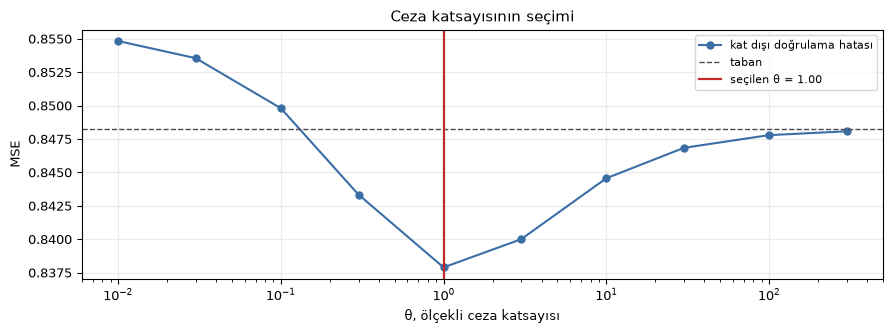

In [82]:
fig, ax = plt.subplots(figsize=(9.0, 3.4))
ax.semilogx(IZGARA["θ"], IZGARA["kat disi MSE"], marker="o", ms=5,
            color="#3a6ea5", label="kat dışı doğrulama hatası")
ax.axhline(float(IZGARA["taban MSE"].iloc[0]), color="#4a4a4a", ls="--", lw=1,
           label="taban")
ax.axvline(THETA, color="#c62828", lw=1.6, label="seçilen θ = %.2f" % THETA)
ax.set_xlabel("θ, ölçekli ceza katsayısı"); ax.set_ylabel("MSE")
ax.legend(fontsize=8)
ax.set_title("Ceza katsayısının seçimi")
plt.tight_layout(); plt.show()

Eğri hem cezanın gerekliliğini hem seçimin sağlamlığını
gösteriyor. Hafif cezada kat dışı hata tabanın üstünde, yani cezasız
katsayılar aşırı uyuyor. Ceza büyüdükçe hata düşüyor, bir noktada en
aza iniyor, sonra tekrar yükseliyor çünkü katsayılar gereğinden fazla
sıfıra çekiliyor. Seçilen değer bu çukurun dibinde ve ızgaranın
ucunda değil; uçta seçilseydi ızgarayı genişletmek gerekirdi.

Seçilen ceza ile nihai katsayılar üç katın satırları
birleştirilerek tek seferde çözülüyor.

In [83]:
# Nihai katsayılar üç katın satırları birleştirilerek, seçilen θ ile ve
# yalnız kapıdan geçen yönler üzerinde çözülüyor.
Dm_tum = np.vstack([v["D"][:, SUTUN] for v in KAT.values()])
r_tum = np.concatenate([v["r"] for v in KAT.values()])
c_gecen = pd.Series(ortak_cozum(Dm_tum, r_tum, THETA)[0], index=gecen)
KATSAYI_CV = pd.Series(0.0, index=adlar)
KATSAYI_CV.loc[gecen] = c_gecen
del Dm_tum, r_tum
gc.collect()

KARARLILIK = KATSAYI_KAT.copy()
KARARLILIK["ortalama"] = KATSAYI_KAT.mean(axis=1)
KARARLILIK["sd"] = KATSAYI_KAT.std(axis=1)
KARARLILIK["kapı"] = np.where(KATSAYI_KAT.index.isin(gecen), "geçti", "elendi")
KARARLILIK["nihai"] = KATSAYI_CV
print("")
print("KAT BAŞINA ÇÖZÜLEN KATSAYILAR VE NİHAİ ÇÖZÜM")
print(KARARLILIK.round(4).to_string())


KAT BAŞINA ÇÖZÜLEN KATSAYILAR VE NİHAİ ÇÖZÜM
                kat 1   kat 2   kat 3  ortalama      sd    kapı   nihai
geçmişsizBlok  0.0179  0.0155  0.0027    0.0121  0.0082   geçti  0.0416
kenar          0.0760  0.0892  0.1148    0.0933  0.0197   geçti  0.6147
kesinlik       0.0399  0.0314 -0.0027    0.0229  0.0226  elendi  0.0000
oluEndeks     -0.0006  0.0760  0.1916    0.0890  0.0968  elendi  0.0000
d_C            0.0261  0.0338  0.0120    0.0240  0.0111   geçti  0.1348
bosluk        -0.1023 -0.0928 -0.0690   -0.0880  0.0171   geçti -0.4696
trafoDow       0.0845  0.1027  0.0995    0.0955  0.0097   geçti  0.5175
HDD            0.0553  0.1447  0.0134    0.0712  0.0671   geçti  0.1036
yeniTrafo      0.0067 -0.0071  0.0140    0.0045  0.0107  elendi  0.0000
oluSid         0.0258  0.0348  0.0043    0.0216  0.0157   geçti  0.1168
E1             0.0334  0.0064 -0.0099    0.0099  0.0219  elendi  0.0000
d_ufuk        -0.0743 -0.0916  0.1895    0.0079  0.1575  elendi  0.0000
uyanma         0.0

Kapıdan geçen yönlerin katkısı eşit değil. Aşağıdaki grafik her
yönün $c^2 \cdot E[d^2]$ değerini, yani MSE ölçeğinde ne kadar
getirdiğini veriyor; çubuğun ucundaki sayı o yönün katsayısı.

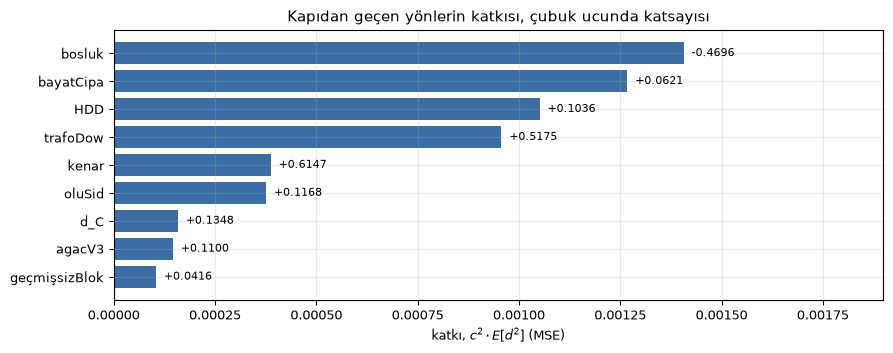

In [84]:
katki = pd.Series(
    {a: float(KATSAYI_CV[a] ** 2 * (Dm[:, adlar.index(a)] ** 2).mean())
     for a in gecen}).sort_values()

fig, ax = plt.subplots(figsize=(9.0, 3.6))
ax.barh(range(len(katki)), katki.to_numpy(), color="#3a6ea5")
for j, a in enumerate(katki.index):
    ax.text(katki.iloc[j], j, "  %+.4f" % KATSAYI_CV[a], va="center", fontsize=8)
ax.set_yticks(range(len(katki))); ax.set_yticklabels(katki.index, fontsize=9)
ax.set_xlabel("katkı, $c^2 \\cdot E[d^2]$ (MSE)")
ax.set_xlim(0, katki.max() * 1.35)
ax.set_title("Kapıdan geçen yönlerin katkısı, çubuk ucunda katsayısı")
plt.tight_layout(); plt.show()

Katkı birkaç yöne yığılmış durumda. Büyük katsayı her zaman
büyük katkı demek değil: bir yönün getirisi katsayısının karesi ile
enerjisinin çarpımı, yani dar bir satır kümesine dokunan büyük katsayılı
bir yön, geniş bir kümeye dokunan küçük katsayılıdan az getirebiliyor.

Son olarak kazancın gürültü bandının neresinde durduğunu okuyorum.
Kat içi ile kat dışı skorun birlikte basılması bilinçli: aradaki fark
düzeltmelerin ne kadarının ezberden geldiğini gösteriyor.

In [85]:
# Kat başına eğitim ve doğrulama skoru birlikte.
satir = []
for k, v in KAT.items():
    ic = ortak_cozum(v["D"][:, SUTUN], v["r"], THETA)
    disar = kat_disi_katsayi(k, THETA, SUTUN)
    dis_rmsle = np.sqrt(float(((v["r"] - v["D"][:, SUTUN] @ disar) ** 2).mean()))
    satir.append({"kat": k, "taban": np.sqrt(v["taban_mse"]),
                  "eğitim (kat içi)": np.sqrt(v["taban_mse"] - ic[3]),
                  "doğrulama (kat dışı)": dis_rmsle,
                  "kat dışı kazanç": np.sqrt(v["taban_mse"]) - dis_rmsle})
print("")
print("FOLD BAŞINA EĞİTİM VE DOĞRULAMA SKORU, RMSLE")
print(pd.DataFrame(satir).round(4).to_string(index=False))
FOLD_TABLO = pd.DataFrame(satir)
print("")
print("kat dışı kazanç, gürültü bandı %.5f RMSLE ile karşılaştırmalı:" % BAND)
for _, r in FOLD_TABLO.iterrows():
    yargi = "bandın üstünde" if abs(r["kat dışı kazanç"]) > BAND else "banttan ayırt edilemiyor"
    print("  %-6s %+.5f  %s" % (r["kat"], r["kat dışı kazanç"], yargi))
# Katsayının katlar arası yayılımla karşılaştırılması: katsayı yayılımın
# altında kalıyorsa o yönün kat dışı kanıtı zayıf demektir.
KATSAYI_SON = pd.DataFrame({
    "katsayı": KATSAYI_CV,
    "katlar arası sd": KATSAYI_KAT.std(axis=1),
}).loc[[a for a in adlar if KATSAYI_CV[a] != 0]]
KATSAYI_SON["kat dışı kanıt"] = np.where(
    KATSAYI_SON["katsayı"].abs() > KATSAYI_SON["katlar arası sd"],
    "yayılımın üstünde", "yayılımın altında")
print("")
print("NİHAİ KATSAYILAR, üç katın satırları birleştirilerek çözülmüş")
print(KATSAYI_SON.round(4).to_string())
del KAT
gc.collect()
ZIRVE_BELLEK = max(ZIRVE_BELLEK, bellek_gb())


FOLD BAŞINA EĞİTİM VE DOĞRULAMA SKORU, RMSLE
  kat  taban  eğitim (kat içi)  doğrulama (kat dışı)  kat dışı kazanç
kat 1 0.8940            0.8810                0.8863           0.0077
kat 2 0.9395            0.9243                0.9305           0.0090
kat 3 0.9240            0.9181                0.9220           0.0019

kat dışı kazanç, gürültü bandı 0.00003 RMSLE ile karşılaştırmalı:
  kat 1  +0.00770  bandın üstünde
  kat 2  +0.00898  bandın üstünde
  kat 3  +0.00195  bandın üstünde

NİHAİ KATSAYILAR, üç katın satırları birleştirilerek çözülmüş
               katsayı  katlar arası sd     kat dışı kanıt
geçmişsizBlok   0.0416           0.0082  yayılımın üstünde
kenar           0.6147           0.0197  yayılımın üstünde
d_C             0.1348           0.0111  yayılımın üstünde
bosluk         -0.4696           0.0171  yayılımın üstünde
trafoDow        0.5175           0.0097  yayılımın üstünde
HDD             0.1036           0.0671  yayılımın üstünde
oluSid          0.1168       

Ceza gerekli ve işini yapıyor. Hafif cezalı çözümün kat dışı hatası
tabanın çok üstünde kalır ve ceza büyüdükçe kapanır. Kazanç ancak
ızgaranın üst ucunda pozitife döner. Bu, cezasız katsayıların aşırı
uyduğunu ve cezanın tam olarak o fazlalığı kestiğini gösterir.

Düzeltmeler bu tabanın üstünde az şey taşır. Kazanç MSE ölçeğinde
binde birkaç mertebesindedir. İki okuma birbirini geçersiz kılmaz:
birincisi yöntemin kendini düzenlediğini, ikincisi düzeltilecek fazla
bir şey kalmadığını söyler. Taban formülü zaten ölü muafiyetini, dört
kademeli grup önceliğini ve mevsim genliğini içerir; basitleştirilmiş
bir tabanla çalışsaydım aynı yönler çok daha büyük görünürdü.

Katları ortalamak yerine birleştirmek gerekir. İlk kurgumda kat dışı
katsayıyı, diğer iki katın ayrı çözümlerini ortalayarak buluyordum ve
kat dışı kazanç her θ değerinde negatif çıkıyordu. Diğer katların
satırlarını birleştirip tek çözüm yapınca kazanç pozitife döndü.
Sebebi şudur: katların pencereleri farklı uzunluktadır (kat 1'de 187
bin satır, kat 3'te 782 bin) ve yönlerin ölçeği katlar arasında
değişir; ayrı çözümlerin ortalaması bu yüzden savrulur.

Üç katın üçünde de kat dışı kazanç pozitiftir ve üçü de gürültü
bandının üstündedir. Kazanç kat 3'te en büyüktür; o kat en uzun
geçmişe sahip olandır.

Katsayıların hepsi aynı güvenle okunmaz. Kapıdan geçen yönlerin
çoğunda katsayı, katlar arası yayılımın belirgin üstündedir. Aşağıdaki
tabloda hangilerinin altında kaldığı ayrıca basılır; çözümde
kalmalarının sebebi güçlü olmaları değildir, ölçekli ceza onları zaten
sıfıra yakın bir yerde tutar.

İşaret kapısında elenen yönler nihai tahmin ediciye hiç girmez,
katsayıları tam sıfırdır. Bölüm 8'de kapanan yolların bir kısmı tam bu
kapıdan düşmüştür.

## 7. Leakage ve Dış Veri Denetimi

Model kuruldu ve katsayıları çözüldü. Tahmini üretmeden önce iki
denetimden geçiriyorum: kullandığım dış verinin kurallara uygunluğu ve
özelliklerin hedefi taşıyıp taşımadığı.

### 7.1 Dış Veri Denetimi

Kullandığım iki kaynak notebook'un başında tablo hâlinde duruyor ve
ikisi de günlük endekste çalışıyor. Burada denetlediğim şey, listede
olmayan bir kaynağın tahmine sızıp sızmadığıdır.

EPİAŞ verisini bilerek dışarıda bıraktım. Gerçekleşen sistem
tüketimi, üretim ve piyasa takas fiyatı serileri tahmin dönemine ait
gerçekleşmeleri içeriyor. Bir dağıtım şirketi Nisan 2026 tahminini
yaparken Temmuz 2026'nın gerçekleşen tüketimini bilemez; yani bu bilgi
problemin kendisiyle tutarsız. Kararın bedelini hesapladım ve bilerek
ödedim, yaklaşık 0,00017 RMSLE.

Bu paragraftaki iki sayı, bu notebook'un içinde yeniden
üretilemeyen tek şey ve sebebini açıkça yazıyorum: ölçüm, tam da
kullanmamaya karar verdiğim EPİAŞ serilerini indirmeyi gerektiriyor.
Geliştirme sırasında yaptım ve sonucu şu. Düzeltme yönlerinin bu dört
seriye izdüşümü 1e-15 mertebesinde, yani sayısal sıfır. Yazılan
gönderim dosyasının farkında ise `expm1` ve `log1p` gidiş dönüşünün
yuvarlanmasından 1e-5 mertebesinde bir artık kalıyor. Bu kullanım
değil yuvarlama; ayrımı yazıyorum çünkü otomatik bir denetim izdüşümü
kullanım sanabilir.

### 7.2 Leakage İmzası

Bir modelin özelliklerinin hedefi taşıyıp taşımadığı, eğitim içi uyuma
bakarak anlaşılamaz. Anlaşılabilecek yer şu: **model kendi eğitim
kümesinde ve hiç görmediği bir kümede aynı biçimde mi davranıyor.**

İki büyüklük ölçülüyor. Birincisi tahminlerin yayılımının hedefin
yayılımına oranı; sızıntısız bir model düzenlileştirme yüzünden bunu
birin altında tutar ve iki popülasyonda benzer değer verir. İkincisi
hiç görülmemiş birimlerdeki açıklama gücü. Sızıntı varsa birinci
büyüklük kendi kümesinde bire yaklaşır ve dışarıda çöker.

Aşağıdaki hücre bölüm 5'ün iki kurgusunu bu iki ölçüte vuruyor.

In [86]:
# Aynı model iki kurguyla: özellikler hedefi taşımadan, ve leave-one-out yamasıyla. Fark iki popülasyonda ölçülüyor.

zincir = []
for etiket, tablo_loo in (("özellikler hedefi içeriyor", False),
                          ("leave-one-out yaması", True)):
    Mz = kesitsel_tablo(E, tum_trafolar, loo=tablo_loo)
    egt, hdf = Mz[Mz.hedef.notna()], Mz[Mz.hedef.isna()]
    m = lgb.train(dict(LGB_PARAM, seed=7),
                  lgb.Dataset(egt[OZELLIK], egt.hedef), num_boost_round=300)
    ic = pd.Series(m.predict(egt[OZELLIK]), index=egt.index)
    dis = pd.Series(m.predict(hdf[OZELLIK]), index=hdf.index)
    hed = gozlenen_seviye.reindex(dis.index).dropna()
    dis = dis.reindex(hed.index)
    zincir.append({
        "kurgu": etiket,
        "kendi üzerinde sd oranı": round(float(ic.std() / egt.hedef.std()), 3),
        "görülmemiş trafoda sd oranı": round(float(dis.std() / hed.std()), 3),
        "görülmemiş trafoda R2": round(float(1 - np.mean((hed - dis) ** 2) / np.var(hed)), 4),
    })
ZINCIR = pd.DataFrame(zincir).set_index("kurgu")
print(ZINCIR.to_string())

                            kendi üzerinde sd oranı  görülmemiş trafoda sd oranı  görülmemiş trafoda R2
kurgu                                                                                                  
özellikler hedefi içeriyor                    0.559                        0.538                 0.0731
leave-one-out yaması                          0.997                        0.172                 0.0206


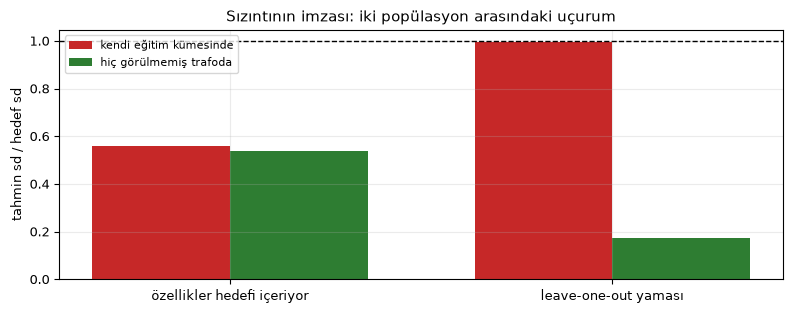

In [87]:
fig, ax = plt.subplots(figsize=(8.0, 3.2))
x = np.arange(len(ZINCIR)); g = 0.36
ax.bar(x - g / 2, ZINCIR["kendi üzerinde sd oranı"], g, color="#c62828",
       label="kendi eğitim kümesinde")
ax.bar(x + g / 2, ZINCIR["görülmemiş trafoda sd oranı"], g, color="#2e7d32",
       label="hiç görülmemiş trafoda")
ax.axhline(1.0, color="k", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(ZINCIR.index, fontsize=9)
ax.set_ylabel("tahmin sd / hedef sd"); ax.legend(fontsize=8)
ax.set_title("Sızıntının imzası: iki popülasyon arasındaki uçurum")
plt.tight_layout(); plt.show()

Sızıntısız kurgu iki popülasyonda neredeyse aynı davranıyor. Sızıntılı
kurgu ise kendi eğitim kümesinde hedefin yayılımını neredeyse birebir
üretiyor, oranı bire dayanıyor, sonra hiç görülmemiş trafoda altıda
birine düşüyor ve açıklama gücü de yarıya iniyor. Aradaki uçurumun
kendisi sızıntı.

Aynı testin daha büyük ölçekli bir örneği çalışmanın erken bir
aşamasında da koşuldu. Satır düzeyinde kurulan bir modelde yayılım
oranı biri aşıyordu, yani model dışdeğerleme yapıyordu; kurgu hedefin
görülmediği bir kesite taşındığında oran bire indi. O düzeltmenin
geriye okunan katsayısı ise iki kurguda da aynı çıktı, yani bulaşma
gerçekti ama skora bir katkısı yoktu. Buradaki hücre o sonucun
notebook içinde yeniden üretilebilen küçük hâli.

### 7.3 Doğrulama Denetimleri

Aşağıdaki iki hata geliştirme sırasında tespit edildi ve düzeltildi;
nihai çözümde ikisi de yok. Buraya yazılmalarının sebebi ikisinin de
ancak belirli bir denetimle yakalanabilir olması ve o denetimin
yöntemin kalıcı parçası hâline gelmesi.

Yanlış kesit seçimi. Bulaşma ilk kez trafonun gün sayısı otuzun üstünde
olan kesitte arandı. Yanlış kesitti: kanıt ağırlığı doyuma çok daha
erken ulaşıyor, yani asıl ayrım orada. Doğru kesitle bakıldığında
bulaşmanın büyüklüğü çok daha küçük çıktı.

Dışdeğerleme kuralı bazı özellikler için hiç koşulmamıştı. Bu
çalışmanın kendi kurallarından biri şunu söylüyor: ağaç modelleri
dışdeğerleme yapamaz, o yüzden zamanla artan özellikler atılır. Otomatik bir tarama
iki özelliğin bu kuraldan kaçtığını buldu: biri eğitimde asla sıfır
olmuyor ama testte satırların beşte birinde sıfır, diğeri geleceğe
bakan bir tatil sayacı. Kural yazılıydı ama otomatik bir tarama devreye girene kadar koşulmamıştı; o tarama da yöntemin kalıcı parçası oldu.

Bulasma ilk kez gun sayisi otuzun ustundeki kesitte arandi; asagidaki
dagilim o kesitin neden yanlis oldugunu gosteriyor.

In [88]:
# Birinci denetim: kanit agirliginin doyum noktasi.
DOYUM = pd.DataFrame({"Gün sayısı": E.groupby("tanim").tarih.nunique(),
                      "Kanıt ağırlığı W": W}).dropna()
kova_gun = pd.cut(DOYUM["Gün sayısı"], [0, 10, 20, 30, 60, 120, 240, 10 ** 6])
print("Kanıt ağırlığı, trafonun gün sayısına göre:")
print(DOYUM.groupby(kova_gun, observed=True)["Kanıt ağırlığı W"]
      .agg(["size", "median"]).round(2).to_string())

# Ikinci denetim: disdegerleme taramasi. Egitim trafolarinda gorulen
# araligin disina cikan bir ozellik varsa agac orada ezberden konusur.
tarama = []
for oz in OZELLIK:
    e_v = egitim_trafo[oz].dropna()
    h_v = hedef_trafo[oz].dropna()
    if not len(h_v):
        continue
    disari = float(((h_v < e_v.min()) | (h_v > e_v.max())).mean())
    tarama.append({"Özellik": oz,
                   "Eğitim aralığı": "%.2f - %.2f" % (e_v.min(), e_v.max()),
                   "Aralık dışı pay": round(100 * disari, 2),
                   "Eğitimde sıfır pay": round(100 * float((e_v == 0).mean()), 2),
                   "Hedefte sıfır pay": round(100 * float((h_v == 0).mean()), 2)})
TARAMA = pd.DataFrame(tarama).set_index("Özellik")
print("")
print("Dışdeğerleme taraması, cross-sectional modelin özellikleri:")
print(TARAMA.to_string())
print("")
print("Aralık dışına çıkan özellik sayısı: %d"
      % int((TARAMA["Aralık dışı pay"] > 0).sum()))

Kanıt ağırlığı, trafonun gün sayısına göre:
                size  median
Gün sayısı                  
(0, 10]          432    4.99
(10, 20]         235    8.53
(20, 30]         275    0.00
(30, 60]         275   12.87
(60, 120]        444   13.42
(120, 240]       507   13.49
(240, 1000000]  1953   13.49

Dışdeğerleme taraması, cross-sectional modelin özellikleri:
            Eğitim aralığı  Aralık dışı pay  Eğitimde sıfır pay  Hedefte sıfır pay
Özellik                                                                           
lguc          3.69 - 10.49              0.0                 0.0                0.0
il_ort         5.58 - 6.45              0.0                 0.0                0.0
bolge_ort      3.90 - 7.13              0.0                 0.0                0.0
ilce_ort       3.90 - 8.09              0.0                 0.0                0.0
ilce_n      11.00 - 269.00              0.0                 0.0                0.0
bolge_n    11.00 - 1589.00              0.0          

Kanıt ağırlığı bir üst sınıra doyar ve doyum değeri 13,5 civarındadır.
Tablo iki şey gösterir. Birincisi, doyum otuz günde değil altmış günde
tamamlanır; altmış günden sonra ek geçmiş hiçbir şey eklemez. İkincisi,
gün sayısı ile kanıt ağırlığı aynı şey değildir. Yirmi ile otuz gün
arasındaki trafolarda kanıt ağırlığının ortancası sıfırdır, çünkü o
trafolar verinin başında birkaç hafta ölçüm vermiş ve sonra susmuştur;
yaşlanma ağırlığı onların katkısını sıfıra indirir.

Bulaşmayı gün sayısı otuzun üstündeki kesitte aramak bu yüzden
yanlıştı. O kesit, kanıt ağırlığı sıfır olan bir trafo ile 13,5 olan
bir trafoyu aynı kovaya koyuyordu. Doğru ayrım gün sayısında değil,
kanıt ağırlığının doyduğu yerdedir.

Dışdeğerleme taraması ikinci hatanın kalıcı karşılığıdır. Tarama, her
özelliğin uygulama kümesindeki değerlerinin eğitim aralığının içinde
kalıp kalmadığını ölçer. Aralık dışına çıkan bir özellik varsa ağaç
orada en uçtaki yaprağa sıkışır ve tahmini sabitlenir.

## 8. Denenip Kapatılan Yollar

Denediğim ama işe yaramayan fikirleri de yazıyorum. Bir fikrin neden
bırakıldığı yazılı olmazsa o fikir kapanmış sayılmaz ve er geç yeniden
denenir.

Bu tablo bir çalışma kaydıdır. Yanındaki sayılar yarışma sürecinde ayrı
betiklerle ölçülmüştür ve bu notebook'un içinde yeniden üretilmez. Aksi
hâlde kapatılmış her yolun kodunu da taşımak gerekirdi ve koşum süresi
birkaç katına çıkardı. Notebook'un kendi ürettiği sayılar bölüm 9.3'te
toplu hâlde bulunur.

| Denenen | Kapanış Gerekçesi |
|---|---|
| Geçen yılın aynı mevsimini trafo bazında taşımak. | Trafonun kendi yakın üç ayının üzerine kattığı açıklama gücü 0,0001 çıktı. Yıldan yıla taşınabilen en iyi durum bile toplam hatanın binde üçü kadar kaldı. |
| Tahminin büyüklüğüne göre kalibrasyon düzeltmesi uygulamak. | Tahminleri beş dilime bölüp her dilime ayrı düzeltme verdim. Üç bağımsız kurgu denedim ve üçünün de katsayısı sıfıra yakın çıktı. |
| Trafo başına eğilim terimi eklemek. | İlk kurgu kazandırdı ve bileşik katsayısı 1,12 çıktı. Aynı fikrin pencere uzunluğu ile kırpma seviyesi değiştirilmiş varyantlarının dik artığı 0,14'te kaldı, yani ilk kurgunun sekizde biri. Ailenin taşınabilir kısmı ilk kurguda tükenmişti. |
| Eğilimi çok dik olan trafolara aynı düzeltmeyi uygulamak. | Kırpma gevşetildikçe düzeltmenin büyüklüğü üç katına çıktı ama yayıldığı trafo sayısı üçte bire indi. Birkaç trafoya yığılan düzeltmeyi kullanmadım. |
| Bütün tahminleri sabit bir miktar kaydırmak. | İlk okuma büyük bir kazanç vaat ediyordu. Geriye dönük sınamanın kendi sapmasıyla düzeltince kazanç kırk kat küçüldü ve eşiğin altına düştü. |
| Cross-sectional bloğa komşu trafo kodu, ilçe sapması ve toplu alım partisi özellikleri eklemek. | İki sınama tarihinde `log(güç)` doğrusunun üstüne kattıkları açıklama gücü 0,004 ve 0,000 çıktı. Üstelik işaretleri tarihler arasında döndü. |
| Trafonun veriye girişinden sonraki yükselme eğilimini modellemek. | Trafonun yaşı ile tahmin ufku aynı şeyi ölçtüğü için ayrışmadılar. Ayrıca toplu alımla giren trafolar yeni değil olgundur, gerekçesi bölüm 1.2'dedir. |
| Tüketimi sıfıra yakın günlere ayrı bir düzeltme vermek. | Üç sınama tarihinin üçünde de hatayı büyüttü ve katsayısının işareti tarihler arasında döndü. |
| Bölüm 4.2'deki büzülme sabitlerini ince ayarlamak. | Kanıt ağırlığını, ufuk sabitini ve grup ağırlığını ayrı ayrı taradım. İki farklı yöntemle de kazanç sıfır çıktı. |
| Eğitim ile test arasındaki dağılım farkını ayrıca düzeltmek. | Ölçülen büyüklük çok küçük kaldı. Farkın dörtte üçünü zaten sabit kayma ile geçmişsiz göstergesi taşıyordu. |
| Uzun geçmişi olan trafolar için ayrı bir model kurmak. | Üç bağımsız denemede de kazanç sıfır çıktı. Orada bölüm 4'ün formülü zaten trafonun kendi geçmişine yaslanabiliyordu. |
| Trafo kodunun basamak yapısını ve önekini özellik olarak kullanmak. | En iyi durumda bile toplam hatanın on binde yedisi kadar kazandırdı. |
| Düzeltmeleri yalnız kış penceresine özgü saymak. | Üç zaman katının üçünde de kat dışı kazanç pozitif ve gürültü bandının üstünde çıktı; düzeltmeler tek bir mevsime bağlı değil. |

Bu listeden kalıcı bir kural çıktı. Dik eğimli trafoların kuyruğunda
düzeltmenin büyüklüğü artarken yayıldığı trafo sayısı çöküyordu. Yani
bir düzeltmenin büyük olması doğru olduğunu göstermez. Bu yüzden her
düzeltmeyi iki ölçüte birden vurdum: ölçülen kazanç, ve o kazancın kaç
farklı trafoya yayıldığı.

## 9. Tahminin Üretilmesi

Bölüm 3'te ilan edilen denklemin bütün parçaları artık hazırdır. Bu
bölüm yeni bir model kurmaz; parçaları birleştirir, test kümesine
uygular ve `submission.csv` dosyasını üretir.

### 9.1 Bileşenlerin Birleştirilmesi

Denklem bölüm 3.1'de verilmiştir. Aşağıdaki tablo her terimin hangi
bölümde ve nasıl kurulduğunu özetler.

| Terim | Nasıl kuruldu |
|---|---|
| $\mathrm{ham}_i$ | Endeksten arındırılmış `log1p` değerlerin $w = 2^{-\text{yaş}/9}$ ağırlıklı ortalaması. Bölüm 4.2. |
| $W_i$ | Aynı ağırlıkların toplamı. Belirli bir geçmiş uzunluğundan sonra doyar. Bölüm 4.2. |
| $m(h)$ | Tahmin ufkuyla büyüyen büzülme. Uzak ufukta tahmin gruba kayar. Bölüm 4.2. |
| $g_i$ | Dört kademeli grup önceliği. Geçmişi olmayan trafoda yerini bölüm 5'in cross-sectional modeli alır. |
| $m_t$ | Günlük endeks. Ridge ile hava, takvim ve trendden kestirilir, güç sınıfına göre katmanlıdır. Bölüm 4.1. |
| $a_i$ | Trafonun endekse verdiği tepkinin ölçeği, $[0;\,1{,}2]$ aralığına kırpılır. Bölüm 4.2. |
| $p,\ g,\ \tau$ | Mevsim profili, gün tipi deseni ve tatil sapması. Bölüm 4.2. |
| $d_k,\ \alpha_k$ | Düzeltme yönleri ve katsayıları. Bölüm 6.1 ve 6.4. |

Uygulanan yönler ile katsayıları aşağıdaki hücrede basılır. İşaret
kapısından geçemeyen yönlerin katsayısı tam sıfırdır.

### 9.2 Test Kümesinde Üretim

Aşağıdaki hücre zinciri baştan kuruyor: endeksi bütün eğitim
penceresinden yeniden kestiriyor, seviyeleri hesaplıyor, geçmişsiz
trafolar için iki öğreniciyi yeniden eğitiyor, yönleri bölüm 6.1'in
fonksiyonuyla kuruyor, bölüm 6.4'ün cross-validation katsayılarını
uyguluyor ve `submission.csv` yazıyor.

Zincirin burada bir kez daha kurulmasının sebebi şu: bölüm 6'in ölçüm
penceresi 30 Kasım 2025'te kesiliyordu, oysa gerçek tahminde Mart
2026'ya kadarki her şey bilgi. Aynı fonksiyonlar bu sefer daha geniş
bir bilgi penceresiyle çağrılıyor; değişen tek şey veri, kod değil.

Çıktıda bazı yönlerin katsayısı tam sıfır: onlar bölüm 6.4'ün işaret
kapısından geçemedi, yani üç zaman katında aynı işareti vermediler. Bir
mekanizmaya değil tek bir pencerenin şekline karşılık geldikleri için
nihai tahmin ediciye hiç girmiyorlar.

In [89]:
# Nihai tahmin: bütün eğitim verisi bilgi, test kümesi hedef.
t0 = time.time()
SON_GUN = train.tarih.max()

# 1) Endeks ve seviye, bölüm 4'ün fonksiyonlarıyla, bütün eğitim penceresinden.
train_tam, tahmin_veri, n_kat_t = endeks_ekle(train, test)
train_tam, tahmin_veri, olu_t = seviye_kur(train_tam, tahmin_veri)
tahmin_veri["ufuk"] = (tahmin_veri.tarih - SON_GUN).dt.days
tahmin_veri["W"] = tahmin_veri.kanit.to_numpy()
gecmissiz_t = tahmin_veri.W.to_numpy() == 0
taban_t = tahmin_veri.seviye.to_numpy()
print("endeks ve seviye kuruldu (%d katmanlı endeks), %.0f sn"
      % (n_kat_t, time.time() - t0), flush=True)

# 2) Geçmişi olmayan trafolar için kesitsel model, iki öğrenici, üçer tohum.
tum_t = pd.Index(sorted(set(train.tanim) | set(test.tanim)))
M_t = kesitsel_tablo(train_tam, tum_t, loo=False, ek=tahmin_veri)
egt_t, hdf_t = M_t[M_t.hedef.notna()], M_t[M_t.hedef.isna()]
tahmin_t = {}
for ogrenici in ("LightGBM", "CatBoost"):
    p = []
    for s in TOHUMLAR:
        if ogrenici == "LightGBM":
            mdl = lgb.train(dict(LGB_PARAM, seed=s),
                            lgb.Dataset(egt_t[OZELLIK], egt_t.hedef),
                            num_boost_round=300)
            p.append(mdl.predict(hdf_t[OZELLIK]))
        else:
            mdl = CatBoostRegressor(iterations=400, depth=5, learning_rate=0.05,
                                    l2_leaf_reg=6, random_seed=s, verbose=0)
            mdl.fit(egt_t[OZELLIK].fillna(-999), egt_t.hedef)
            p.append(mdl.predict(hdf_t[OZELLIK].fillna(-999)))
    tahmin_t[ogrenici] = pd.Series(np.column_stack(p).mean(axis=1), index=hdf_t.index)
print("Cross-sectional model eğitildi.", flush=True)

endeks ve seviye kuruldu (7 katmanlı endeks), 27 sn


Cross-sectional model eğitildi.


Zincirin ilk iki adımı bitti. Şimdi yönler kuruluyor ve bölüm 6.4'ün
katsayılarıyla tahmine ekleniyor. Yönleri kuran fonksiyon, katsayıların
çözüldüğü fonksiyonun aynısı; bu, uygulanan düzeltme ile ölçülen
düzeltmenin tanım olarak aynı şey olmasını sağlayan tek mekanizma.

In [90]:
# 3) Bölüm 6.4'ün çapraz doğrulamayla çözdüğü katsayılarla düzeltmeler.
# Yönleri kuran fonksiyon, katsayıların çözüldüğü fonksiyonun aynısı.
YON_T = yonleri_kur(train_tam, tahmin_veri, taban_t,
                    tahmin_veri.grup_ilce_guc.to_numpy(),
                    tahmin_t["LightGBM"], tahmin_t["CatBoost"],
                    tahmin_veri.ufuk.to_numpy(), olu_maske=olu_t)
log_tahmin = taban_t + sum(KATSAYI_CV[a] * YON_T[a] for a in adlar)
gonderim = pd.DataFrame({"id": tahmin_veri.id.to_numpy(),
                         "tuketim": np.clip(np.expm1(log_tahmin), 0, None)})
gonderim.to_csv("submission.csv", index=False)

print("")
print("uygulanan yönler ve bölüm 6.4'te çözülen katsayıları:")
for a in adlar:
    durum = "" if KATSAYI_CV[a] != 0 else "   (işaret kapısında elendi)"
    print("  %-18s %+.4f%s" % (a, KATSAYI_CV[a], durum))
print("")
print("geçmişsiz satır %d, yüzde %.2f" % (gecmissiz_t.sum(), 100 * gecmissiz_t.mean()))
print("submission.csv yazıldı: %d satır" % len(gonderim))
del M_t, egt_t, hdf_t
gc.collect()
ZIRVE_BELLEK = max(ZIRVE_BELLEK, bellek_gb())


uygulanan yönler ve bölüm 6.4'te çözülen katsayıları:
  geçmişsizBlok      +0.0416
  kenar              +0.6147
  kesinlik           +0.0000   (işaret kapısında elendi)
  oluEndeks          +0.0000   (işaret kapısında elendi)
  d_C                +0.1348
  bosluk             -0.4696
  trafoDow           +0.5175
  HDD                +0.1036
  yeniTrafo          +0.0000   (işaret kapısında elendi)
  oluSid             +0.1168
  E1                 +0.0000   (işaret kapısında elendi)
  d_ufuk             +0.0000   (işaret kapısında elendi)
  uyanma             +0.0000   (işaret kapısında elendi)
  mhGuc              +0.0000   (işaret kapısında elendi)
  bayatCipa          +0.0621
  agacsiz            +0.0000   (işaret kapısında elendi)
  agacV1             +0.0000   (işaret kapısında elendi)
  agacV3             +0.1100
  agacV4             +0.0000   (işaret kapısında elendi)
  tipEndeks          +0.0000   (işaret kapısında elendi)
  d_marj             +0.0000   (işaret kapısında elendi)


### 9.3 Nihai Sonuç ve Aşırı Uyum Denetimi

Tahmin dosyası yazıldı. Şimdi iki soruyu cevaplıyorum. Birincisi,
çözümün geriye dönük sınamada aldığı skor nedir. İkincisi, bu skorun ne
kadarı gerçek, ne kadarı ezber.

Aşırı uyumun ölçüsü kat içi ile kat dışı kazanç arasındaki farktır. Kat
içi kazanç, katsayıların çözüldüğü satırlarda ölçülen iyileşmedir ve
tanımı gereği iyimserdir. Kat dışı kazanç ise katsayıların hiç
görmediği satırlarda ölçülür. İkisi arasındaki fark, doğrudan ezberin
büyüklüğüdür.

In [91]:
# Nihai boru hattinin olcum penceresindeki skoru. Katsayilar bolum
# 6.4'ten geliyor, taban bolum 4'ten; ikisi burada birlestiriliyor.
log_nihai = D.taban.to_numpy() + sum(KATSAYI_CV[a] * YON[a] for a in adlar)
MSE_NIHAI = float(((D.L.to_numpy() - log_nihai) ** 2).mean())

SKOR = pd.DataFrame([
    ("Naif taban", float(np.sqrt(BLOK.katki.sum()))),
    ("Seviye ve endeks formülü", float(np.sqrt(TABAN_MSE))),
    ("Düzeltme yönleri eklenmiş", float(np.sqrt(MSE_NIHAI))),
], columns=["Adım", "RMSLE"]).set_index("Adım")
print("GERİYE DÖNÜK SINAMA, %s sonrası %d gün" % (SINAMA.date(), UFUK))
print(SKOR.round(4).to_string())

# Asiri uyum: kat ici kazanc ile kat disi kazanc arasindaki fark.
kat_ici = float((FOLD_TABLO.taban - FOLD_TABLO["eğitim (kat içi)"]).mean())
kat_disi = float(FOLD_TABLO["kat dışı kazanç"].mean())
UYUM = pd.DataFrame([
    ("Kat içi kazanç, RMSLE", "%+.5f" % kat_ici),
    ("Kat dışı kazanç, RMSLE", "%+.5f" % kat_disi),
    ("Ezbere giden kısım", "%+.5f" % (kat_ici - kat_disi)),
    ("Gürültü bandı", "%.5f" % BAND),
    ("Cross-sectional model, eğitim MSE", "%.4f" % KAPASITE["eğitim MSE"].iloc[0]),
    ("Cross-sectional model, doğrulama MSE", "%.4f" % KAPASITE["doğrulama MSE"].iloc[0]),
    ("Kasten fazla esnek model, eğitim MSE", "%.4f" % KAPASITE["eğitim MSE"].iloc[1]),
    ("Kasten fazla esnek model, doğrulama MSE", "%.4f" % KAPASITE["doğrulama MSE"].iloc[1]),
    ("Tahmin sd / eğitim sd", "%.3f"
     % (np.log1p(gonderim.tuketim.to_numpy()).std() / train.L.std())),
], columns=["Büyüklük", "Değer"]).set_index("Büyüklük")
print("")
print("AŞIRI UYUM DENETİMİ")
print(UYUM.to_string())

GERİYE DÖNÜK SINAMA, 2025-11-30 sonrası 122 gün
                            RMSLE
Adım                             
Naif taban                 1.0867
Seviye ve endeks formülü   0.9240
Düzeltme yönleri eklenmiş  0.9179

AŞIRI UYUM DENETİMİ
                                            Değer
Büyüklük                                         
Kat içi kazanç, RMSLE                    +0.01136
Kat dışı kazanç, RMSLE                   +0.00621
Ezbere giden kısım                       +0.00515
Gürültü bandı                             0.00003
Cross-sectional model, eğitim MSE          2.5697
Cross-sectional model, doğrulama MSE       3.5184
Kasten fazla esnek model, eğitim MSE       0.0000
Kasten fazla esnek model, doğrulama MSE    4.0002
Tahmin sd / eğitim sd                       0.776


Aşağıdaki dört grafik aynı sonuca dört ayrı yerden bakıyor:
kazancın nereden geldiği, hatanın ufukla nasıl değiştiği, hangi güç
sınıfında zayıf kaldığı ve trafolar arasında nasıl dağıldığı.

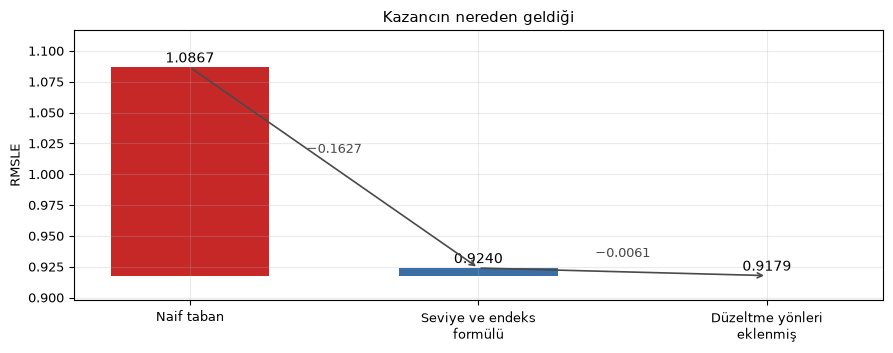

In [92]:
fig, ax = plt.subplots(figsize=(9.0, 3.6))
adim = [("Naif taban", float(np.sqrt(BLOK.katki.sum()))),
        ("Seviye ve endeks\nformülü", float(np.sqrt(TABAN_MSE))),
        ("Düzeltme yönleri\neklenmiş", float(np.sqrt(MSE_NIHAI)))]
taban_cizgi = adim[-1][1]
for j, (ad, v) in enumerate(adim):
    ax.bar(j, v - taban_cizgi, bottom=taban_cizgi, width=0.55,
           color=["#c62828", "#3a6ea5", "#2e7d32"][j])
    ax.text(j, v + 0.004, "%.4f" % v, ha="center", fontsize=10)
for j in range(len(adim) - 1):
    dus = adim[j][1] - adim[j + 1][1]
    ax.annotate("", xy=(j + 1, adim[j + 1][1]), xytext=(j, adim[j][1]),
                arrowprops=dict(arrowstyle="->", color="#4a4a4a", lw=1.2))
    ax.text(j + 0.5, (adim[j][1] + adim[j + 1][1]) / 2 + 0.012,
            "−%.4f" % dus, ha="center", fontsize=9, color="#4a4a4a")
ax.set_xticks(range(len(adim)))
ax.set_xticklabels([a for a, _ in adim], fontsize=9)
ax.set_ylabel("RMSLE")
ax.set_ylim(taban_cizgi - 0.02, adim[0][1] + 0.03)
ax.set_title("Kazancın nereden geldiği")
plt.tight_layout(); plt.show()

Şelale kazancın ağırlık merkezini gösteriyor. Naif tabandan
formüle inen basamak, formülden düzeltmelere inen basamağın kat kat
üstünde. Düzeltme yönleri gerçek bir şey taşıyor ama çözümün belkemiği
seviye ve endeks formülü; bunu olduğu gibi yazıyorum, çünkü tersi bir
izlenim yöntemin ağırlığını yanlış yere koyardı.

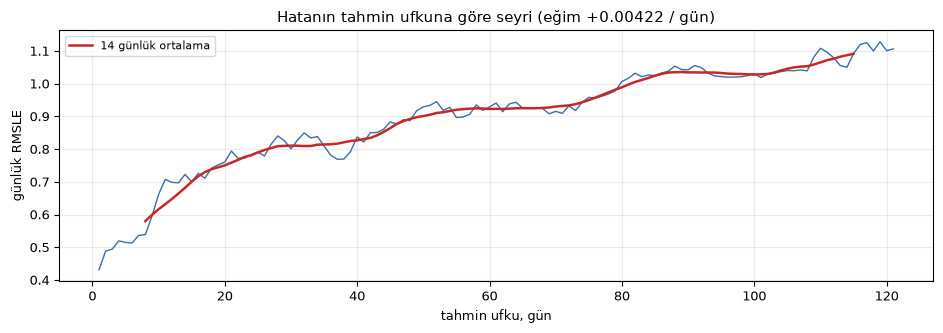

In [93]:
art2 = (D.L.to_numpy() - log_nihai) ** 2
gunluk = np.sqrt(pd.Series(art2, index=D.tarih.to_numpy()).groupby(level=0).mean())
ufuk_gun = (pd.Index(gunluk.index) - SINAMA).days

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.plot(ufuk_gun, gunluk.to_numpy(), color="#3a6ea5", lw=1.0)
ax.plot(ufuk_gun, pd.Series(gunluk.to_numpy()).rolling(14, center=True).mean(),
        color="#c62828", lw=1.8, label="14 günlük ortalama")
egim = np.polyfit(ufuk_gun, gunluk.to_numpy(), 1)[0]
ax.set_xlabel("tahmin ufku, gün")
ax.set_ylabel("günlük RMSLE")
ax.legend(fontsize=8)
ax.set_title("Hatanın tahmin ufkuna göre seyri (eğim %+.5f / gün)" % egim)
plt.tight_layout(); plt.show()

Hata tahmin ufkuyla birlikte büyüyor ve bu beklenen bir
davranış: trafonun kendi geçmişi bayatlıyor, bayatlık yasası tahmini
gruba çekiyor, grup ortalaması da tek bir trafo kadar keskin değil.
Grafiğin başlığındaki eğim günlük artışı veriyor. Gerçek testin ufku
dört ay olduğu için bu eğri doğrudan konuya değiyor: modelin en zayıf
olduğu yer tahmin penceresinin sonu.

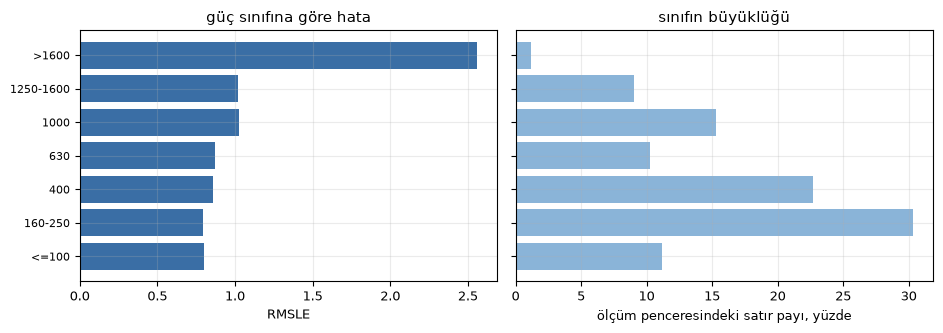

In [94]:
gs_d = pd.cut(D.guc, GUC_KENAR, labels=GUC_ETIKET)
GUC_HATA = pd.DataFrame({
    "RMSLE": np.sqrt(pd.Series(art2).groupby(gs_d.to_numpy(), observed=True).mean()),
    "satır payı": pd.Series(art2).groupby(gs_d.to_numpy(), observed=True).size() / len(D),
}).reindex(GUC_ETIKET).dropna()

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax[0].barh(range(len(GUC_HATA)), GUC_HATA["RMSLE"], color="#3a6ea5")
ax[0].set_yticks(range(len(GUC_HATA))); ax[0].set_yticklabels(GUC_HATA.index, fontsize=8)
ax[0].set_xlabel("RMSLE"); ax[0].set_title("güç sınıfına göre hata")
ax[1].barh(range(len(GUC_HATA)), 100 * GUC_HATA["satır payı"], color="#8ab4d8")
ax[1].set_yticks(range(len(GUC_HATA))); ax[1].set_yticklabels([])
ax[1].set_xlabel("ölçüm penceresindeki satır payı, yüzde")
ax[1].set_title("sınıfın büyüklüğü")
plt.tight_layout(); plt.show()

Hata güç sınıfları arasında eşit dağılmıyor. Küçük güçlü
trafolarda tüketim sıfıra yakın ve aralıklı, `log1p` uzayında oradaki
göreli hata büyük; büyük güçlü sanayi trafoları daha düzenli. Sağdaki
panel her sınıfın ölçüm penceresindeki payını veriyor, yani soldaki
hatanın toplam skora ne kadar ağırlıkla girdiğini.

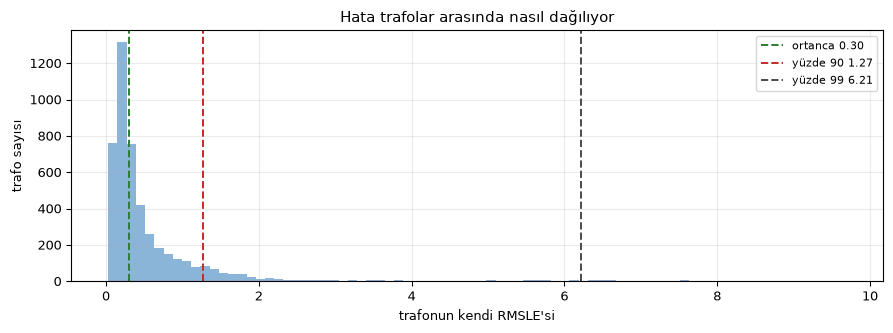

In [95]:
trafo_hata = np.sqrt(pd.Series(art2, index=D.tanim.to_numpy()).groupby(level=0).mean())
q = trafo_hata.quantile([0.5, 0.9, 0.99]).to_numpy()

fig, ax = plt.subplots(figsize=(9.0, 3.4))
ax.hist(trafo_hata, bins=80, color="#8ab4d8")
for v, ad, renk in ((q[0], "ortanca", "#2e7d32"), (q[1], "yüzde 90", "#c62828"),
                    (q[2], "yüzde 99", "#4a4a4a")):
    ax.axvline(v, color=renk, lw=1.4, ls="--", label="%s %.2f" % (ad, v))
ax.set_xlabel("trafonun kendi RMSLE'si"); ax.set_ylabel("trafo sayısı")
ax.legend(fontsize=8)
ax.set_title("Hata trafolar arasında nasıl dağılıyor")
plt.tight_layout(); plt.show()

Trafo bazında hata dağılımı sağa çok çarpık. Ortanca trafo
modelin ortalama performansının belirgin altında, ama üst yüzde birlik
kuyruk çok uzun. Yani ortalama skor birkaç yüz trafonun kötü tahmin
edilmesiyle taşınıyor. Bu kuyruğu kısaltmak, ortalama trafoyu biraz
daha iyi tahmin etmekten daha değerli olurdu.

Kat dışı kazanç kat içinin altında kalıyor ve aradaki fark
ezberin büyüklüğüdür. Kat dışı kazancın gürültü bandının üstünde olması
ise düzeltmelerin gerçek bir şey taşıdığını gösterir; bandın altında
kalsaydı kazanç ölçüm gürültüsünden ayırt edilemezdi.

Cross-sectional modelin eğitim ve doğrulama hataları birbirine yakın
durur. Tahminin standart sapmasının eğitiminkinin altında kalması ise
beklenen davranıştır; büzülme, kanıtı zayıf trafoları grup ortalamasına
çeker. Bu oranın bire yaklaşması kaygı verici olurdu, gerekçesi bölüm
7.2'de ölçülmüştür.

### 9.4 Tahmin Dağılımı

Dosyayı yazmadan önce iki şeye baktım:

* Biçim, kapsam ve aralık. Satır sayısı, id kümesi, tekrar, NaN, negatif. Hepsi ikili soru, `assert` ile kontrol ediyorum.
* Dağılım. Tahminin `log1p` uzayındaki ortalaması ve yayılımı, eğitimdekiyle karşılaştırmalı. Bu yargı gerektiriyor, o yüzden grafikle bakıyorum.

In [96]:
# Biçim denetimleri ikili soru, o yüzden assert: bir tanesi bile
# tutmazsa dosya yazılmış olsa bile notebook burada durur.
assert len(gonderim) == len(test), "satır sayısı test ile uyuşmuyor"
assert set(gonderim.id) == set(test.id), "id kümesi test ile uyuşmuyor"
assert gonderim.id.duplicated().sum() == 0, "tekrarlanan id var"
assert gonderim.tuketim.notna().all(), "NaN tahmin var"
assert np.isfinite(gonderim.tuketim).all(), "sonsuz tahmin var"
assert (gonderim.tuketim >= 0).all(), "negatif tahmin var"
print("biçim, kapsam ve aralık denetimleri: geçti")
print("satır %d | negatif 0 | NaN 0 | tekrarlanan id 0" % len(gonderim))
print("")

log_g = np.log1p(gonderim.tuketim.to_numpy())
print("tahmin  ortalama %.3f  sd %.3f  ortanca %.3f"
      % (log_g.mean(), log_g.std(), np.median(log_g)))
print("eğitim  ortalama %.3f  sd %.3f  ortanca %.3f"
      % (train.L.mean(), train.L.std(), train.L.median()))
print("tahmin sd / eğitim sd = %.3f" % (log_g.std() / train.L.std()))

biçim, kapsam ve aralık denetimleri: geçti
satır 714688 | negatif 0 | NaN 0 | tekrarlanan id 0

tahmin  ortalama 6.619  sd 1.666  ortanca 6.977
eğitim  ortalama 6.466  sd 2.147  ortanca 6.981
tahmin sd / eğitim sd = 0.776


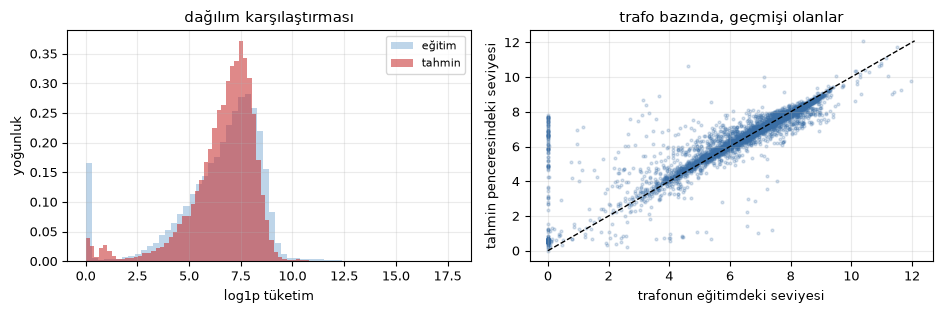

In [97]:
# Solda dağılım karşılaştırması, sağda trafo bazında geçmişteki
# seviye ile tahmin penceresindeki seviye. İkisi de büzülmeyi gösterir.
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].hist(train.L, bins=60, density=True, alpha=0.55, color="#8ab4d8", label="eğitim")
ax[0].hist(log_g, bins=60, density=True, alpha=0.55, color="#c62828", label="tahmin")
ax[0].set_xlabel("log1p tüketim"); ax[0].set_ylabel("yoğunluk")
ax[0].legend(fontsize=8); ax[0].set_title("dağılım karşılaştırması")

trafo_tahmin = pd.Series(log_g, index=test.tanim.to_numpy()).groupby(level=0).mean()
trafo_egitim = train.groupby("tanim").L.mean()
ortak_trafo = trafo_egitim.index.intersection(trafo_tahmin.index)
ax[1].scatter(trafo_egitim[ortak_trafo], trafo_tahmin[ortak_trafo],
              s=4, alpha=0.20, color="#3a6ea5")
lim = [0, max(trafo_egitim.max(), trafo_tahmin.max())]
ax[1].plot(lim, lim, color="k", lw=1, ls="--")
ax[1].set_xlabel("trafonun eğitimdeki seviyesi")
ax[1].set_ylabel("tahmin penceresindeki seviyesi")
ax[1].set_title("trafo bazında, geçmişi olanlar")
plt.tight_layout(); plt.show()

In [98]:
ZIRVE_BELLEK = max(ZIRVE_BELLEK, bellek_gb())
print("Zirve bellek %.1f GB." % ZIRVE_BELLEK)
print("Notebook baştan sona %.0f saniyede koştu." % (time.time() - BASLANGIC))

Zirve bellek 3.1 GB.
Notebook baştan sona 1443 saniyede koştu.


Tahminin yayılımı eğitiminkinin altında ve bunu bekliyordum.

* Büzülme, kanıtı zayıf trafoları grup önceliğine çekiyor. Tahminler bu yüzden gerçek değerlerden dar yayılıyor.
* Oranın bire yakın ya da üstünde çıkması kaygı verici olurdu. Bölüm 7.2'de gördüğüm gibi, hedefin yayılımını birebir üreten bir model genellikle hedefi bir yerden okuyordur.
* Sağdaki saçılımın uçlarda köşegenin içine bükülmesi de aynı büzülmenin izi, karesel kayıp altında beklenen bir davranış.

## 10. Sonuç

Bu bölüm çalışmadan çıkardığım dersleri, ölçülmüş ama denenmemiş
geliştirme yönlerini ve notebook'un yeniden üretilebilirliğini
özetler.

### 10.1 Yarışmadan Çıkardığım Dersler

Çalışmadan üç ders çıkardı. Üçü de bir sonraki tabular zaman serisi
probleminde ilk günden uygulayacağım şeylerdir.

Birincisi, hata seviyededir, dinamikte değildir. Trafonun ortalama
seviyesini bilseydim skor yarıya inerdi; günlük dalgalanmayı mükemmel
bilmek çok daha az kazandırırdı. Bunu bölüm 1.6'da kâhin sınırıyla
ölçtüm ve ondan sonra bütün çabayı seviye kestirimine ayırdım. Ölçmeden
başlasaydım zamanın çoğunu günlük dalgalanmaya harcayacaktım.

İkincisi, en pahalı satırlar en az bilgiye sahip olanlardır. Test
satırlarının beşte biri hiç görmediğim trafolara aittir ve naif hatanın
üçte ikisini taşır. O blok için ayrı bir cross-sectional model kurdum,
o modelin düzeltmesi üç zaman katının üçünde de aynı
işareti taşır ve nihai tahmin ediciye girer. Katsayısı küçüktür, çünkü
taban formülü grup önceliğiyle o bloğu zaten kabaca doğru yere koyar;
model o kaba tahmini inceltir, yerine geçmez.

Üçüncüsü, bir düzeltmenin ağırlığı ölçülür, seçilmez. Her düzeltme
fikrini bir yön vektörü olarak yazıp katsayısını kapalı formla çözmek
iki şey kazandırdı. Katsayı artık bir tercihin değil bir ölçümün
sonucudur, ve aynı çerçeve bir fikrin işe yaramadığını da kesin söyler.
Bölüm 8'deki kapanış listesi bu çerçevenin ürünüdür.

### 10.2 Geliştirme Yönleri

Yarışma bittiğinde ölçülmüş ama denenmemiş kalan yerler şunlar.
Sıralama beklenen kazanca göre değil, gerekçenin gücüne göre.

* Hava verisi beş ilin hepsi için ayrılabilir. Şu anki günlük tablo
  iki il için kurulu ve trafolar bu ikisine eşleniyor. Veri beş ili
  kapsıyor; her il kendi hava serisiyle bağlansaydı endeksin ilçe
  düzeyindeki artığı daralırdı.
* Endeks yalnız güç sınıfına göre katmanlı. Bölüm 1.4 soğutma
  duyarlılığının güç sınıfına göre değiştiğini ölçmüştü, ama coğrafi
  kırılım hiç denenmedi. Sahil ve iç kesim aynı endeksi paylaşıyor,
  oysa bölüm 4.2'de tatil sapmasının bu eksende ayrıştığı ölçüldü.
* Kesitsel model tek bir çıpa tarihinden eğitiliyor. Birden çok
  çıpa tarihinde üretilmiş kesitleri havuzlamak eğitim örneklemini
  birkaç katına çıkarır. Riski açık: aynı trafo birden çok kez girer ve
  bağımsızlık varsayımı bozulur, o yüzden kat şemasının trafo bazında
  gruplanması gerekir.
* Düzeltme katsayıları tek ve global. Ufka ya da güç sınıfına göre
  değişen katsayı denenmedi. Bölüm 6.4'ün kat 1 gözlemi, düzeltmelerin
  mevsime bağlı olabileceğini gösteriyor; katsayının mevsime göre
  değişmesine izin vermek doğal bir sonraki adım.
* Ölü trafo ve uyanma parametreleri panel genelinden ölçülüyor.
  Sulama trafolarının uyanma takvimi bölgeye göre değişiyor olmalı, ama
  bu ayrım ölçülmedi.

Bir de yöntem tarafında not düşeyim: bu çalışmada en çok zamanı,
kazandırdığını sandığım ama ölçünce kaybettiren fikirleri elemek aldı.
Kapalı formlu katsayı çözümü ve işaret kapısı bu elemeyi ucuzlattığı
için asıl kazanç oradan geldi, tek tek fikirlerden değil.

### 10.3 Yeniden Üretilebilirlik

Notebook kendi kendine yetiyor. Keşif, doğrulama şeması, endeks, seviye
formülü, kesitsel blok modeli, düzeltme yönleri ve katsayıların
cross-validation ile çözümü, hepsi burada. Yarışma verisi ile küçük bir
günlük hava ve takvim tablosundan başka girdi kullanmıyor, baştan sona
koşuyor ve `submission.csv` üretiyor.

Katsayıların tamamı kat döngüsü içinde, eğitim verisinin kendi zaman
katlarından çözülüyor (bölüm 6.4). Düzenlileştirme katsayısı `θ` da
aynı şekilde, kat dışı doğrulama hatasına bakılarak ızgaradan
seçiliyor.

Sahaya taşınması. Yöntemin çekirdeği, düzeltmelerin ağırlığını
geçmişin son diliminde çözüp ileriye uygulamak. Bir dağıtım şirketi
aynı şeyi geçen ayın gerçekleşmeleriyle yapabilir; formül değişmez,
yalnız artığın ölçüldüğü pencere kayar.